# **Notebook 2: Exploratory Data Analysis (EDA)**
This notebook uses the cleaned, non-one-hot-encoded dataset produced by NB1 to examine the distribution of High Depressive Symptoms (HDS) and Minimal to No Depressive Symptoms (MNDS) across selected demographic, family, psychosocial, educational, behavioral, and health-related variables.

The analysis includes descriptive statistics, feature-level visualizations, supplementary regional comparisons, and inferential statistical tests. Mann-Whitney U tests are used for selected numerical variables, while Chi-Square tests of independence are used for selected categorical variables. Additional analyses examine relationships among conceptually similar variables and correlations among genuinely numerical predictors.

The analyses in this notebook are descriptive and inferential and are intended to characterize patterns and associations in the data. They are not used as the basis for causal conclusions or as the final feature-selection procedure.

### **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu, f_oneway, spearmanr
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from pathlib import Path

plt.rcParams['figure.dpi'] = 120

### **Load Dataset**

In [2]:
PROJECT_ROOT = Path.cwd()
OUT_DIR = PROJECT_ROOT / "NB_OUTS1"

NCR_DATA_PATH = OUT_DIR / "NB1_data_EDA.csv"
NATIONAL_DATA_PATH = OUT_DIR / "NB1_national_context.csv"

assert NCR_DATA_PATH.exists(), f"Missing file: {NCR_DATA_PATH}"
assert NATIONAL_DATA_PATH.exists(), f"Missing file: {NATIONAL_DATA_PATH}"

df = pd.read_csv(NCR_DATA_PATH)
df['depressed_flag'] = df['depressed_flag'].astype(int)

df_national = pd.read_csv(NATIONAL_DATA_PATH)
df_national['depressed_flag'] = df_national['depressed_flag'].astype(int)

print("=== PRIMARY NCR DATASET ===")
print("Loaded shape:", df.shape)
print("depressed_flag present:", 'depressed_flag' in df.columns)
print("cesd present:", 'cesd' in df.columns)

print("\n=== NATIONAL CONTEXT DATASET ===")
print("Loaded shape:", df_national.shape)
print("Regions:", df_national['REG'].nunique())
print("depressed_flag present:", 'depressed_flag' in df_national.columns)

=== PRIMARY NCR DATASET ===
Loaded shape: (663, 155)
depressed_flag present: True
cesd present: False

=== NATIONAL CONTEXT DATASET ===
Loaded shape: (10949, 3)
Regions: 17
depressed_flag present: True


### **Confirm Key Dataset Properties**

In [3]:
print("=== Dataset Dimensions ===")
print(f"Respondents: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")
print(f"Non-target columns: {df.shape[1] - 1}")
print("Target column: depressed_flag")

print("\n=== Data Types ===")
print(df.dtypes.value_counts())

print("\n=== Missing Values After NB1 Cleaning ===")
missing = df.isnull().sum()
total_missing = missing.sum()
print(f"Total missing cells: {total_missing}")
if total_missing > 0:
    print("Columns still with missing values:")
    print(missing[missing > 0])
else:
    print("No missing values")

=== Dataset Dimensions ===
Respondents: 663
Total columns: 155
Non-target columns: 154
Target column: depressed_flag

=== Data Types ===
object     123
float64     31
int64        1
Name: count, dtype: int64

=== Missing Values After NB1 Cleaning ===
Total missing cells: 17743
Columns still with missing values:
G94       3
G95     498
G61     154
I102    413
B4_1      8
       ... 
A19       4
N12D    588
A26F    535
A26A    535
A26E    535
Length: 74, dtype: int64


### **Depression Distribution**

=== Depression Prevalence (NCR Sample) ===
Minimal to No Depressive Symptoms (0): 566  (85.4%)
High Depressive Symptoms          (1): 97  (14.6%)
Total: 663


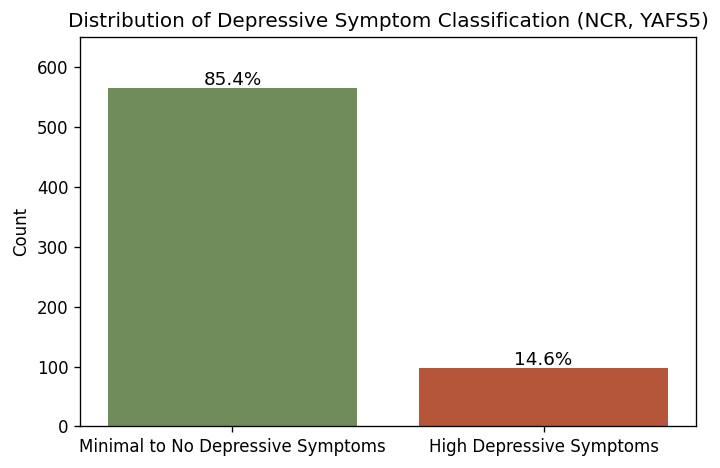

Saved: NB2_01_depression_distribution.png


In [4]:
depression_counts = df["depressed_flag"].value_counts().sort_index()
depression_rate   = df["depressed_flag"].value_counts(normalize=True) * 100

print("=== Depression Prevalence (NCR Sample) ===")
print(f"Minimal to No Depressive Symptoms (0): {depression_counts[0]}  ({depression_rate[0]:.1f}%)")
print(f"High Depressive Symptoms          (1): {depression_counts[1]}  ({depression_rate[1]:.1f}%)")
print(f"Total: {len(df)}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ['Minimal to No Depressive Symptoms', 'High Depressive Symptoms'],
    [depression_counts[0], depression_counts[1]],
    color=['#6F8C5A', '#B5553A']
)
for bar, pct in zip(bars, [depression_rate[0], depression_rate[1]]):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 5,
            f'{pct:.1f}%', ha='center', fontsize=11)

ax.set_title("Distribution of Depressive Symptom Classification (NCR, YAFS5)")
ax.set_ylabel("Count")
ax.set_ylim(0, max(depression_counts) * 1.15)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "NB2_01_depression_distribution.png"), bbox_inches='tight')
plt.show()
print("Saved: NB2_01_depression_distribution.png")

**SYNTHESIS:** The distribution shows that the majority of respondents in the NCR analytical sample are classified as having Minimal to No Depressive Symptoms (MNDS), accounting for **85.4%** of the sample, while **14.6%** are classified as having High Depressive Symptoms (HDS). Although HDS represents a smaller proportion, its presence indicates that a considerable subset of respondents in the sample experiences elevated depressive symptoms. The unequal distribution between the two outcome classes also establishes a class imbalance that must be considered during model development and evaluation. In particular, relying solely on overall accuracy may overstate model performance if predictions favor the majority MNDS class. Consequently, evaluation should also consider metrics such as recall, precision, F1-score, and ROC-AUC to provide a more comprehensive assessment of the models' ability to distinguish respondents with HDS.

### **Descriptive Statistics for Numeric Predictors**

In [5]:
numeric_summary = df.select_dtypes(include=np.number).describe().T
numeric_summary['missing'] = df.select_dtypes(include=np.number).isnull().sum()
print("Statistical summary of numeric predictors:")
print(numeric_summary.to_string())

Statistical summary of numeric predictors:
                count       mean        std        min        25%        50%        75%         max  missing
se_score        663.0  18.642534   3.392341   6.000000  17.000000  19.000000  21.000000   29.000000        0
C5              663.0   7.993967   1.998480   1.000000   7.000000   8.000000  10.000000   10.000000        0
sf_score        663.0   4.011124   0.499711   2.000000   3.750000   4.000000   4.375000    5.000000        0
C3              663.0   7.693816   1.893240   1.000000   7.000000   8.000000   9.000000   10.000000        0
I102            250.0   1.196000   2.025337   0.000000   1.000000   1.000000   1.000000   24.000000      413
I42             210.0  17.333333   2.496569  11.000000  16.000000  17.000000  19.000000   24.000000      453
G28              74.0  17.527027   2.680334  12.000000  15.250000  18.000000  19.000000   24.000000      589
J55              26.0  34.346154  32.230349  15.000000  18.000000  20.000000  22.0000

### **Supplementary Regional Analysis**

**Note:** Regional percentages shown below are descriptive sample proportions based on the available YAFS5 records. They should not be interpreted as population prevalence estimates unless the appropriate YAFS5 survey weights and sampling design are incorporated.

In [6]:
# Regional distribution of respondents
regional_counts = (df_national['REG'].value_counts().sort_values(ascending=False))
print("=== Respondents by Region ===")
print(regional_counts)

=== Respondents by Region ===
REG
Region 2 (Cagayan Valley)                      880
Region 13 (CARAGA)                             865
Region 10 (Northern Mindanao)                  762
Region 1 (Ilocos Region)                       701
Region 3 (Central Luzon)                       701
Region 8 (Eastern Visayas)                     690
Region 11 (Davao Region)                       690
Region 7 (Central Visayas)                     681
Cordillera Administrative Region (CAR)         676
National Capital Region (NCR)                  663
Region 6 (Western Visayas)                     662
Region 9 (Zamboanga Peninsula)                 644
Region 4A (CALABARZON)                         608
Region 5 (Bicol Region)                        503
Region 12 (SOCCSKSARGEN)                       445
Region 4B (MIMAROPA)                           402
Autonomous Region in Muslim Mindanao (ARMM)    376
Name: count, dtype: int64


**Regional HDS/MNDS Counts and Percentages**

In [7]:
regional_outcomes = (pd.crosstab(df_national['REG'], df_national['depressed_flag']).rename(columns={0: 'MNDS', 1: 'HDS'}))
regional_outcomes['Total'] = (regional_outcomes['MNDS'] + regional_outcomes['HDS'])
regional_outcomes['HDS (%)'] = (regional_outcomes['HDS'] / regional_outcomes['Total'] * 100)
regional_outcomes['MNDS (%)'] = (regional_outcomes['MNDS'] / regional_outcomes['Total'] * 100)
regional_outcomes = regional_outcomes.sort_values('HDS (%)',ascending=False)

print("=== Regional Depressive Symptom Classification ===")
display(regional_outcomes.round(2))

=== Regional Depressive Symptom Classification ===


depressed_flag,MNDS,HDS,Total,HDS (%),MNDS (%)
REG,,,,,
Region 7 (Central Visayas),507,174,681,25.55,74.45
Region 10 (Northern Mindanao),584,178,762,23.36,76.64
Autonomous Region in Muslim Mindanao (ARMM),297,79,376,21.01,78.99
Region 11 (Davao Region),570,120,690,17.39,82.61
National Capital Region (NCR),566,97,663,14.63,85.37
Region 4A (CALABARZON),528,80,608,13.16,86.84
Region 5 (Bicol Region),438,65,503,12.92,87.08
Region 4B (MIMAROPA),354,48,402,11.94,88.06
Cordillera Administrative Region (CAR),603,73,676,10.80,89.20


**Regional HDS Percentage Graph**

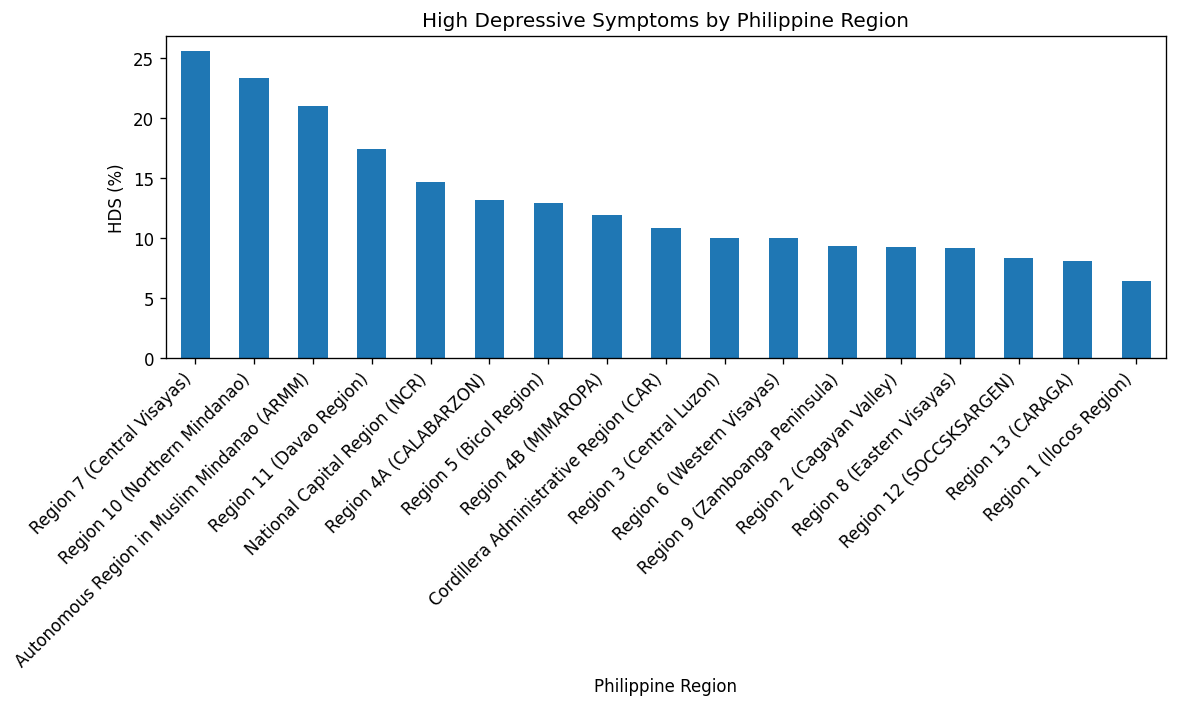

Saved: /home/abigailching/Thesis/Outputs/NB2_regional_HDS_rate.png


In [8]:
regional_rate = (df_national.groupby('REG')['depressed_flag'].mean().mul(100).sort_values(ascending=False))
plt.figure(figsize=(10, 6))

ax = regional_rate.plot(kind='bar')
ax.set_xlabel("Philippine Region")
ax.set_ylabel("HDS (%)")
ax.set_title("High Depressive Symptoms by Philippine Region")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

regional_plot_path = os.path.join(OUT_DIR,"NB2_regional_HDS_rate.png")
plt.savefig(regional_plot_path,bbox_inches='tight')
plt.show()
print(f"Saved: {regional_plot_path}")

**SYNTHESIS:** The descriptive regional comparison shows variation in the proportion of respondents classified as having High Depressive Symptoms (HDS) across the Philippine regions represented in YAFS5. NCR does not exhibit the highest observed HDS proportion among the regions. However, this regional comparison is included only to provide descriptive context and is not used to determine the geographic scope of the predictive analysis. The primary analysis remains focused on NCR youth in accordance with the study's predefined geographic delimitation. Furthermore, these percentages represent unweighted sample proportions and should not be interpreted as regional population prevalence estimates.

### **Helper Functions**

These functions are created so that we won't have to repeatedly write the same code when visualizing each feature.

**Bar graph for categorical columns**

In [9]:
def plot_depression_rate(feature, title=None, save_name=None):
    if feature not in df.columns:
        print(f"WARNING: '{feature}' not in dataset — skipping.")
        return None
    temp = (pd.crosstab(df[feature], df["depressed_flag"], normalize="index") * 100)
    if 1 not in temp.columns:
        print(f"WARNING: no depressed_flag cases found for '{feature}' — skipping.")
        return None
    temp = temp.sort_values(1, ascending=False)
    label = title or feature

    # Significance test
    table = pd.crosstab(df[feature], df["depressed_flag"])
    chi2_val, p_val, _, _ = chi2_contingency(table)
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(temp.index.astype(str), temp[1], color='#4F7C82')
    ax.set_ylabel("% Showing High Depressive Symptoms")
    ax.set_xlabel(feature)
    ax.set_title(f"{label} vs High Depressive Symptoms Rate (%)")
    fig.text(0.5, -0.02, f"Chi-square test: p = {p_val:.4f} ({sig})", ha="center", fontsize=9)
    
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.5,
                f"{height:.1f}%", ha='center', va='bottom', fontsize=9)
    plt.xticks(rotation=20, ha='center')
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    if save_name:
        plt.savefig(os.path.join(OUT_DIR, save_name), bbox_inches='tight')
        print(f"Saved: {save_name}")
    plt.show()
    return temp

**Box plot for numeric columns**

In [10]:
def boxplot(feature, title=None, note=None, save_name=None):
    if feature not in df.columns:
        print(f"WARNING: '{feature}' not in dataset — skipping.")
        return
    dep = df.loc[df["depressed_flag"] == 1, feature].dropna()
    non = df.loc[df["depressed_flag"] == 0, feature].dropna()
    label = title or feature

    # Significance test
    stat, p_val = mannwhitneyu(dep, non, alternative="two-sided")
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.boxplot(data=df, x="depressed_flag", y=feature,
                hue="depressed_flag",
                palette={0: '#6F8C5A', 1: '#B5553A'},
                legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Minimal to No Depressive Symptoms', 'High Depressive Symptoms'])
    ax.set_title(f"{label} by Depressive Symptom Classification")
    fig.text(0.5, -0.02, f"Mann-Whitney U test: p = {p_val:.4f} ({sig})", ha="center", fontsize=9)
    if note:
        ax.set_xlabel(note)
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    if save_name:
        plt.savefig(os.path.join(OUT_DIR, save_name), bbox_inches='tight')
        print(f"Saved: {save_name}")
    plt.show()

**Stacked bar graph for binary columns**

In [11]:
def plot_stacked_depression(feature, title=None, save_name=None):
    if feature not in df.columns:
        print(f"WARNING: '{feature}' not in dataset — skipping.")
        return None
    temp = (pd.crosstab(df[feature], df["depressed_flag"], normalize="index") * 100)
    if 1 not in temp.columns:
        print(f"WARNING: no depressed_flag cases found for '{feature}' — skipping.")
        return None
    temp = temp.sort_values(1, ascending=False)
    counts = pd.crosstab(df[feature], df["depressed_flag"])
    counts = counts.loc[temp.index]
    label = title or feature

    # Significance test
    table = pd.crosstab(df[feature], df["depressed_flag"])
    chi2_val, p_val, _, _ = chi2_contingency(table)
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"

    fig, ax = plt.subplots(figsize=(10, 6))
    counts.plot(kind="bar", stacked=True, ax=ax, color=["#6F8C5A", "#B5553A"])
    ax.set_ylabel("Number of Respondents")
    ax.set_xlabel(feature)
    ax.set_title(f"{label} vs High Depressive Symptoms Rate (%)")
    fig.text(0.5, -0.02, f"Chi-square test: p = {p_val:.4f} ({sig})", ha="center", fontsize=9)
    ax.legend(["Minimal to No Depressive Symptoms", "High Depressive Symptoms"],
              title="Depression Status")
    for container in ax.containers:
        ax.bar_label(container, label_type="center", fontsize=9, color="white")
    totals = counts.sum(axis=1)
    for i, category in enumerate(counts.index):
        dep_pct = temp.loc[category, 1]
        ax.text(i, totals.loc[category] + totals.max() * 0.02,
                f"{dep_pct:.1f}%", ha="center", va="bottom", fontsize=9)
    plt.xticks(rotation=0, ha="center")
    plt.tight_layout(rect=[0, 0.04, 1, 1])
    if save_name:
        plt.savefig(os.path.join(OUT_DIR, save_name), bbox_inches="tight")
        print(f"Saved: {save_name}")
    plt.show()
    return temp

### **EDA by Theme**

**Theme 1: Socio-demographic Profile**

Saved: NB2_02_sex_vs_depression.png


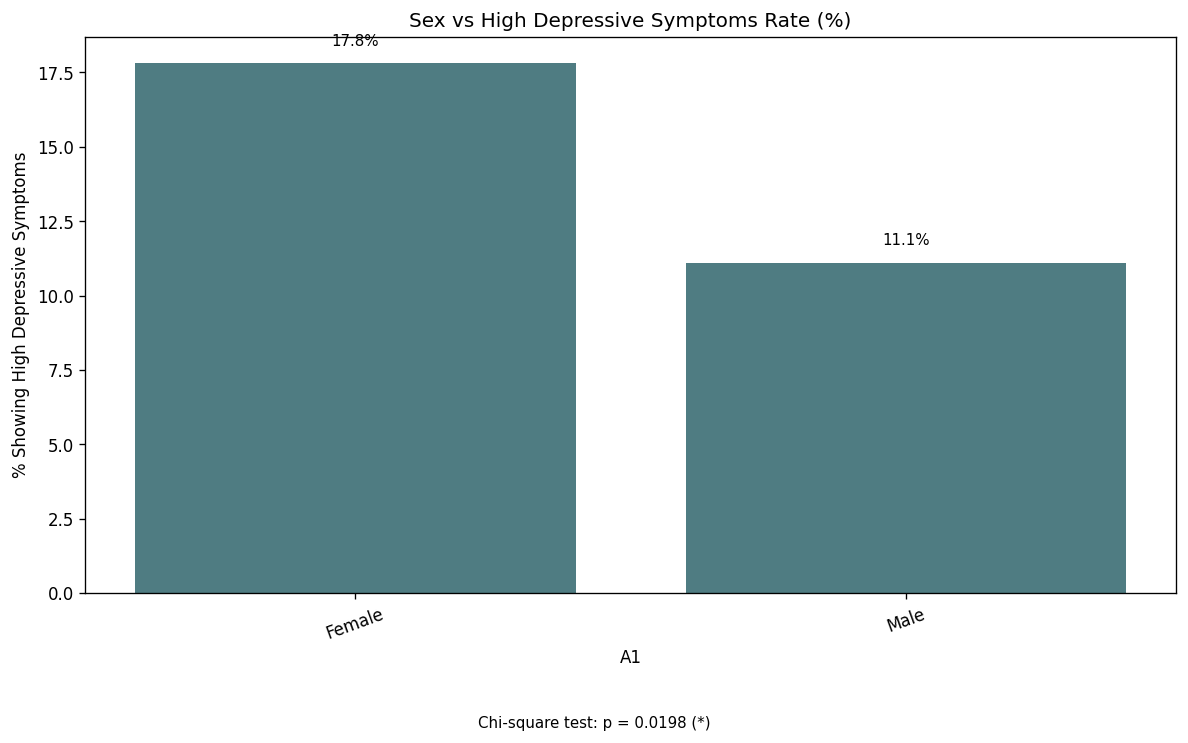

depressed_flag,0,1
A1,,
Female,82.183908,17.816092
Male,88.888889,11.111111


In [12]:
# Sex (A1)
plot_depression_rate("A1", title="Sex", save_name="NB2_02_sex_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications indicates a difference between female and male respondents. Among females, 17.82% were classified as having High Depressive Symptoms (HDS), compared with 11.11% among males, representing a difference of 6.71 percentage points. Conversely, a larger proportion of male respondents (88.89%) were classified as having Minimal to No Depressive Symptoms (MNDS), compared with females (82.18%). These descriptive findings suggest that HDS is more prevalent among female respondents within the NCR analytical sample. This difference indicates that sex may be a relevant demographic characteristic to examine in relation to depressive symptoms. However, the observed pattern does not establish that sex directly causes differences in depressive symptoms, nor does it account for other demographic, social, or psychological characteristics that may be related to the outcome.

Saved: NB2_03_age_vs_depression.png


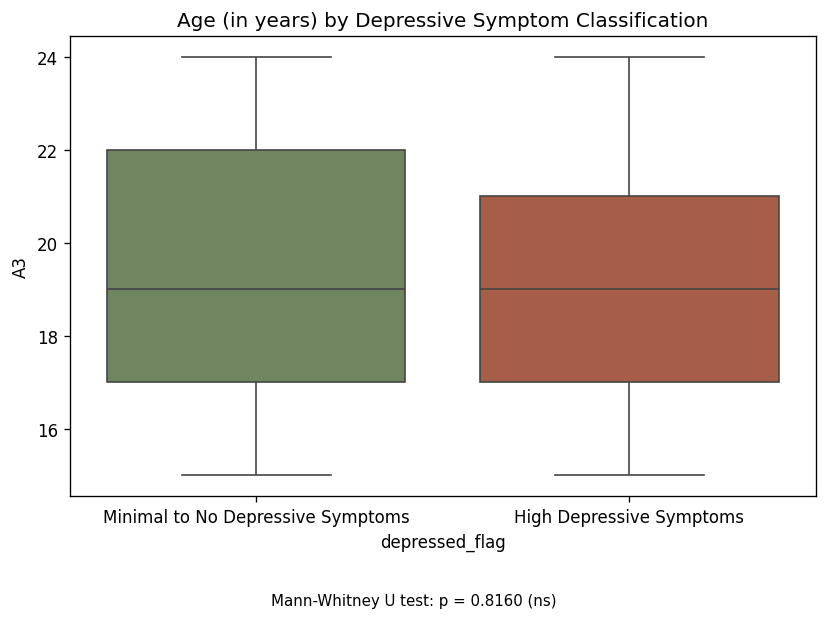

In [13]:
# Age (A3)
boxplot("A3", title="Age (in years)", save_name="NB2_03_age_vs_depression.png")

**SYNTHESIS:** The age distributions of respondents classified as having Minimal to No Depressive Symptoms (MNDS) and High Depressive Symptoms (HDS) appear highly similar. Both groups have a median age of 19 years, with their middle 50% of observations concentrated between approximately 17 and 22 years for MNDS and 17 and 21 years for HDS. The overall age ranges are also comparable, extending from 15 to 24 years in both groups. This visual similarity is supported by the Mann-Whitney U test, which yielded a p-value of 0.816, indicating no statistically significant difference in age distributions between the two depressive symptom classifications. These findings suggest that, within the NCR analytical sample, age alone does not demonstrate a meaningful difference in the distribution of depressive symptom classifications. However, this does not establish that age is unrelated to depressive symptoms in all contexts, particularly when considered alongside other demographic and psychosocial characteristics.

Saved: NB2_04_main_activity_vs_depression.png


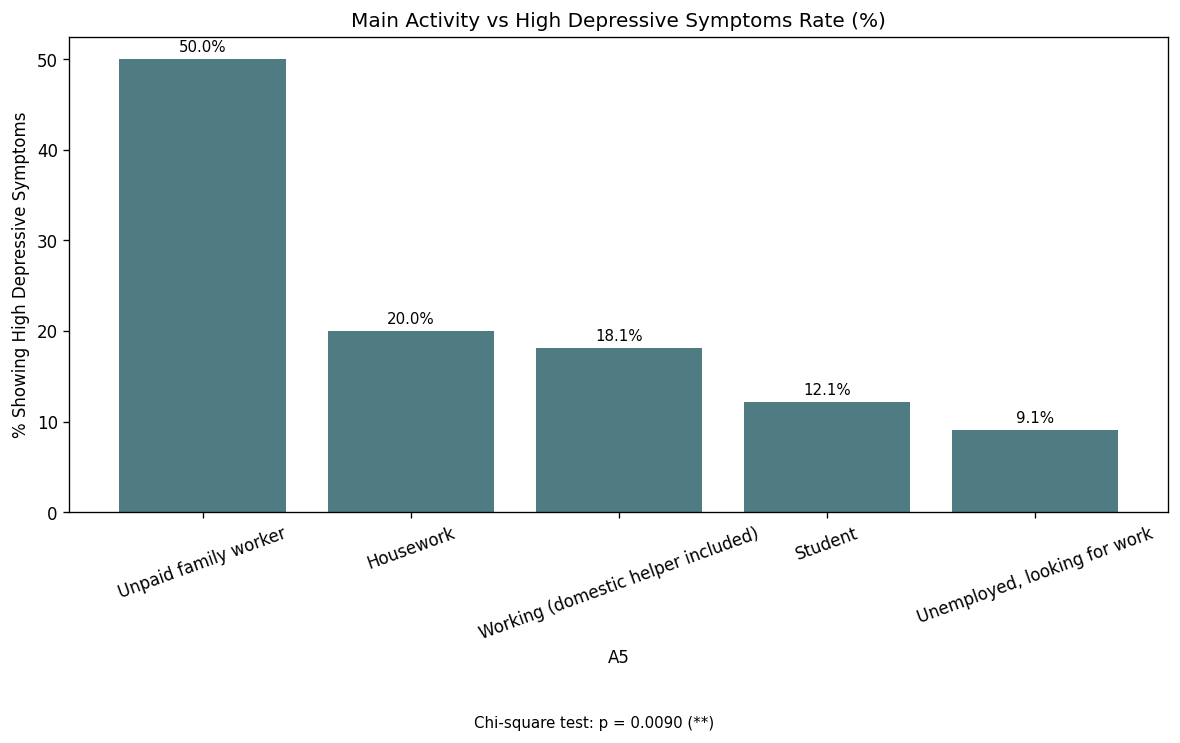

depressed_flag,0,1
A5,,
Unpaid family worker,50.000000,50.000000
Housework,80.000000,20.000000
Working (domestic helper included),81.920904,18.079096
Student,87.862797,12.137203
"Unemployed, looking for work",90.909091,9.090909


In [14]:
# Main Activity (employment/study status) (A5)
plot_depression_rate("A5", title="Main Activity", save_name="NB2_04_main_activity_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications varies across respondents' main activity categories. Unpaid family workers exhibit the highest observed proportion of High Depressive Symptoms (HDS), at 50.00%, followed by respondents engaged in housework at 20.00% and those who are working, including domestic helpers, at 18.08%. In comparison, students and unemployed respondents looking for work have lower HDS proportions of 12.14% and 9.09%, respectively. Although unpaid family workers have the highest percentage, this finding should be interpreted cautiously because the category contains only eight respondents, making its observed proportion more sensitive to small changes in the sample. Meanwhile, students account for the largest number of HDS respondents due to their substantial representation in the analytical sample. These findings suggest that the distribution of depressive symptoms differs across main activity categories; however, the observed patterns do not establish a direct relationship between activity status and depressive symptoms. Other demographic, socioeconomic, and personal circumstances may also contribute to the differences and warrant further examination.

Saved: NB2_05_religion_vs_depression.png


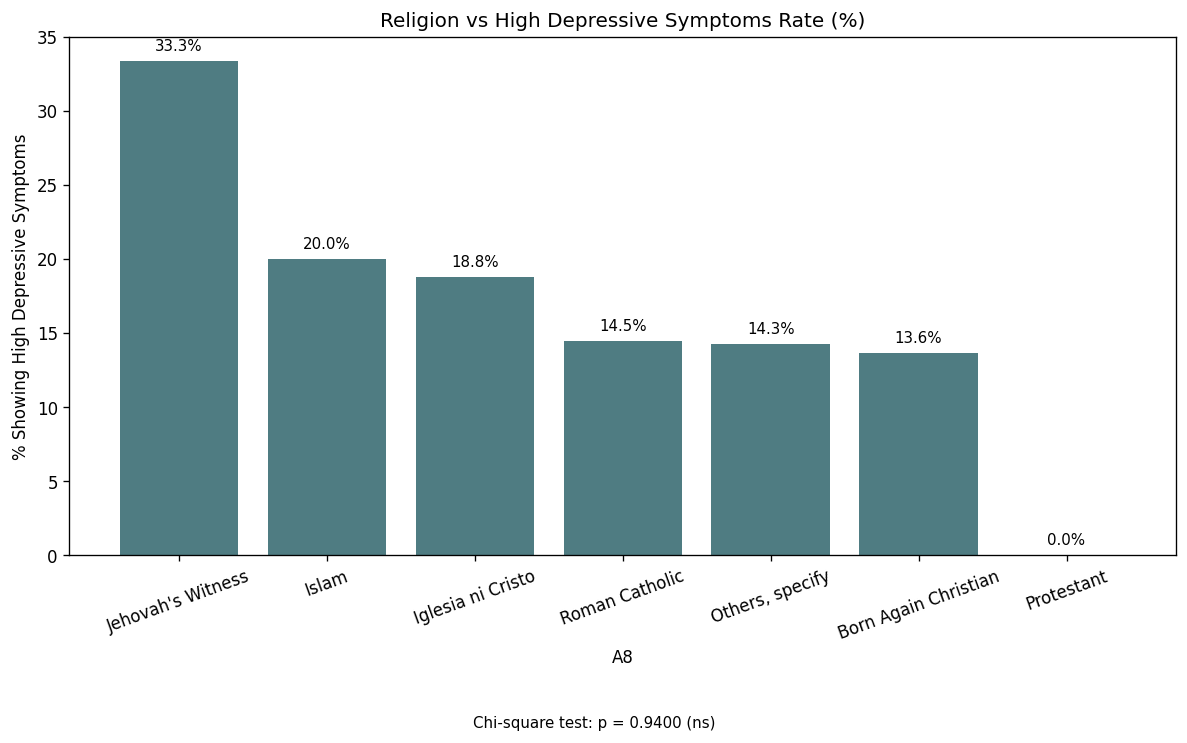

depressed_flag,0,1
A8,,
Jehovah's Witness,66.666667,33.333333
Islam,80.000000,20.000000
Iglesia ni Cristo,81.250000,18.750000
Roman Catholic,85.512367,14.487633
"Others, specify",85.714286,14.285714
Born Again Christian,86.363636,13.636364
Protestant,100.000000,0.000000


In [15]:
# Religion (A8)
plot_depression_rate("A8", title="Religion", save_name="NB2_05_religion_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications varies across religious affiliations within the NCR analytical sample. Jehovah's Witness respondents exhibit the highest observed proportion of High Depressive Symptoms (HDS), at 33.33%, followed by respondents identifying as Muslim (20.00%) and Iglesia ni Cristo (18.75%). In contrast, Protestant respondents have an observed HDS proportion of 0%, while the remaining religious groups show proportions ranging from approximately 13.64% to 14.49%. Despite these differences, most religious groups exhibit relatively similar HDS proportions, generally falling between 13% and 20%. The higher percentage observed among Jehovah's Witness respondents and the absence of HDS cases among Protestant respondents should be interpreted cautiously, as the sizes of these subgroups may influence their observed proportions. Overall, the descriptive findings indicate variation in HDS across religious affiliations, but they do not establish that religious affiliation itself is associated with or influences depressive symptoms.

Saved: NB2_06_religious_attendance_vs_depression.png


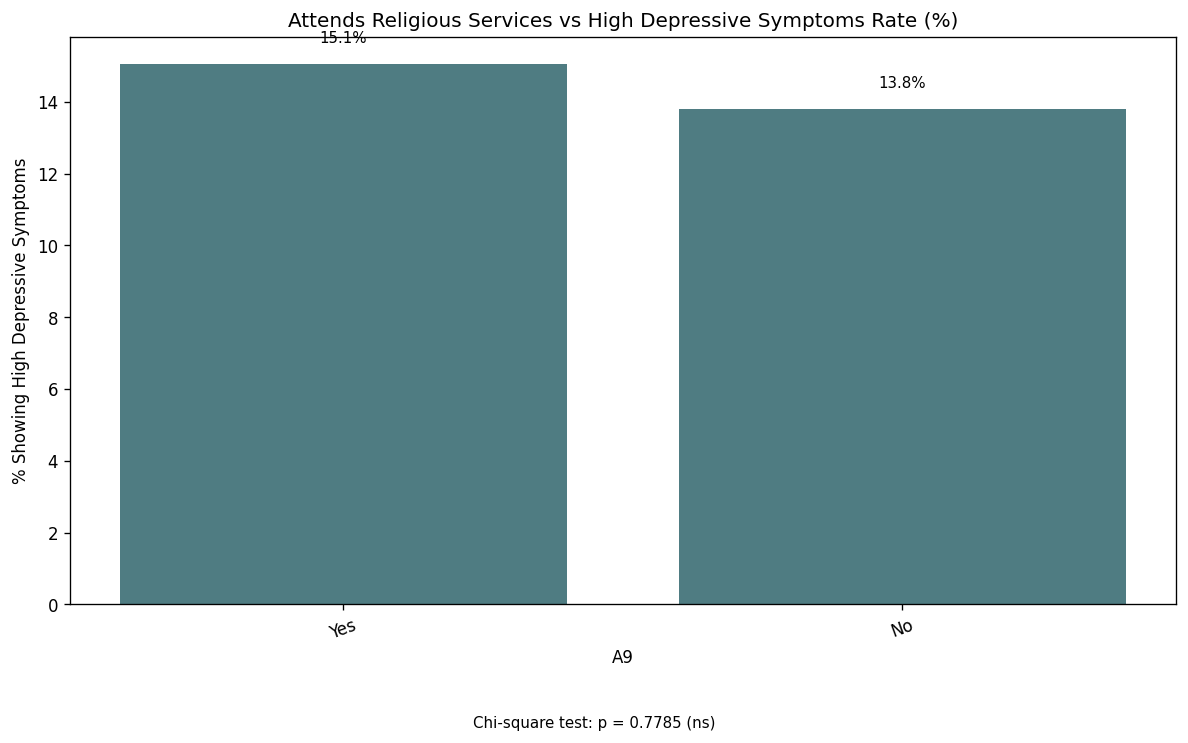

depressed_flag,0,1
A9,,
Yes,84.937238,15.062762
No,86.187845,13.812155


In [16]:
# Attend religious services (A9)
plot_depression_rate("A9", title="Attends Religious Services", save_name="NB2_06_religious_attendance_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications is relatively similar between respondents who attend religious services and those who do not. Among respondents who reported attending religious services, 15.06% were classified as having High Depressive Symptoms (HDS), compared with 13.81% among those who reported not attending, representing a relatively small difference of 1.25 percentage points. The statistical significance test also indicated that the observed difference was not statistically significant. This suggests that, within the NCR analytical sample, attendance at religious services does not demonstrate a statistically significant association with depressive symptom classification. However, this finding should not be interpreted as evidence that religious involvement has no relevance to mental health, since attendance alone may not capture other dimensions of religious participation, such as the level of personal engagement, perceived social support, or individual experiences. Overall, the results indicate that attendance at religious services, when considered on its own, does not distinguish respondents with HDS from those with MNDS in a statistically significant manner.

Saved: NB2_07_mobility_vs_depression.png


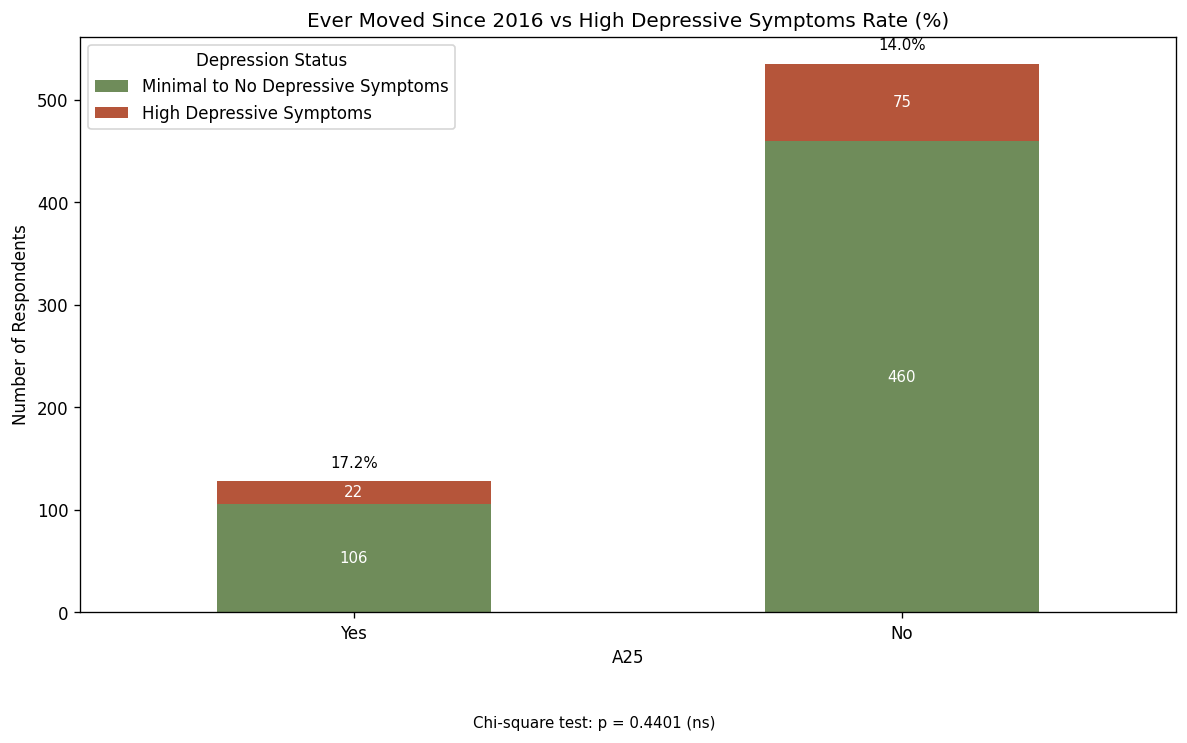

depressed_flag,0,1
A25,,
Yes,82.812500,17.187500
No,85.981308,14.018692


In [17]:
# Ever moved since 2016 (A25)
plot_stacked_depression("A25", title="Ever Moved Since 2016", save_name="NB2_07_mobility_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications shows a modest difference between respondents who have moved residences since 2016 and those who have not. Among respondents who reported having moved, 17.19% were classified as having High Depressive Symptoms (HDS), compared with 14.02% among those who had not moved, representing a difference of 3.17 percentage points. Although the proportion is slightly higher among respondents who experienced residential mobility, the observed difference alone does not establish that moving residences is associated with depressive symptoms. Residential mobility may involve changes in one's living environment, social surroundings, or access to familiar support networks; however, these circumstances are not directly measured by this comparison. Therefore, the result should be interpreted as a descriptive difference that warrants consideration alongside other demographic and psychosocial characteristics rather than as evidence of a direct relationship between residential mobility and depressive symptoms.

Saved: NB2_08_lived_away_vs_depression.png


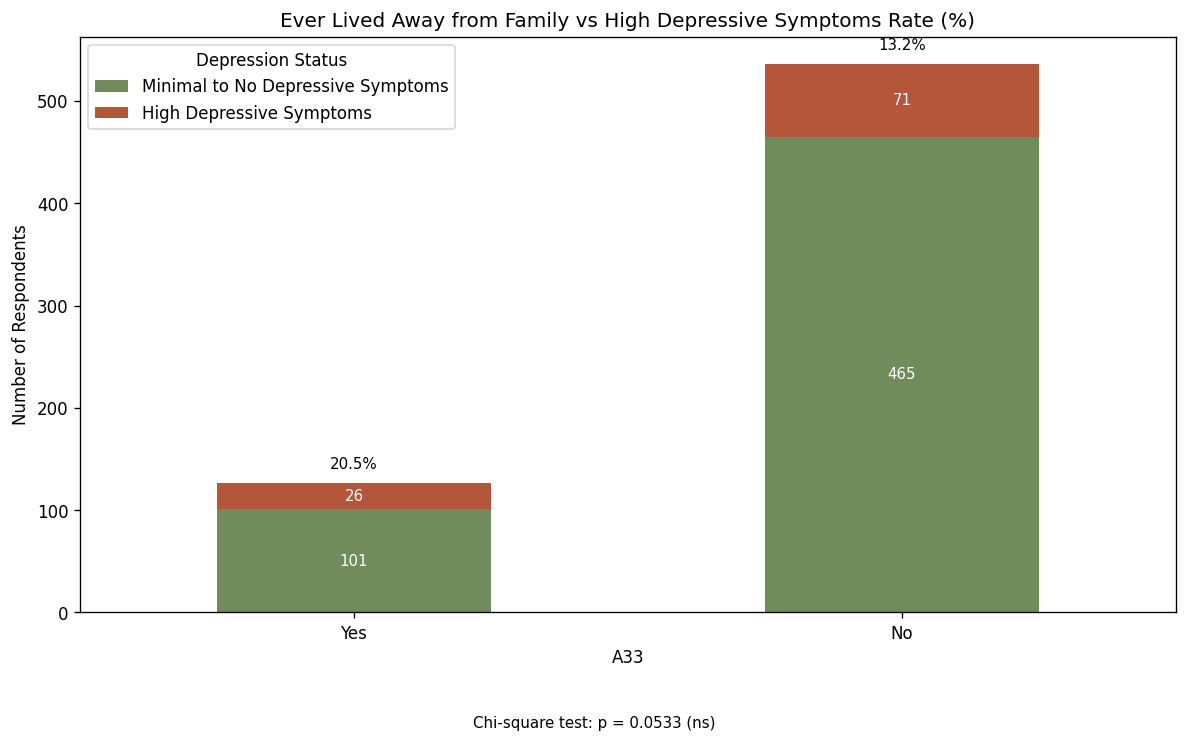

depressed_flag,0,1
A33,,
Yes,79.527559,20.472441
No,86.753731,13.246269


In [18]:
# Ever lived away from family (A33)
plot_stacked_depression("A33", title="Ever Lived Away from Family", save_name="NB2_08_lived_away_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications shows a noticeable descriptive difference between respondents who have lived away from their families and those who have not. Among respondents who reported having lived away from their families, 20.47% were classified as having High Depressive Symptoms (HDS), compared with 13.25% among those who had never lived away, representing a difference of approximately 7.22 percentage points. Although this pattern suggests a higher observed proportion of HDS among respondents who have experienced living away from their families, the Chi-square test yielded a p-value of 0.053, which does not meet the conventional 5% significance threshold. Therefore, the results do not provide sufficient statistical evidence to establish an association between having lived away from family and depressive symptom classification. Nevertheless, the observed difference may warrant further examination, as living away from family can involve changes in family interaction, access to familiar support systems, and one's social environment. These factors, however, cannot be established from this descriptive comparison alone.

Saved: NB2_09_education_vs_depression.png


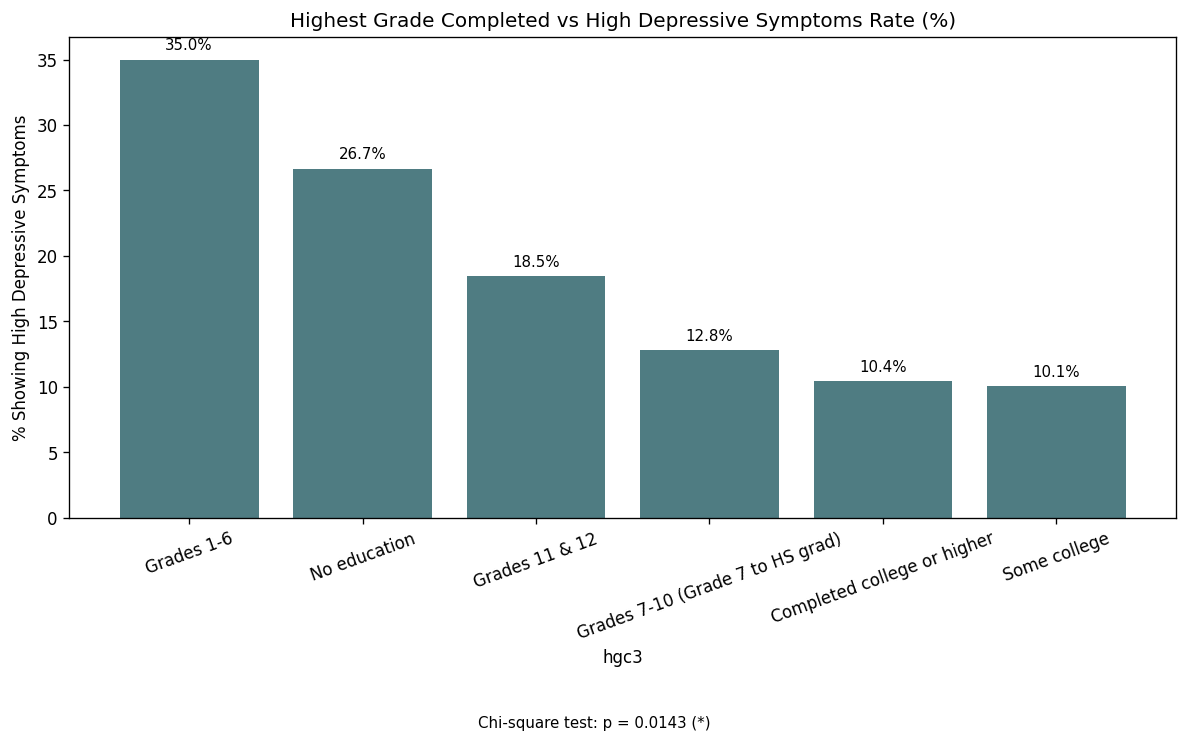

depressed_flag,0,1
hgc3,,
Grades 1-6,65.000000,35.000000
No education,73.333333,26.666667
Grades 11 & 12,81.521739,18.478261
Grades 7-10 (Grade 7 to HS grad),87.159533,12.840467
Completed college or higher,89.583333,10.416667
Some college,89.928058,10.071942


In [19]:
# Highest grade completed (hgc3)
plot_depression_rate("hgc3", title="Highest Grade Completed", save_name="NB2_09_education_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies across educational attainment categories, with a general pattern of lower HDS proportions among respondents who have completed higher levels of education. Respondents who completed Grades 1–6 exhibit the highest HDS proportion at 35.00%, followed by those with no formal education at 26.67% and those who completed Grades 11 and 12 at 18.48%. In comparison, respondents who completed Grades 7–10 have an HDS proportion of 12.84%, while those with some college education and a completed college degree or higher have lower proportions of 10.07% and 10.42%, respectively. The Chi-square test yielded a p-value of 0.014, indicating a statistically significant association between educational attainment and depressive symptom classification at the 5% significance level. These findings suggest that educational attainment is an important characteristic to consider when examining patterns of depressive symptoms among Filipino youth in NCR. However, the observed association does not establish that higher educational attainment directly reduces depressive symptoms, as other socioeconomic, family, and individual circumstances may also contribute to the differences across educational groups.

Saved: NB2_10_wealth_index_vs_depression.png


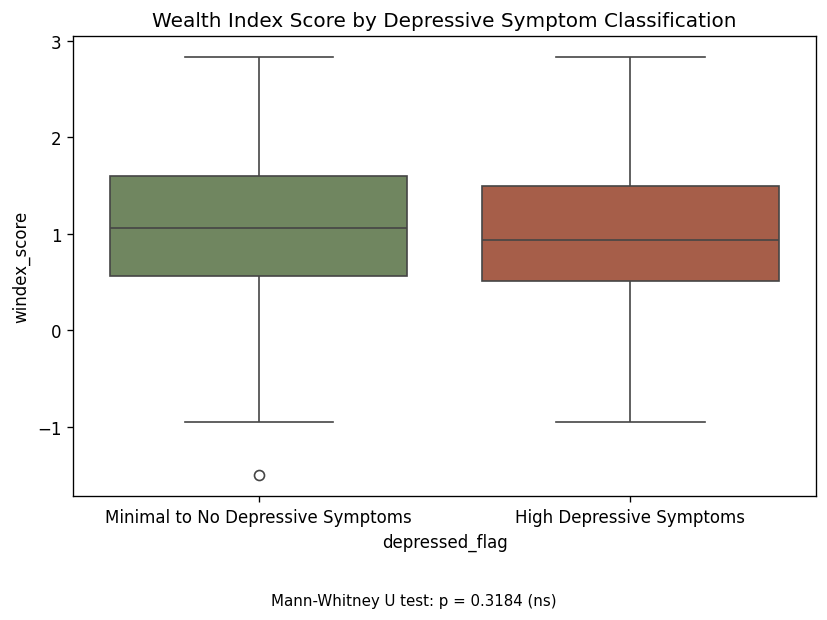

In [20]:
# Wealth Index (windex_score)
boxplot("windex_score", title="Wealth Index Score", save_name="NB2_10_wealth_index_vs_depression.png")

**SYNTHESIS:** The distribution of household wealth index scores is relatively similar between respondents classified as having Minimal to No Depressive Symptoms (MNDS) and those with High Depressive Symptoms (HDS). The MNDS group exhibits a slightly higher median wealth index score than the HDS group, although the interquartile ranges of both groups overlap considerably, indicating similar distributions across their middle 50% of observations. This visual similarity is supported by the Mann-Whitney U test, which yielded a p-value of 0.318, indicating no statistically significant difference in wealth index score distributions between the two depressive symptom classifications. These findings suggest that household wealth index score, when examined independently, does not demonstrate a meaningful distinction between respondents with HDS and MNDS in the NCR analytical sample. However, this does not establish that socioeconomic circumstances are unrelated to depressive symptoms, as the wealth index represents only one dimension of socioeconomic status and does not capture other factors such as financial insecurity, household obligations, or access to resources.

**Theme 2: Family and Home Environment**

Saved: NB2_11_sibling_relations_vs_depression.png


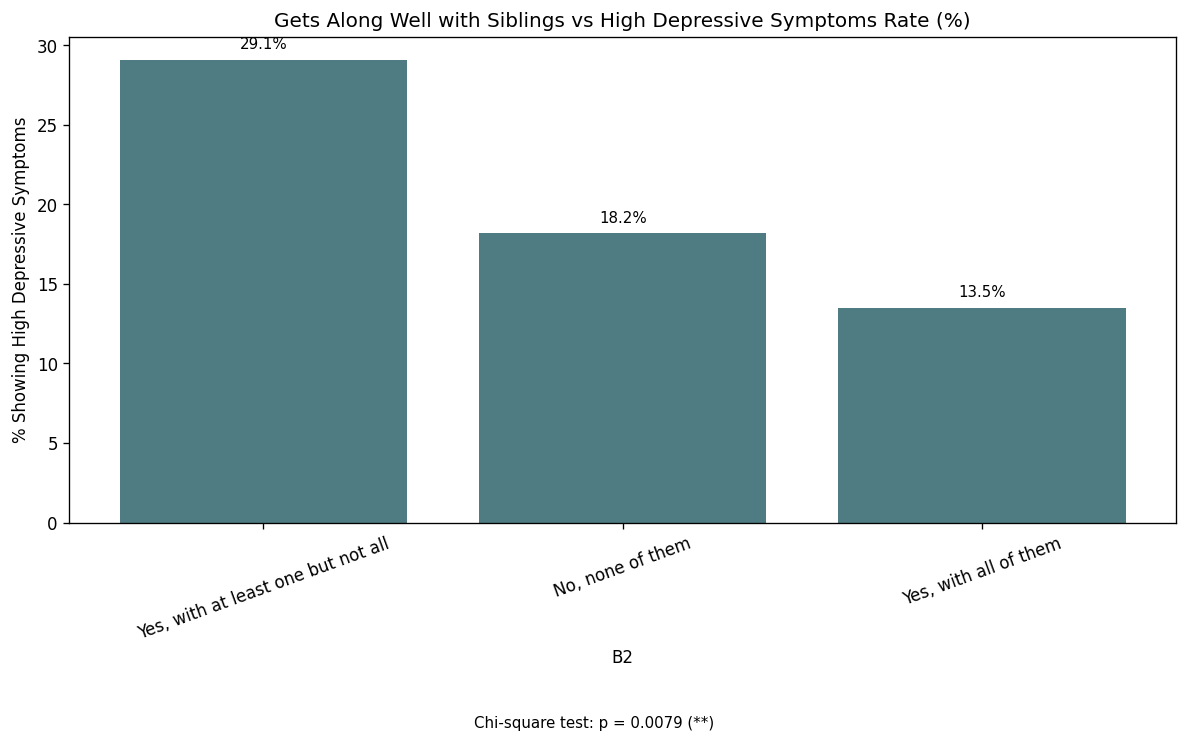

depressed_flag,0,1
B2,,
"Yes, with at least one but not all",70.909091,29.090909
"No, none of them",81.818182,18.181818
"Yes, with all of them",86.481802,13.518198


In [21]:
# Gets along with siblings (B2)
plot_depression_rate("B2", title="Gets Along Well with Siblings", save_name="NB2_11_sibling_relations_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications varies across respondents' reported relationships with their siblings. Respondents who reported getting along with at least one sibling but not all exhibited the highest proportion of High Depressive Symptoms (HDS), at 29.09%, followed by those who reported not getting along with any of their siblings at 18.18%. In comparison, respondents who reported getting along with all their siblings had the lowest HDS proportion, at 13.52%. The difference between the highest and lowest proportions is approximately 15.57 percentage points. The Chi-square test yielded a p-value of 0.008, indicating a statistically significant association between sibling relationship category and depressive symptom classification. These findings suggest that the reported quality or extent of sibling relationships may be relevant when examining patterns of depressive symptoms among Filipino youth in NCR. However, the higher HDS proportion among respondents who get along with some but not all of their siblings indicates that the relationship is not necessarily linear. The results do not establish that sibling relationships directly influence depressive symptoms, as other family and individual circumstances may also contribute to the observed differences.

Saved: NB2_12_parents_together_vs_depression.png


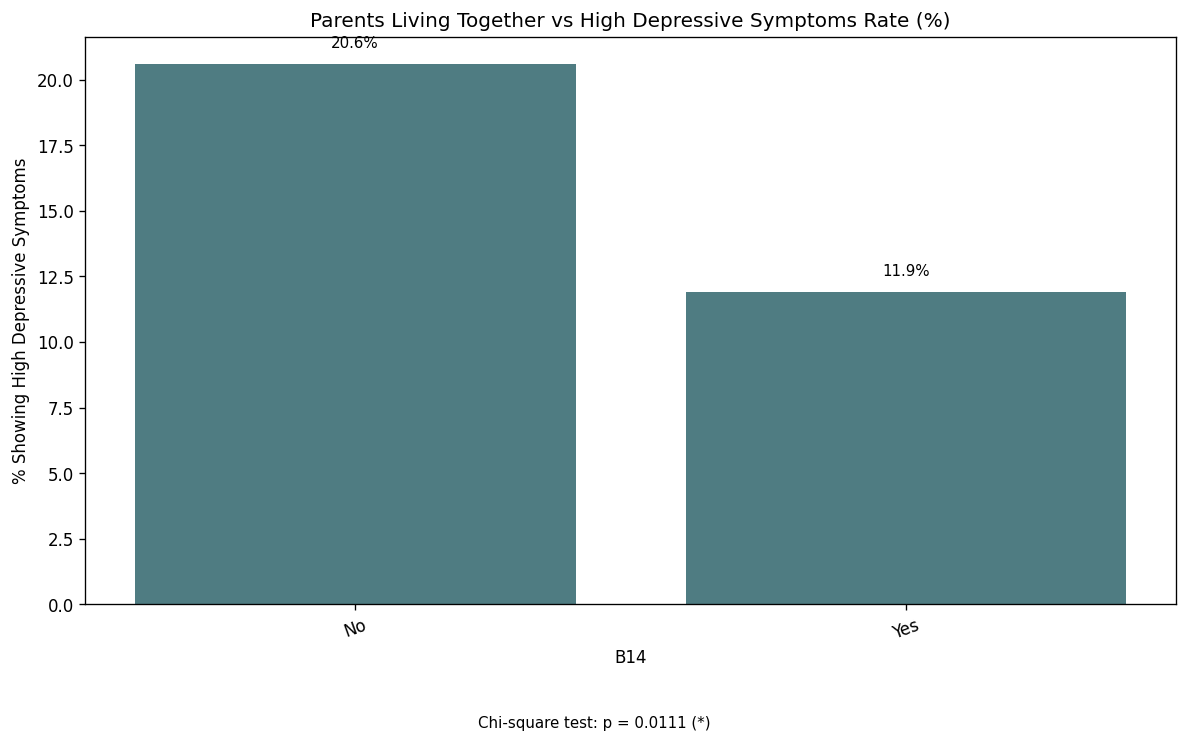

depressed_flag,0,1
B14,,
No,79.393939,20.606061
Yes,88.101266,11.898734


In [22]:
# Parents living together (B14)
plot_depression_rate("B14", title="Parents Living Together", save_name="NB2_12_parents_together_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classifications differs between respondents whose parents live together and those whose parents do not. Respondents whose parents do not live together exhibit a higher proportion of High Depressive Symptoms (HDS), at 20.61%, compared with 11.90% among respondents whose parents live together, representing a difference of approximately 8.71 percentage points. The Chi-square test yielded a p-value of 0.011, indicating a statistically significant association between parental co-residence and depressive symptom classification at the 5% significance level. These findings suggest that parental living arrangements may be a relevant family characteristic when examining patterns of depressive symptoms among Filipino youth in NCR. However, parental co-residence alone does not fully represent the quality or stability of the family environment, as it does not account for factors such as family relationships, household conflict, or the availability of emotional support. Therefore, the observed association should be interpreted in the context of broader family and individual circumstances rather than as evidence that parental living arrangements directly determine depressive symptoms.

Saved: NB2_13_parents_relations_vs_depression.png


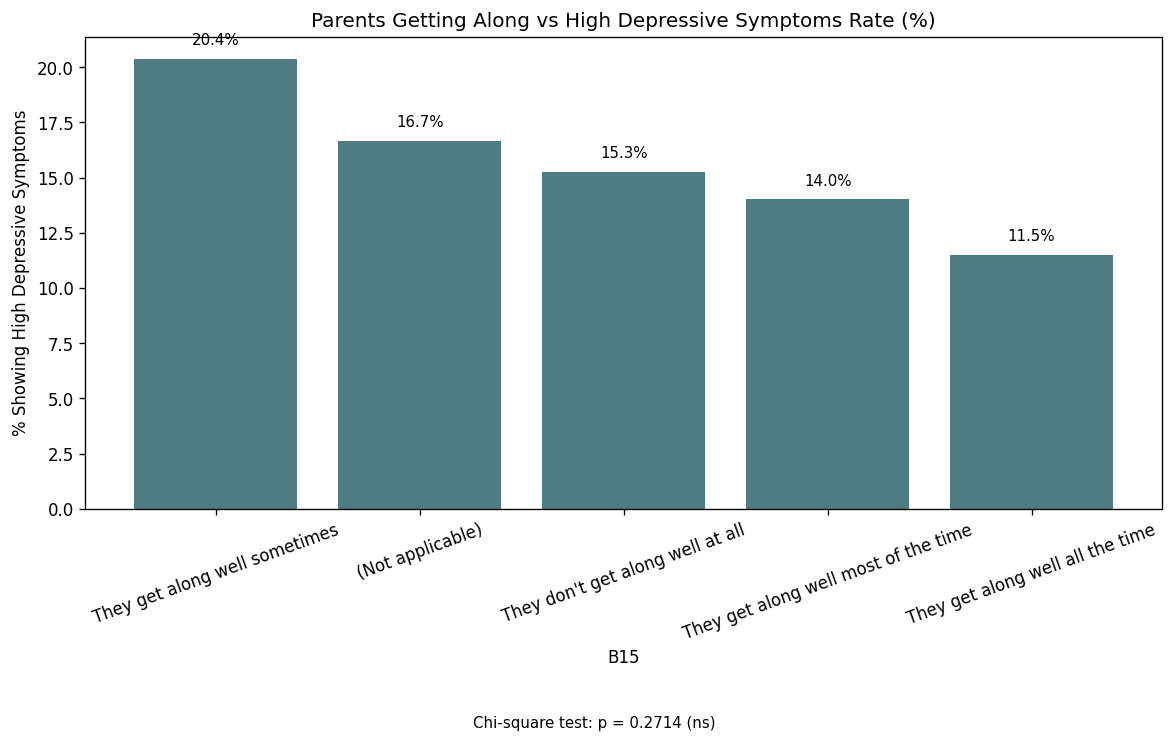

depressed_flag,0,1
B15,,
They get along well sometimes,79.629630,20.370370
(Not applicable),83.333333,16.666667
They don't get along well at all,84.722222,15.277778
They get along well most of the time,85.975610,14.024390
They get along well all the time,88.489209,11.510791


In [23]:
# Parents getting along (B15)
plot_depression_rate("B15", title="Parents Getting Along", save_name="NB2_13_parents_relations_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies across categories of respondents' reported parental relationships. Respondents whose parents get along well only sometimes exhibit the highest HDS proportion, at 20.37%, followed by those who reported that the question was not applicable (16.67%) and those whose parents do not get along well at all (15.28%). In comparison, lower HDS proportions are observed among respondents whose parents get along well most of the time (14.02%) and all the time (11.51%). This descriptive pattern suggests that respondents reporting more consistently positive parental relationships tend to have lower observed proportions of HDS. However, the Chi-square test yielded a p-value of 0.271, indicating that the observed differences are not statistically significant at the 5% level. Consequently, the analysis does not provide sufficient statistical evidence to establish an association between reported parental relationship quality and depressive symptom classification. The observed pattern may still be relevant for further examination of family environment and depressive symptoms, but it should not be interpreted as evidence of a direct relationship.

Saved: NB2_14_family_support_vs_depression.png


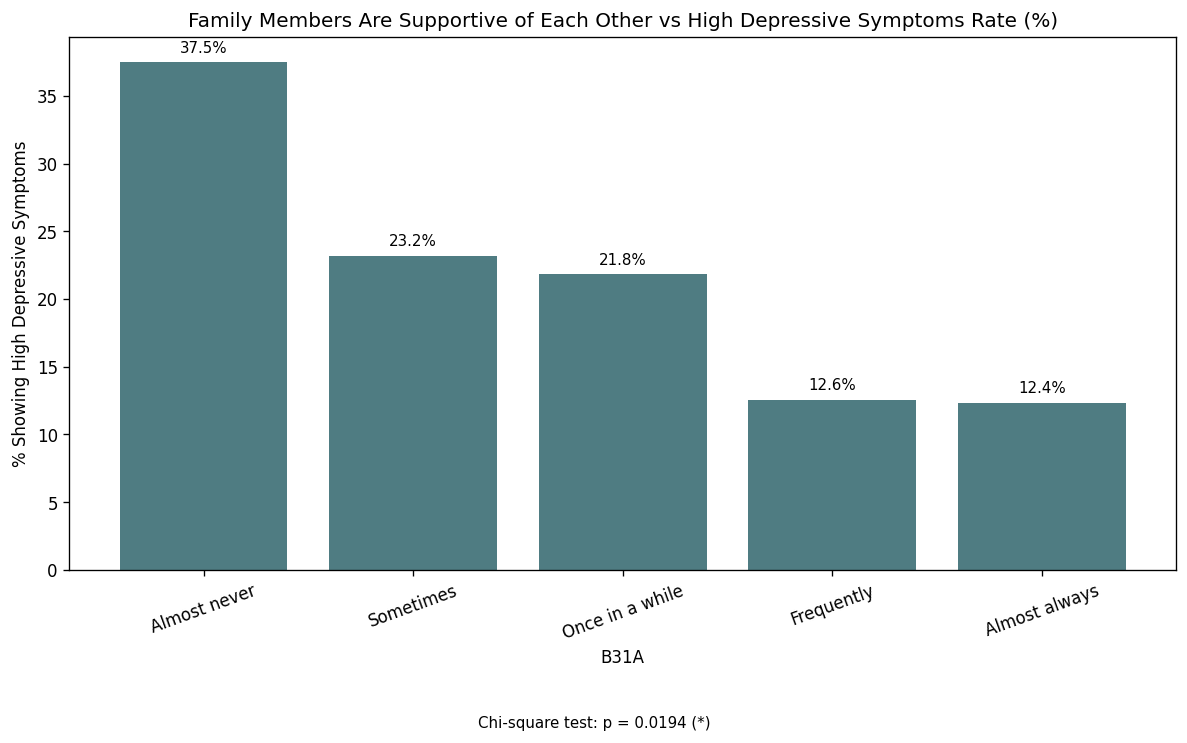

depressed_flag,0,1
B31A,,
Almost never,62.500000,37.500000
Sometimes,76.811594,23.188406
Once in a while,78.181818,21.818182
Frequently,87.434555,12.565445
Almost always,87.647059,12.352941


In [24]:
# Family members supportive of each other (B31A)
plot_depression_rate("B31A", title="Family Members Are Supportive of Each Other", save_name="NB2_14_family_support_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) shows a clear variation across the reported frequency of mutual support among family members. Respondents who reported that their family members are almost never supportive exhibit the highest HDS proportion, at 37.50%, followed by those who reported receiving support sometimes (23.20%) and once in a while (21.80%). In comparison, lower proportions are observed among respondents who reported that their family members are frequently supportive (12.60%) or almost always supportive (12.40%). This pattern indicates that less frequent family support corresponds to higher observed proportions of HDS within the NCR analytical sample. The Chi-square test yielded a p-value of 0.019, indicating a statistically significant association between reported family support and depressive symptom classification. These findings highlight the relevance of the family environment when examining depressive symptoms among Filipino youth. Family support may provide emotional and social resources that are important to an individual's well-being; however, the observed association does not establish that the frequency of family support directly determines depressive symptoms. Other family, social, and individual circumstances may also contribute to the observed differences.

**Theme 3: Friends / Peer Relationships**

Saved: NB2_15_selfworth_vs_depression.png


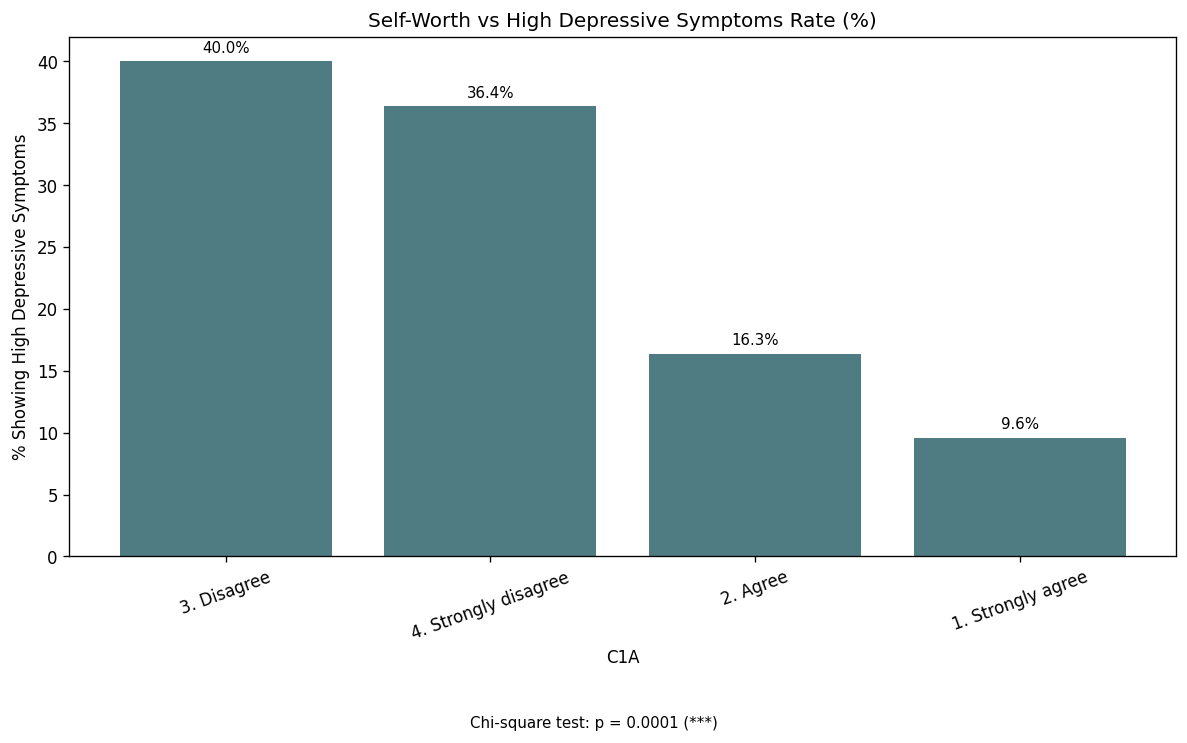

depressed_flag,0,1
C1A,,
3. Disagree,60.000000,40.000000
4. Strongly disagree,63.636364,36.363636
2. Agree,83.656510,16.343490
1. Strongly agree,90.405904,9.594096


In [85]:
# Self-worth (C1A)

plot_depression_rate("C1A", title="Self-Worth", save_name="NB2_15_selfworth_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) exhibits a pronounced pattern across respondents' happiness ratings, with higher HDS proportions generally observed among those reporting lower levels of happiness. Respondents with a happiness rating of 2 have the highest HDS proportion, at 75.00%, followed by those with ratings of 1 (60.00%), 4 (50.00%), and 3 (40.00%). In contrast, substantially lower proportions are observed among respondents with higher happiness ratings, particularly those rating their happiness as 8 (7.75%) and 9 (3.90%). This pattern indicates that lower reported happiness tends to correspond to higher observed proportions of HDS within the NCR analytical sample. The Chi-square test yielded a p-value displayed as 0.000, indicating a statistically significant association between happiness rating and depressive symptom classification. These findings highlight the relevance of subjective well-being when examining depressive symptoms among Filipino youth. However, happiness and depressive symptoms represent related but distinct psychological dimensions, and the observed association does not establish that lower happiness directly causes depressive symptoms or vice versa. Furthermore, the relatively high proportions observed in some lower-rating categories should be considered alongside their respective respondent counts.

Saved: NB2_16_life_satisfaction_vs_depression.png


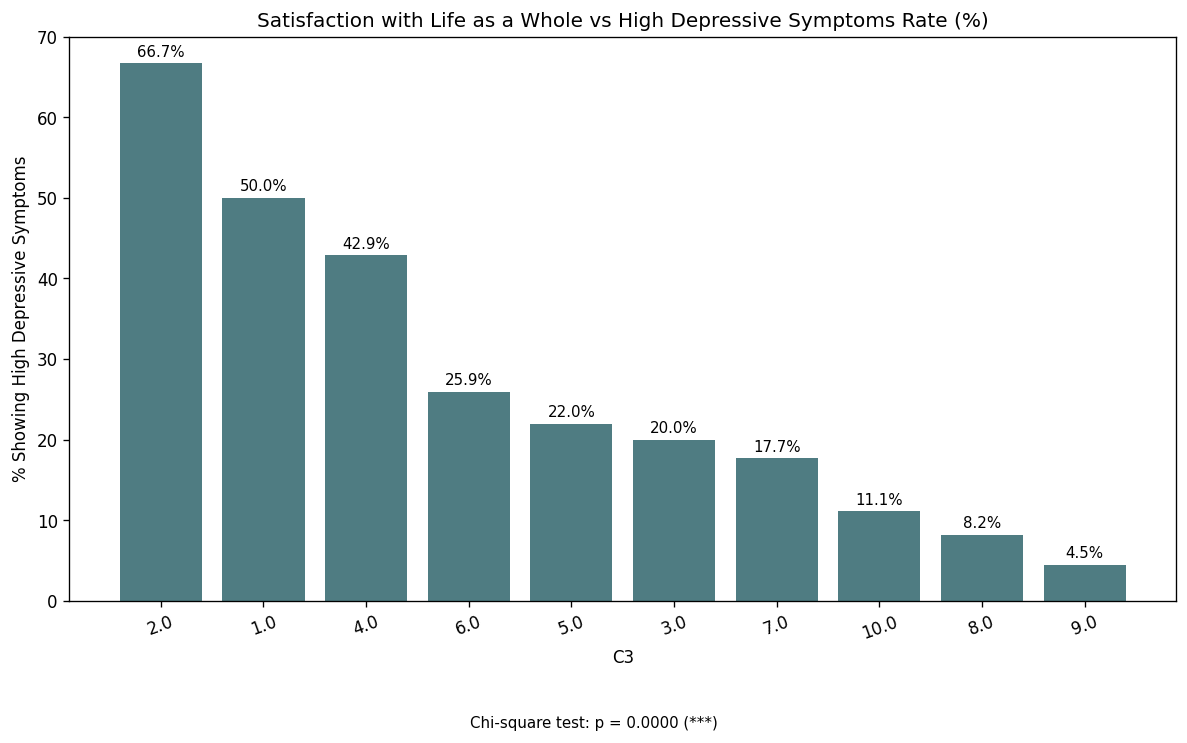

depressed_flag,0,1
C3,,
2.0,33.333333,66.666667
1.0,50.000000,50.000000
4.0,57.142857,42.857143
6.0,74.074074,25.925926
5.0,78.048780,21.951220
3.0,80.000000,20.000000
7.0,82.300885,17.699115
10.0,88.888889,11.111111
8.0,91.823899,8.176101


In [26]:
# Life satisfaction
plot_depression_rate("C3", title="Satisfaction with Life as a Whole", save_name="NB2_16_life_satisfaction_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies across respondents' levels of satisfaction with life as a whole, with higher HDS proportions generally observed among those reporting lower life satisfaction. Respondents who rated their satisfaction with life as 1 or 2 exhibit particularly high HDS proportions, ranging from approximately 50% to 67%. In contrast, respondents reporting greater satisfaction with their lives demonstrate comparatively lower HDS proportions. This pattern indicates that lower perceived life satisfaction corresponds to a higher observed proportion of HDS within the NCR analytical sample. The finding highlights the relevance of subjective life evaluation when examining depressive symptoms among Filipino youth. However, life satisfaction and depressive symptoms are related but distinct constructs, and the observed pattern does not establish a causal relationship between them. Furthermore, the differences across rating categories should be interpreted alongside their respective respondent counts, as smaller groups may produce less stable percentages.

Saved: NB2_17_financial_satisfaction_vs_depression.png


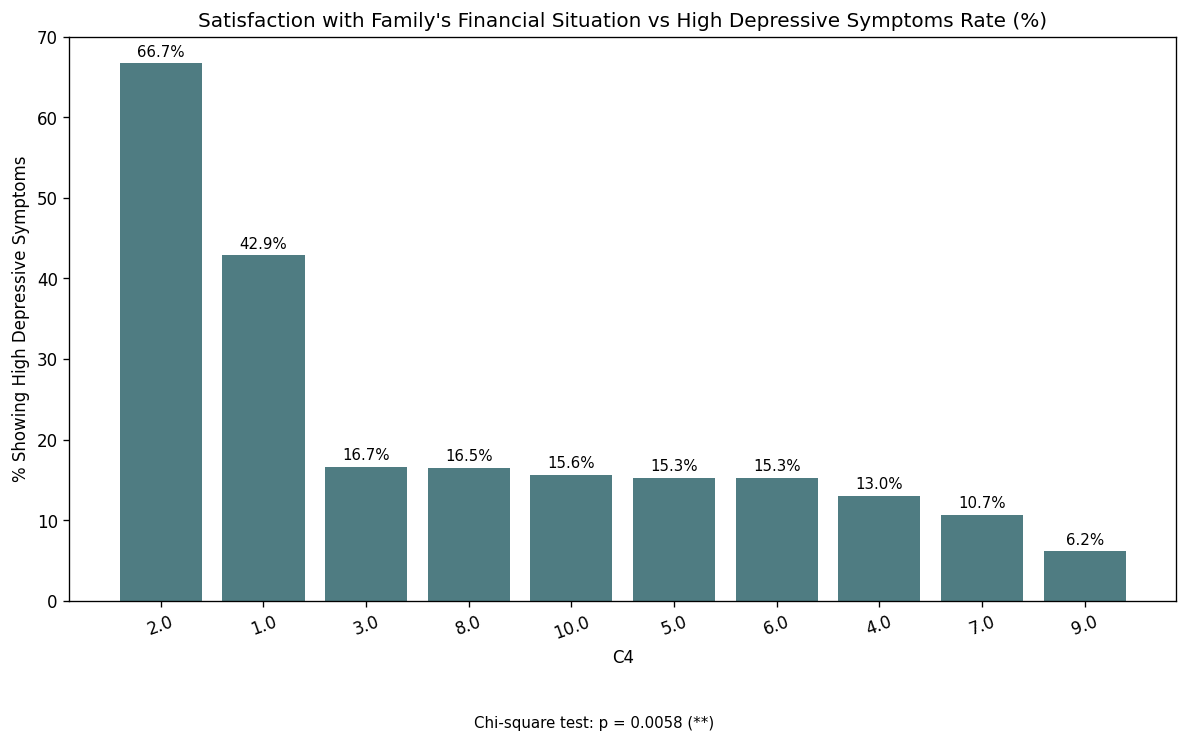

depressed_flag,0,1
C4,,
2.0,33.333333,66.666667
1.0,57.142857,42.857143
3.0,83.333333,16.666667
8.0,83.471074,16.528926
10.0,84.353741,15.646259
5.0,84.693878,15.306122
6.0,84.722222,15.277778
4.0,86.956522,13.043478
7.0,89.285714,10.714286


In [27]:
# Financial satisfaction
plot_depression_rate("C4", title="Satisfaction with Family's Financial Situation", save_name="NB2_17_financial_satisfaction_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies across respondents' levels of satisfaction with their family's financial situation. Respondents who rated their family's financial situation as 2 exhibit the highest HDS proportion, at 66.67%, followed by those who gave a rating of 1, at 42.86%. In contrast, respondents with a rating of 9 have the lowest HDS proportion, at 6.15%. Although the results generally show higher HDS proportions among respondents reporting lower financial satisfaction, the pattern is not consistently decreasing across all rating categories, as some intermediate and higher ratings exhibit comparable or slightly varying proportions. These findings suggest that respondents' subjective assessments of their family's financial situation may be relevant when examining patterns of depressive symptoms. However, financial satisfaction should be distinguished from actual household wealth or income, since it reflects an individual's perception of their family's economic circumstances rather than a direct measurement of financial resources. Furthermore, the observed differences do not establish a causal relationship between financial satisfaction and depressive symptoms, and should be considered alongside the respondent counts for each rating category.

Saved: NB2_18_happiness_vs_depression.png


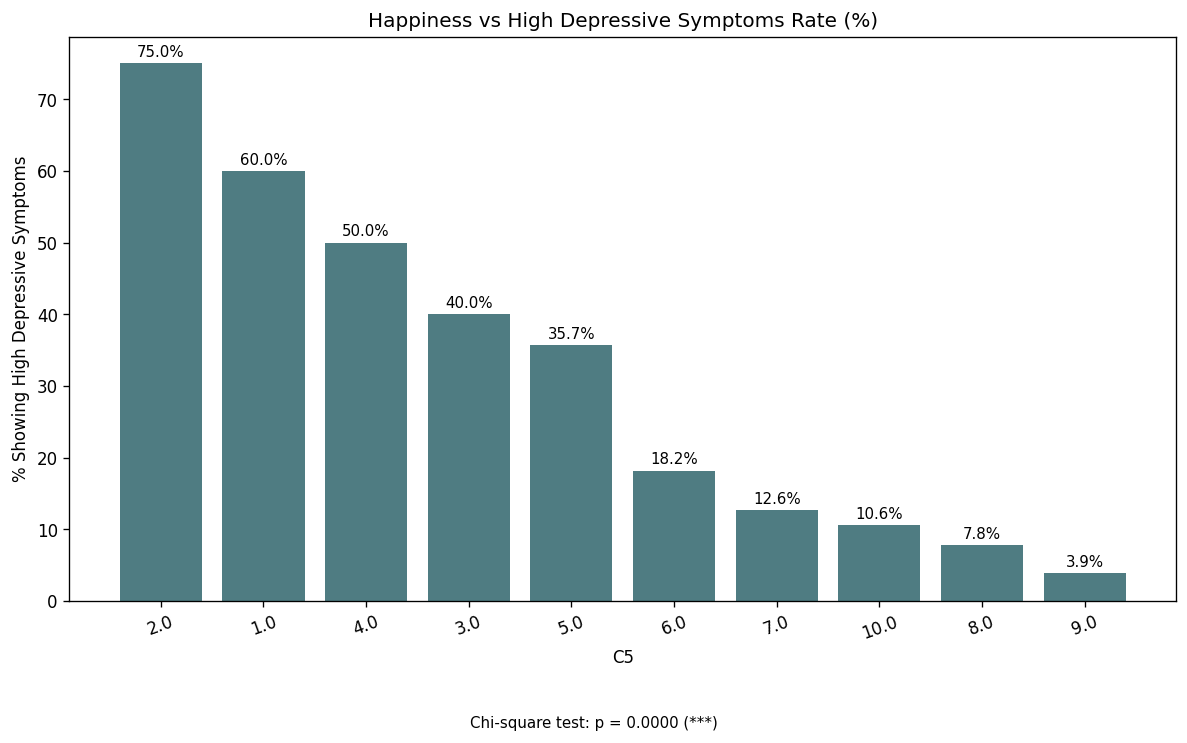

depressed_flag,0,1
C5,,
2.0,25.000000,75.000000
1.0,40.000000,60.000000
4.0,50.000000,50.000000
3.0,60.000000,40.000000
5.0,64.285714,35.714286
6.0,81.818182,18.181818
7.0,87.356322,12.643678
10.0,89.380531,10.619469
8.0,92.248062,7.751938


In [28]:
# Happiness
plot_depression_rate("C5", title="Happiness", save_name="NB2_18_happiness_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies considerably across respondents' reported happiness ratings, with higher HDS proportions generally observed among those reporting lower levels of happiness. Respondents with a happiness rating of 2 exhibit the highest HDS proportion, at 75.00%, followed by those with ratings of 1 (60.00%), 4 (50.00%), and 3 (40.00%). In contrast, substantially lower proportions are observed among respondents with higher ratings, particularly those reporting ratings of 8 (7.75%) and 9 (3.90%). Although the overall pattern suggests that higher happiness ratings correspond to lower observed HDS proportions, the relationship is not perfectly consistent across all rating categories. The Chi-square test yielded a p-value below 0.001, indicating a statistically significant association between happiness rating and depressive symptom classification. These findings highlight the relevance of subjective well-being when examining depressive symptoms among Filipino youth in NCR. However, happiness and depressive symptoms are related but distinct psychological dimensions, and the observed association does not establish a causal relationship between them. The respondent counts across individual rating categories should also be considered when interpreting the particularly high proportions observed among lower happiness ratings.

**Theme 4: School, Work, and Civic Engagement**

Saved: NB2_19_schooling_level_vs_depression.png


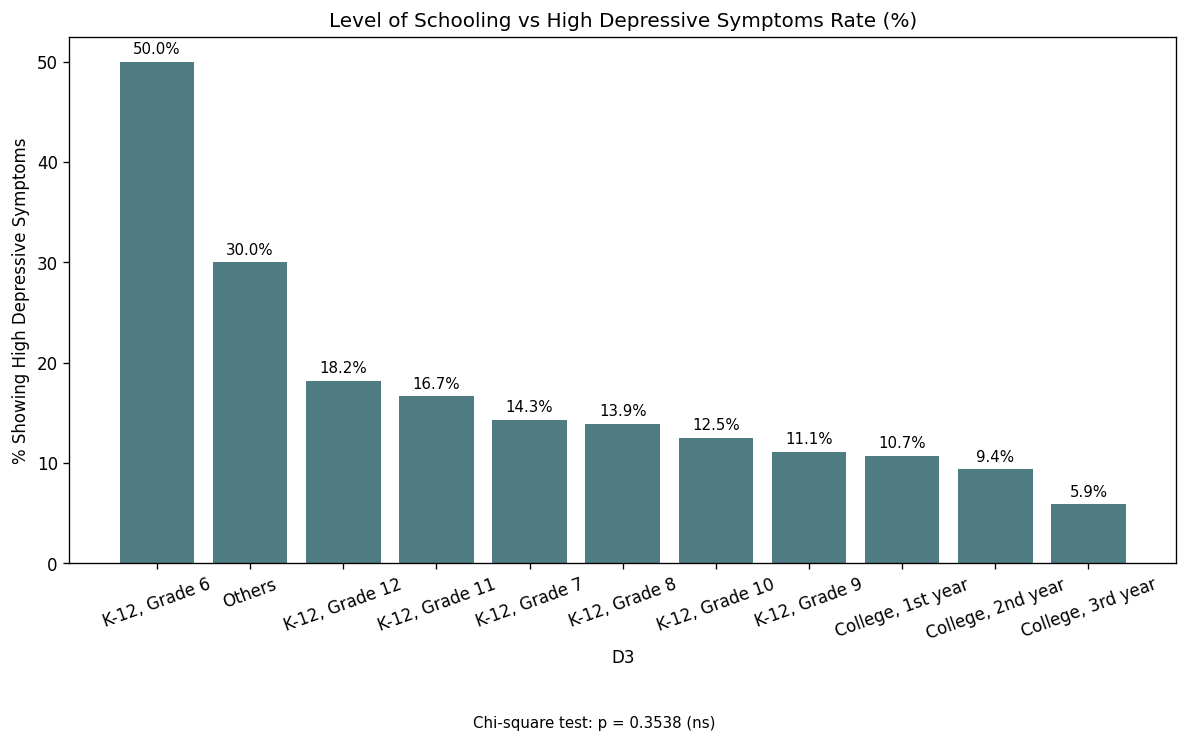

depressed_flag,0,1
D3,,
"K-12, Grade 6",50.000000,50.000000
Others,70.000000,30.000000
"K-12, Grade 12",81.818182,18.181818
"K-12, Grade 11",83.333333,16.666667
"K-12, Grade 7",85.714286,14.285714
"K-12, Grade 8",86.111111,13.888889
"K-12, Grade 10",87.500000,12.500000
"K-12, Grade 9",88.888889,11.111111
"College, 1st year",89.285714,10.714286


In [29]:
# Level of schooling (D3)
plot_depression_rate("D3", title="Level of Schooling", save_name="NB2_19_schooling_level_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies across respondents' current levels of schooling. Respondents categorized under K-12, Grade 6 exhibit the highest HDS proportion, at 50.00%, followed by those classified under "Others" at 30.00%. Among the remaining schooling categories, the HDS proportion generally decreases across higher grade levels, from 18.18% among Grade 12 respondents to 16.67% among Grade 11 respondents, and further to 5.88% among third-year college students. This pattern suggests that the observed proportion of HDS differs across schooling levels, with lower proportions generally appearing among respondents in higher educational levels. However, the results should be interpreted cautiously, particularly for categories such as Grade 6 and "Others," since their percentages may be influenced by relatively small respondent counts. Furthermore, current schooling level alone does not establish a direct relationship with depressive symptoms, as differences in other factors may also be relevant.

Saved: NB2_20_school_type_vs_depression.png


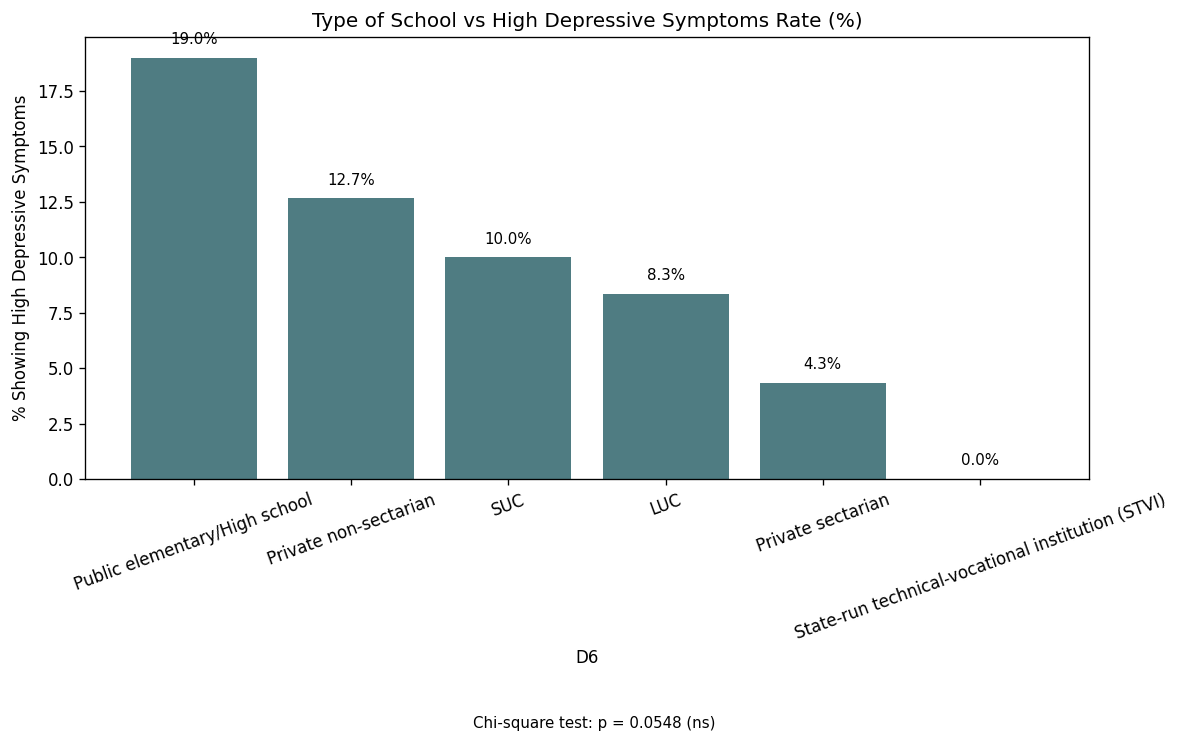

depressed_flag,0,1
D6,,
Public elementary/High school,81.000000,19.000000
Private non-sectarian,87.341772,12.658228
SUC,90.000000,10.000000
LUC,91.666667,8.333333
Private sectarian,95.652174,4.347826
State-run technical-vocational institution (STVI),100.000000,0.000000


In [30]:
# Type of school (D6)
plot_depression_rate("D6", title="Type of School", save_name="NB2_20_school_type_vs_depression.png")

**SYNTHESIS:** The distribution of High Depressive Symptoms (HDS) varies across respondents' reported types of school. Respondents attending public elementary or high schools exhibit the highest HDS proportion, at 19.00%, followed by those attending private non-sectarian schools (12.66%), state universities and colleges (SUCs) (10.00%), local universities and colleges (LUCs) (8.33%), and private sectarian schools (4.35%). Meanwhile, no HDS cases were observed among respondents attending state-run technical-vocational institutions (STVI). Although the observed proportions generally decrease across these school categories, the Chi-square test yielded a p-value of 0.055, which does not meet the conventional 5% significance threshold. Therefore, the analysis does not provide sufficient statistical evidence to establish an association between type of school and depressive symptom classification. The 0% HDS proportion observed among STVI respondents should also be interpreted cautiously, particularly if the category contains relatively few observations. Overall, the findings show descriptive differences across school types, but these differences do not establish that the type of educational institution directly influences depressive symptoms.

Saved: NB2_21_study_environment_vs_depression.png


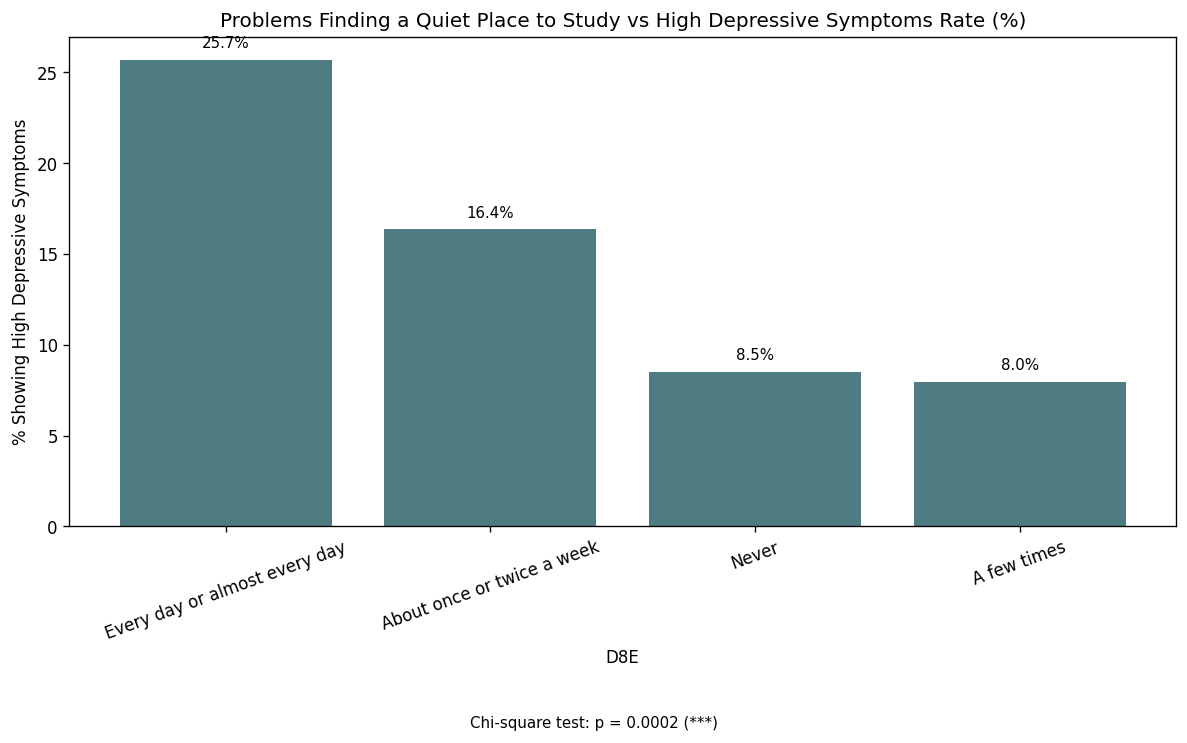

depressed_flag,0,1
D8E,,
Every day or almost every day,74.311927,25.688073
About once or twice a week,83.636364,16.363636
Never,91.509434,8.490566
A few times,92.028986,7.971014


In [31]:
# Quiet place to study (D8E)
plot_depression_rate("D8E", title="Problems Finding a Quiet Place to Study", save_name="NB2_21_study_environment_vs_depression.png")

**SYNTHESIS:** The findings indicate a significant association between the frequency of experiencing difficulty finding a quiet place to study and depression status among the respondents. Respondents who experience this difficulty every day or almost every day exhibit the highest proportion of High Depressive Symptoms (HDS) at 25.69%, followed by those who experience it about once or twice a week at 16.36%. In comparison, respondents who never experience this difficulty have an HDS proportion of 8.49%, while those who experience it only a few times have the lowest proportion at 7.97%. These findings suggest that the frequency of difficulty finding a quiet place to study is associated with depression status, with more frequent experiences generally corresponding to higher HDS proportions. However, this association does not establish a causal relationship between study environment and depressive symptoms.

Saved: NB2_22_motivation_problems_vs_depression.png


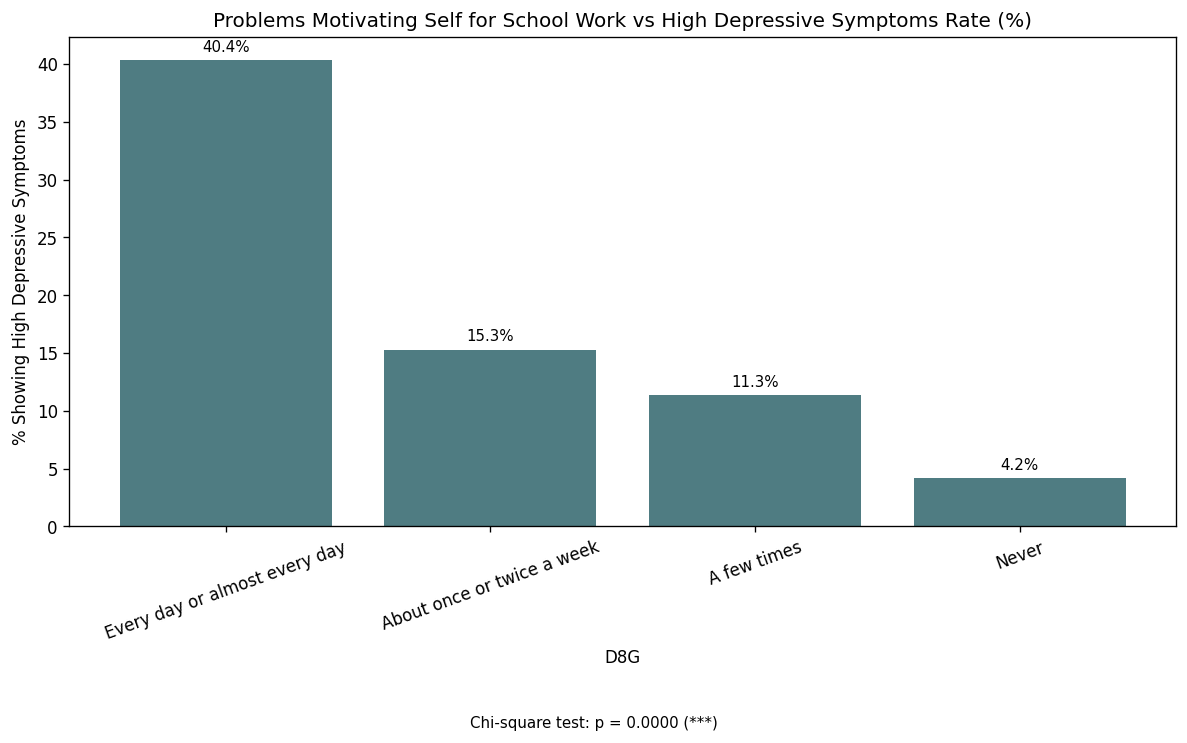

depressed_flag,0,1
D8G,,
Every day or almost every day,59.649123,40.350877
About once or twice a week,84.722222,15.277778
A few times,88.679245,11.320755
Never,95.833333,4.166667


In [32]:
# Motivation problems (D8G)
plot_depression_rate("D8G", title="Problems Motivating Self for School Work", save_name="NB2_22_motivation_problems_vs_depression.png")

**SYNTHESIS:** The findings indicate differences in the proportion of High Depressive Symptoms (HDS) across respondents experiencing varying levels of difficulty motivating themselves for schoolwork. Respondents who experience this difficulty every day or almost every day exhibit the highest HDS proportion at 40.35%, followed by those who experience it about once or twice a week at 15.28%. Meanwhile, respondents who experience this difficulty only a few times have an HDS proportion of 11.32%, while those who never experience it have the lowest proportion at 4.17%. Overall, the descriptive results show that more frequent difficulty motivating oneself for schoolwork coincides with a higher proportion of HDS. This pattern highlights the relevance of academic motivation when examining depressive symptoms among the respondents. However, the findings are descriptive and do not establish a causal relationship.

Saved: NB2_23_school_performance_vs_depression.png


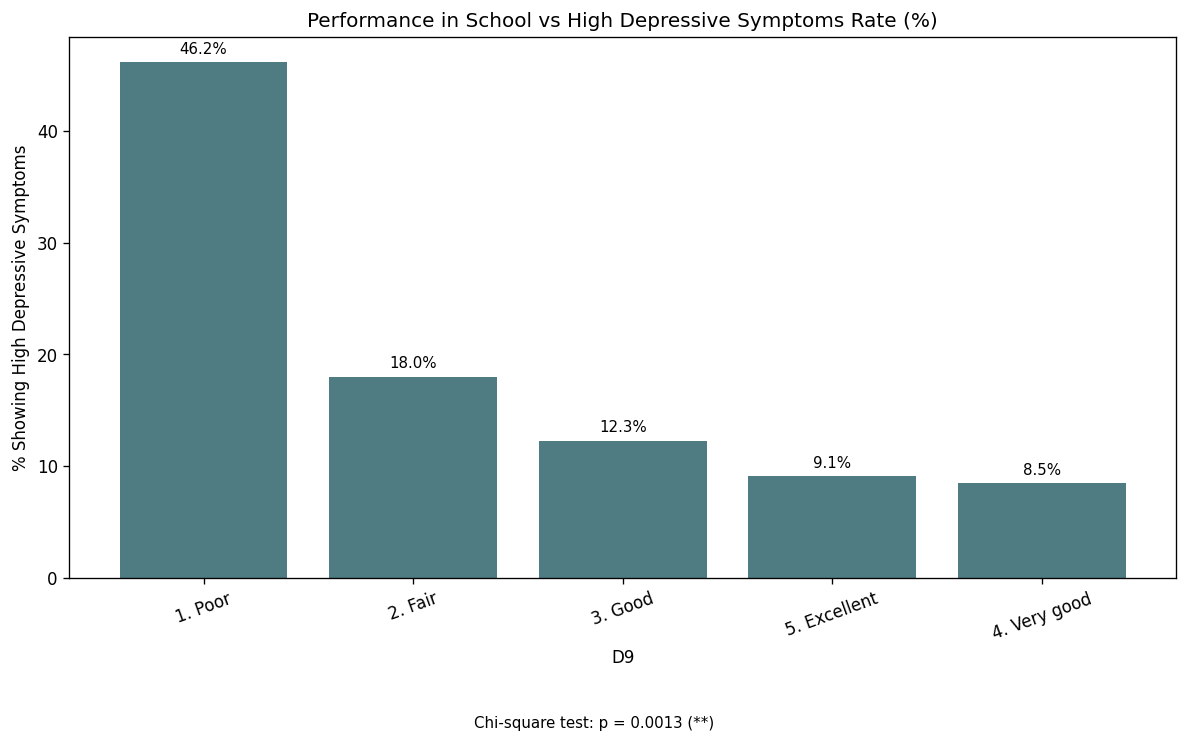

depressed_flag,0,1
D9,,
1. Poor,53.846154,46.153846
2. Fair,81.992337,18.007663
3. Good,87.711864,12.288136
5. Excellent,90.909091,9.090909
4. Very good,91.509434,8.490566


In [33]:
# Performance in school (D9)
plot_depression_rate("D9", title="Performance in School", save_name="NB2_23_school_performance_vs_depression.png")

**SYNTHESIS:** The findings indicate differences in the proportion of High Depressive Symptoms (HDS) across respondents with varying levels of self-rated school performance. Respondents who rated their school performance as poor exhibit the highest HDS proportion at 46.15%, followed by those who rated it as fair at 18.01%. The HDS proportion decreases among respondents who rated their performance as good (12.29%), very good (8.49%), and excellent (9.09%). Overall, the descriptive results suggest that lower self-rated school performance generally coincides with a higher proportion of HDS. However, the slight increase in the proportion among respondents who rated their performance as excellent indicates that the pattern is not strictly linear. These findings describe an observed association in the data and do not establish a causal relationship between school performance and depressive symptoms.

**Theme 5: ICT, Internet, and Media Use**

Saved: NB2_24_internet_hours_vs_depression.png


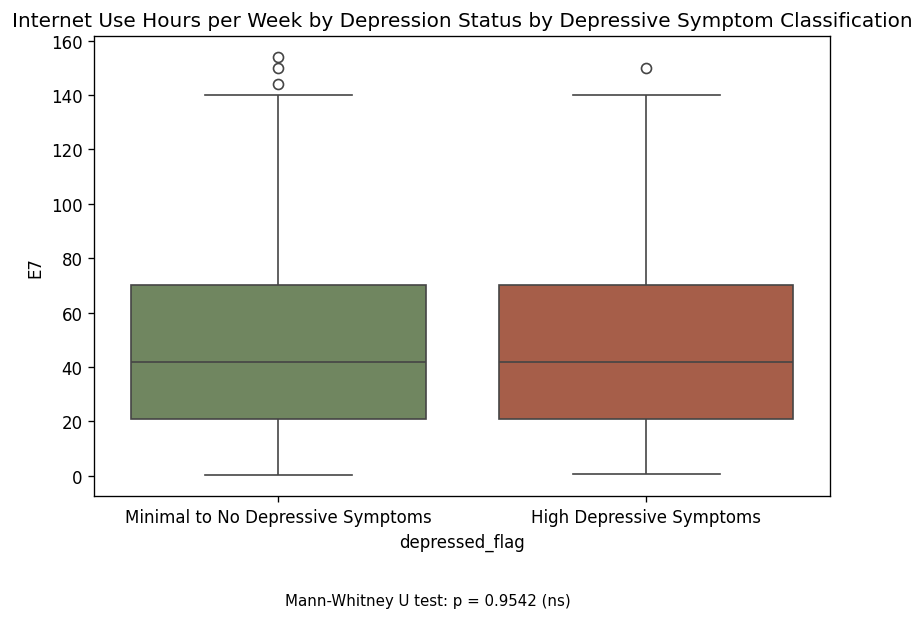

In [34]:
# Internet use hours per week (E7)
boxplot("E7", title="Internet Use Hours per Week by Depression Status", save_name="NB2_24_internet_hours_vs_depression.png")

**SYNTHESIS:** The findings indicate no statistically significant difference in weekly internet-use hours between respondents with High Depressive Symptoms (HDS) and those with Minimal or No Depressive Symptoms (MNDS), based on the Mann–Whitney U test. Both groups exhibit an identical median of 42 hours per week and an interquartile range of 49 hours, indicating similar distributions of internet-use hours. These results suggest that weekly internet-use duration does not significantly differ according to depression status among the respondents. Therefore, the number of hours spent using the internet per week does not demonstrate a significant distinction between the two groups in this analysis.

Saved: NB2_25_tiktok_vs_depression.png


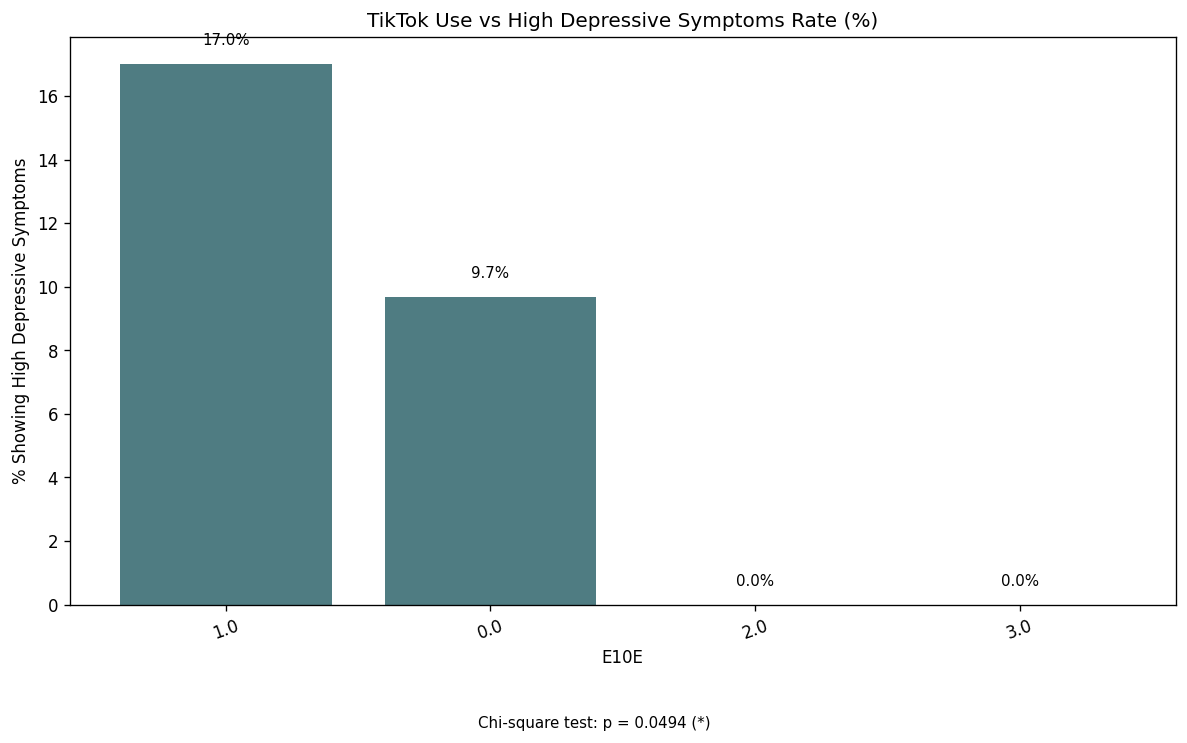

depressed_flag,0,1
E10E,,
1.0,82.983683,17.016317
0.0,90.322581,9.677419
2.0,100.000000,0.000000
3.0,100.000000,0.000000


In [35]:
# TikTok use (E10E)
plot_depression_rate("E10E", title="TikTok Use", save_name="NB2_25_tiktok_vs_depression.png")

**SYNTHESIS:** The findings indicate differences in the proportion of High Depressive Symptoms (HDS) across the response categories for TikTok use. Respondents in category 1.0 exhibit the highest HDS proportion at 17.02%, followed by those in category 0.0 at 9.68%. Meanwhile, categories 2.0 and 3.0 show no respondents with HDS, with all respondents in these categories classified as having Minimal or No Depressive Symptoms (MNDS). However, these results should be interpreted cautiously, particularly for categories with 0% HDS, as the number of respondents in these groups may be relatively small. Overall, the descriptive findings show variation in depression status across TikTok-use categories, but do not establish a causal relationship.

Saved: NB2_26_stranger_chat_vs_depression.png


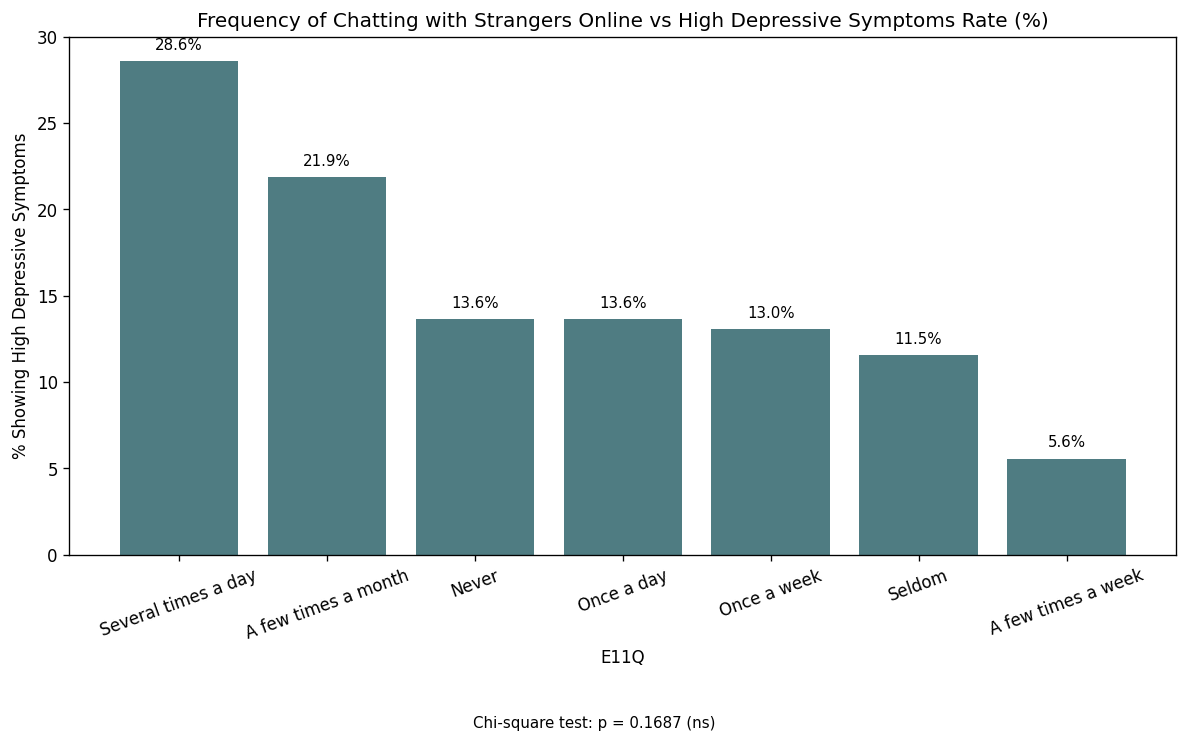

depressed_flag,0,1
E11Q,,
Several times a day,71.428571,28.571429
A few times a month,78.125000,21.875000
Never,86.353468,13.646532
Once a day,86.363636,13.636364
Once a week,86.956522,13.043478
Seldom,88.461538,11.538462
A few times a week,94.444444,5.555556


In [36]:
# Interact/chat with strangers online (E11Q)
plot_depression_rate("E11Q", title="Frequency of Chatting with Strangers Online", save_name="NB2_26_stranger_chat_vs_depression.png")

**SYNTHESIS:** The findings indicate no statistically significant association between the frequency of chatting with strangers online and depression status among the respondents. Although variations in the proportion of High Depressive Symptoms (HDS) were observed across response categories, these differences were not statistically significant at the 0.05 significance level. The highest HDS proportion was observed among respondents who chat with strangers online several times a day (28.57%), while the lowest was found among those who engage in this activity a few times a week (5.56%). However, the results should be interpreted cautiously because four expected cell frequencies were below 5, indicating a potential violation of the Chi-square test assumption. Overall, the analysis does not provide sufficient evidence of an association between the frequency of chatting with strangers online and depression status.

**Theme 6: Mental Health & Well-being**

Saved: NB2_27_friend_sharing_vs_depression.png


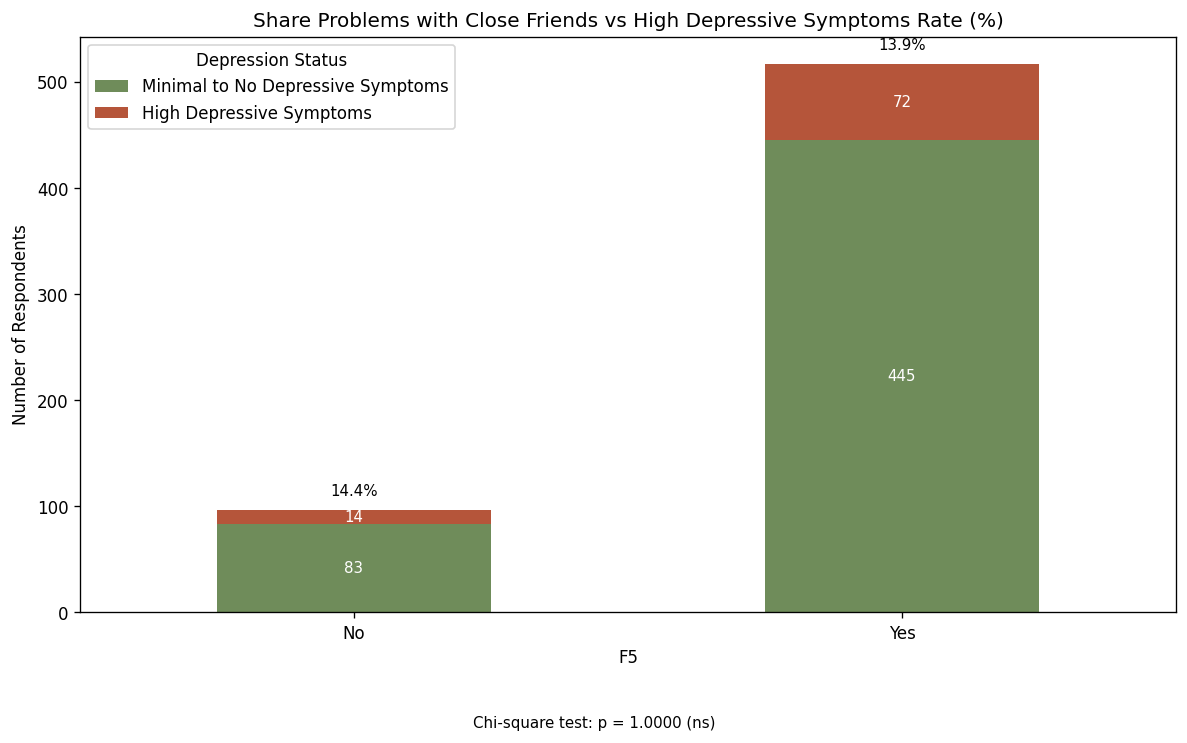

depressed_flag,0,1
F5,,
No,85.567010,14.432990
Yes,86.073501,13.926499


In [37]:
# Share problems with close friends (F5)
plot_stacked_depression("F5", title="Share Problems with Close Friends", save_name="NB2_27_friend_sharing_vs_depression.png")

**SYNTHESIS:** The findings indicate minimal differences in the proportion of High Depressive Symptoms (HDS) between respondents who share their problems with close friends and those who do not. Respondents who do not share their problems exhibit an HDS proportion of 14.43%, slightly higher than the 13.93% observed among those who do. The difference between the two groups is relatively small, suggesting that the proportion of HDS is comparable regardless of whether respondents share their problems with close friends. These results are descriptive and do not establish that sharing problems directly reduces depressive symptoms.

Saved: NB2_28_online_friends_vs_depression.png


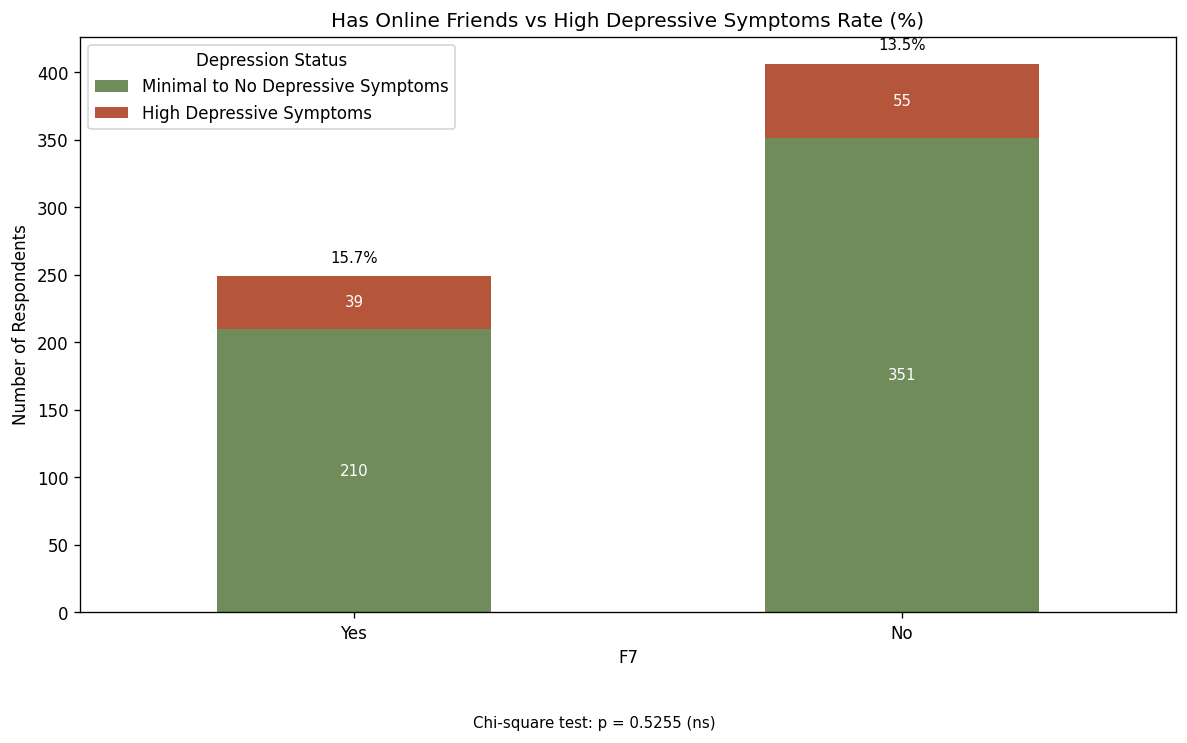

depressed_flag,0,1
F7,,
Yes,84.337349,15.662651
No,86.453202,13.546798


In [38]:
# Online friends (F7)
plot_stacked_depression("F7", title="Has Online Friends", save_name="NB2_28_online_friends_vs_depression.png")

**SYNTHESIS:** The findings indicate minimal differences in the proportion of High Depressive Symptoms (HDS) between respondents who have online friends and those who do not. Respondents who have online friends exhibit an HDS proportion of 15.66%, slightly higher than the 13.55% observed among those without online friends. The relatively small difference suggests that depression status is comparable between the two groups based on the descriptive results. These findings do not establish a causal relationship between having online friends and depressive symptoms.

Saved: NB2_29_social_media_sharing_vs_depression.png


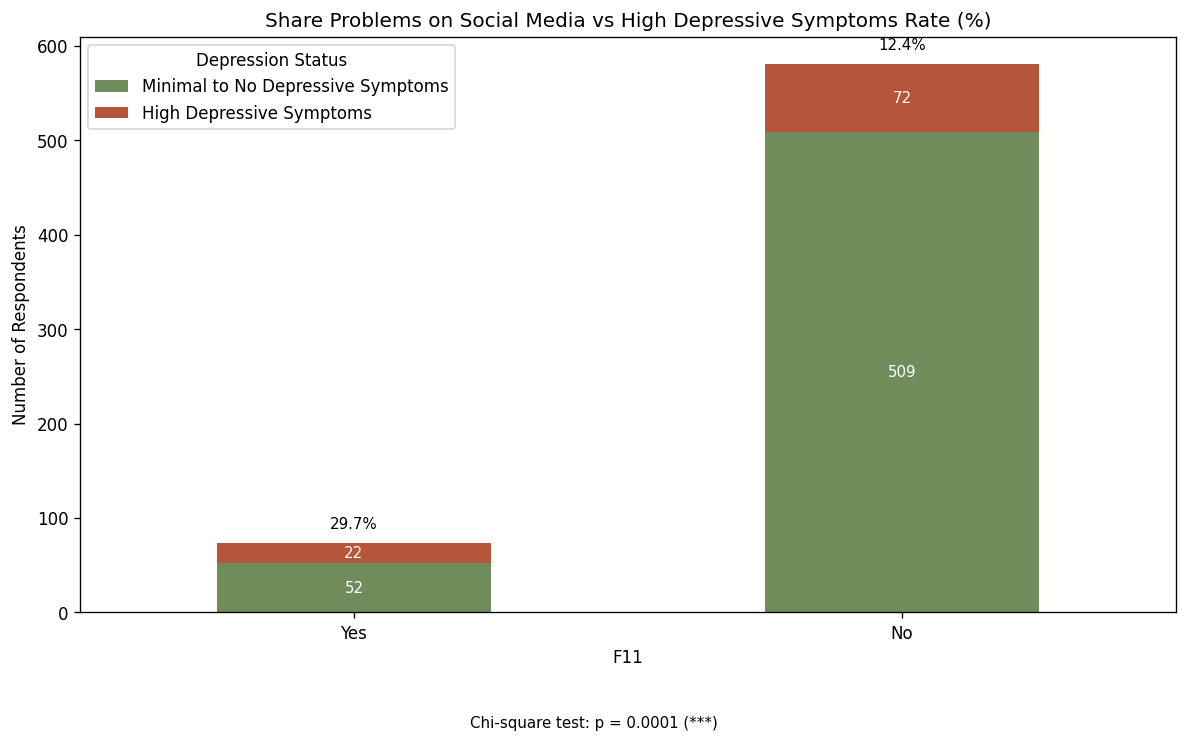

depressed_flag,0,1
F11,,
Yes,70.270270,29.729730
No,87.607573,12.392427


In [39]:
# Share problems on social media (F11)
plot_stacked_depression("F11", title="Share Problems on Social Media", save_name="NB2_29_social_media_sharing_vs_depression.png")

**SYNTHESIS:** The findings indicate differences in the proportion of High Depressive Symptoms (HDS) between respondents who share their problems on social media and those who do not. Respondents who share their problems on social media exhibit a higher HDS proportion of 29.73%, compared with 12.39% among those who do not. This represents a difference of approximately 17.34 percentage points between the two groups. The descriptive results suggest that sharing personal problems on social media is associated with a higher proportion of HDS among the respondents. However, these findings do not establish a causal relationship, as the direction of the association cannot be determined from the descriptive analysis alone.

Saved: NB2_30_self_esteem_vs_depression.png


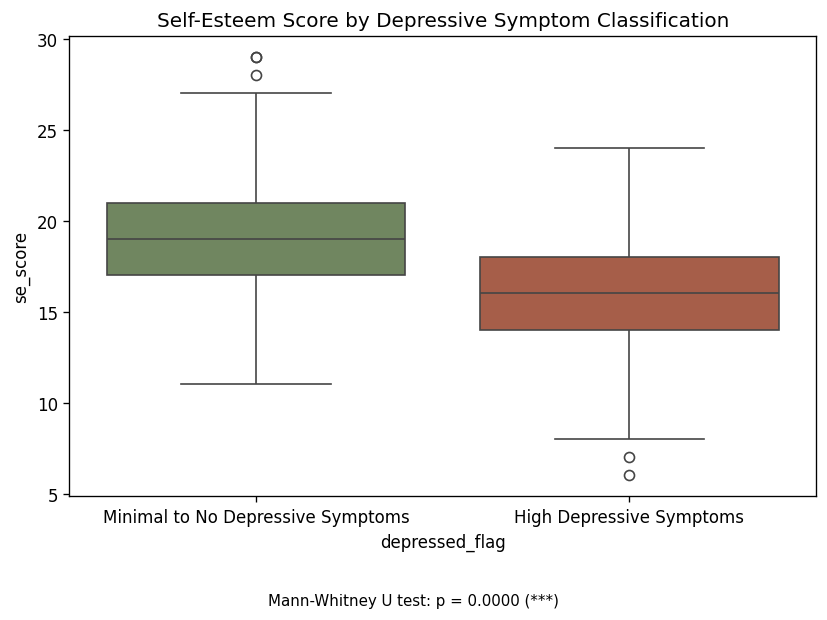

In [40]:
# Self-esteem score (se_score)
boxplot("se_score", title="Self-Esteem Score", save_name="NB2_30_self_esteem_vs_depression.png")

**SYNTHESIS:** The Mann–Whitney U test revealed a statistically significant difference in self-esteem scores between the HDS and MNDS groups. Respondents in the HDS group had a lower median self-esteem score than those in the MNDS group. This suggests that lower self-esteem scores are associated with high depressive symptoms among the respondents. However, this finding does not establish a causal relationship between self-esteem and depressive symptoms.

Saved: NB2_31_self_efficacy_vs_depression.png


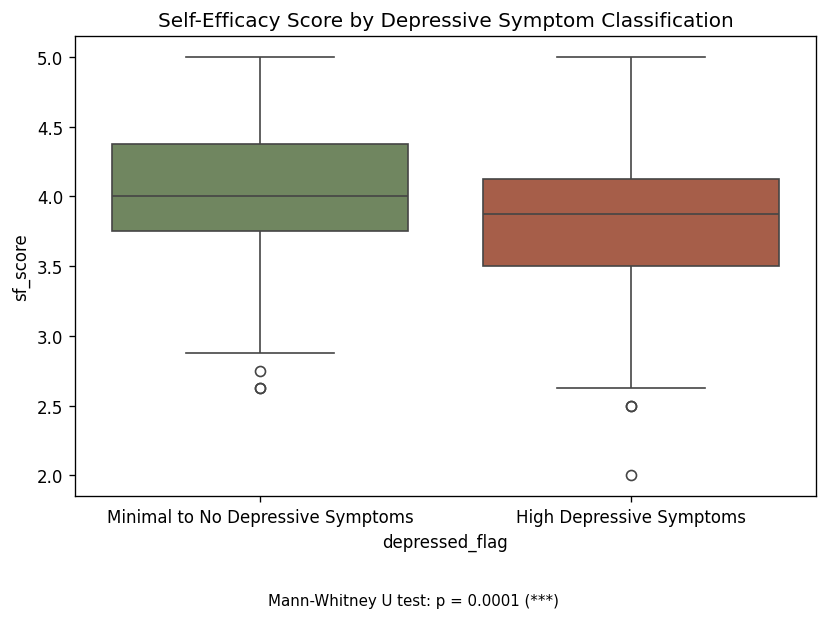

In [41]:
# Self-efficacy score (sf_score)
boxplot("sf_score", title="Self-Efficacy Score", save_name="NB2_31_self_efficacy_vs_depression.png")

**SYNTHESIS:** The Mann–Whitney U test revealed a statistically significant difference in self-efficacy scores between the HDS and MNDS groups. Respondents in the HDS group had a slightly lower median self-efficacy score than those in the MNDS group. These findings suggest that lower self-efficacy scores are associated with high depressive symptoms among the respondents, although the difference in median scores is relatively small. This association does not establish causality.

**Theme 7: Subjective Health, Lifestyle, Health Risk Behaviors**

Saved: NB2_32_health_status_vs_depression.png


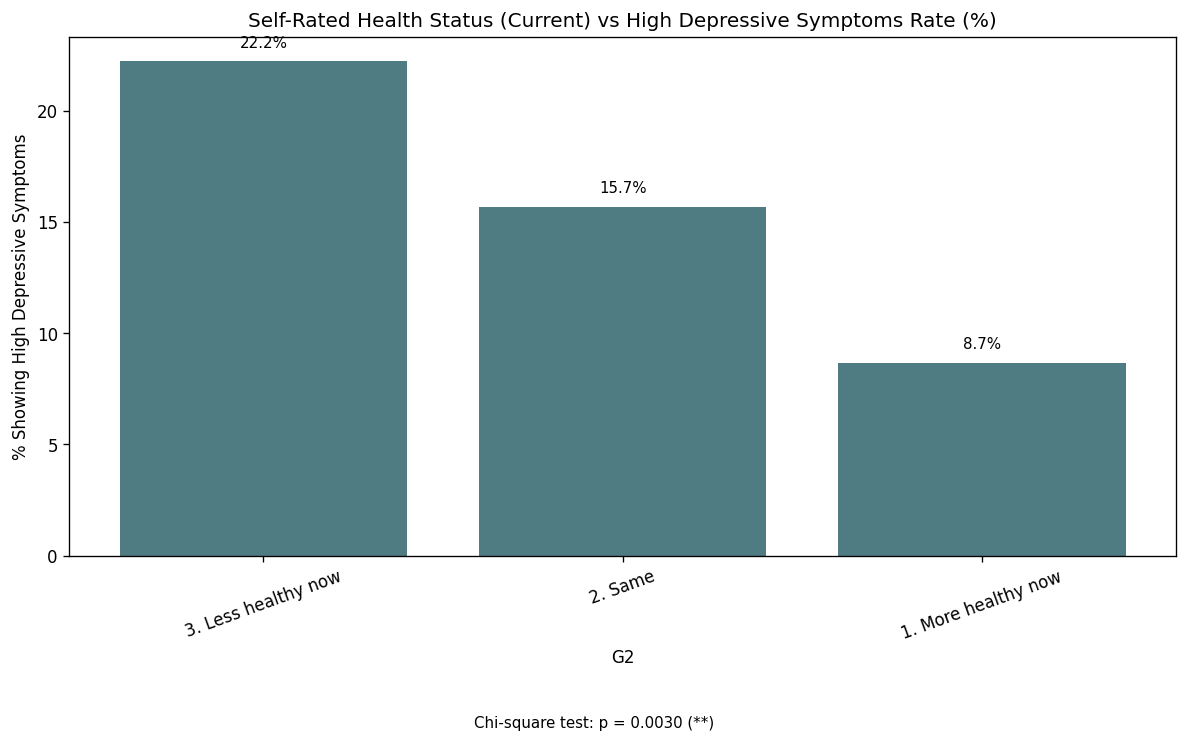

depressed_flag,0,1
G2,,
3. Less healthy now,77.777778,22.222222
2. Same,84.319527,15.680473
1. More healthy now,91.346154,8.653846


In [42]:
# Self-rated health (G2)
plot_depression_rate("G2", title="Self-Rated Health Status (Current)", save_name="NB2_32_health_status_vs_depression.png")

**SYNTHESIS:** The results show that respondents who perceived themselves as less healthy than before had the highest proportion of HDS (22.22%), followed by those who reported that their health remained the same (15.68%). In contrast, respondents who considered themselves more healthy had the lowest proportion of HDS (8.65%). This pattern suggests an association between self-rated health status and depressive symptoms, with less favorable perceptions of current health corresponding to higher HDS prevalence. However, this relationship does not establish causality.

Saved: NB2_33_exercise_vs_depression.png


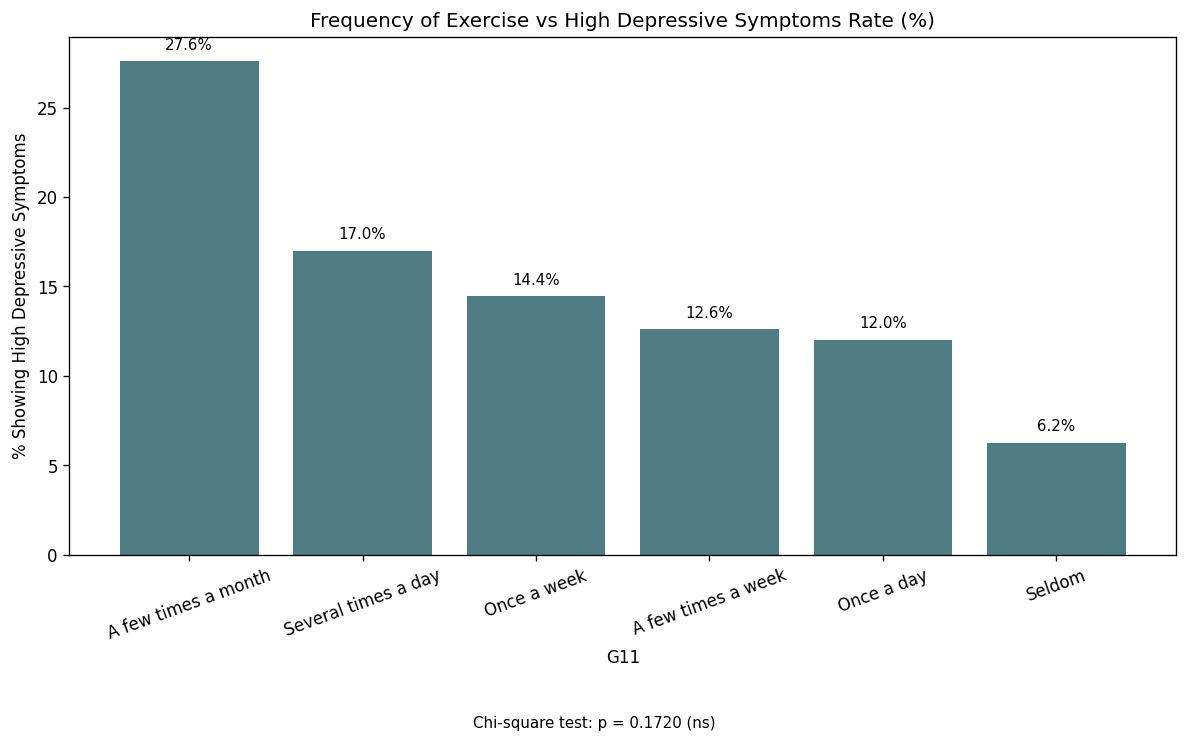

depressed_flag,0,1
G11,,
A few times a month,72.413793,27.586207
Several times a day,83.018868,16.981132
Once a week,85.567010,14.432990
A few times a week,87.412587,12.587413
Once a day,88.000000,12.000000
Seldom,93.750000,6.250000


In [43]:
# Frequency of exercise (G11)
plot_depression_rate("G11", title="Frequency of Exercise", save_name="NB2_33_exercise_vs_depression.png")

**SYNTHESIS:** The results show that respondents who exercised a few times a month had the highest proportion of HDS (27.59%), while those who seldom exercised had the lowest proportion (6.25%). However, the distribution does not demonstrate a consistent pattern between exercise frequency and HDS, as respondents who exercised several times a day also showed a relatively high HDS proportion (16.98%). These findings suggest differences in HDS prevalence across exercise-frequency categories, although the relationship is not clearly linear and does not establish causality.

Saved: NB2_34_sleep_vs_depression.png


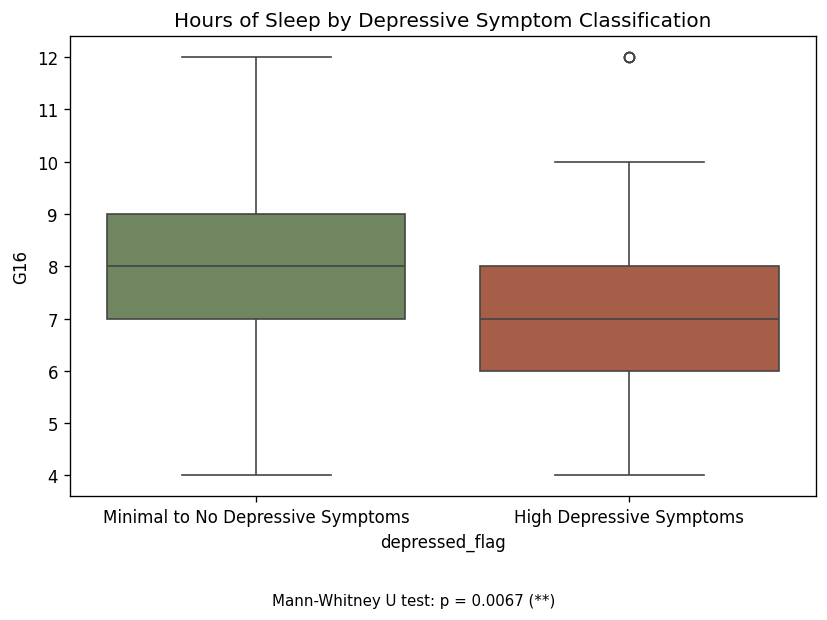

In [44]:
# Hours of sleep (G16)
boxplot("G16", title="Hours of Sleep", save_name="NB2_34_sleep_vs_depression.png")

**SYNTHESIS:** The comparison of sleep duration showed that respondents in the HDS group had a lower median number of sleep hours (Mdn = 7.00) than those in the MNDS group (Mdn = 8.00). Both groups had an interquartile range of 2.00 hours, indicating similar interquartile spread. These findings suggest that shorter sleep duration is associated with high depressive symptoms among the respondents. However, the observed relationship does not establish causality.

Saved: NB2_35_smoking_vs_depression.png


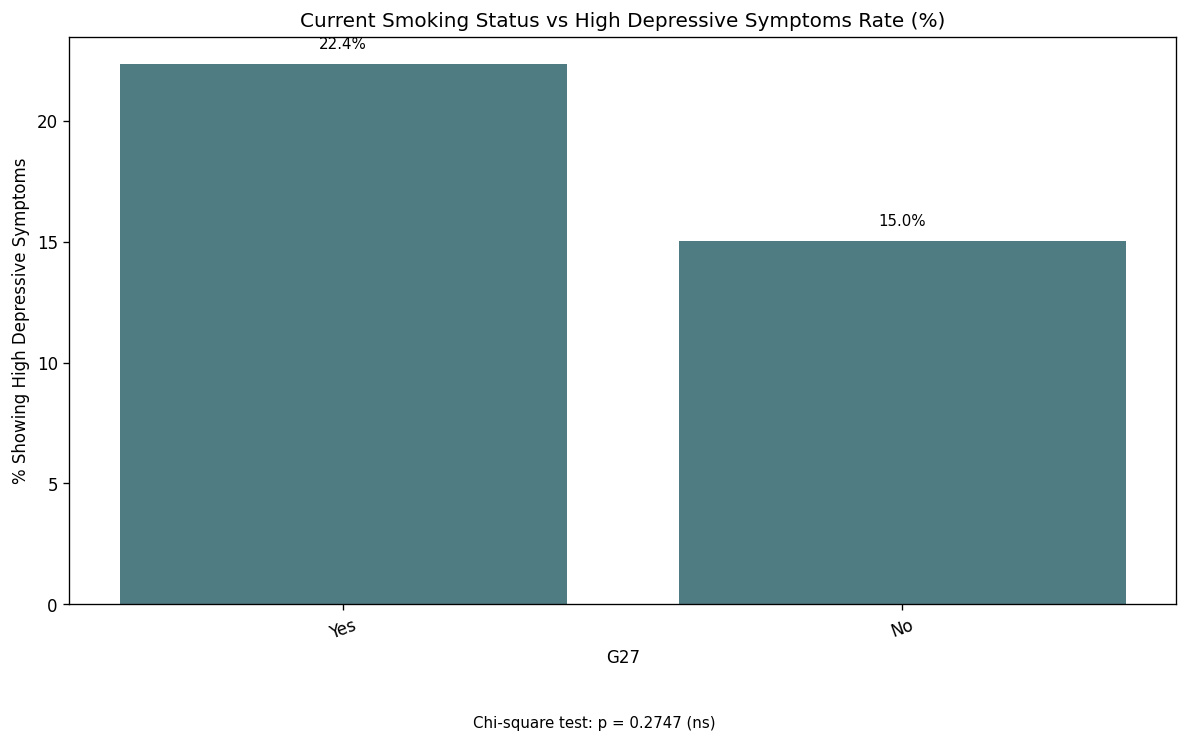

depressed_flag,0,1
G27,,
Yes,77.631579,22.368421
No,84.955752,15.044248


In [45]:
# Currently smoke (G27)
plot_depression_rate("G27", title="Current Smoking Status", save_name="NB2_35_smoking_vs_depression.png")

**SYNTHESIS:** The figure indicates that respondents who currently smoke had a higher proportion of high depressive symptoms (22.37%) compared with those who do not currently smoke (15.04%). This suggests a possible association between current smoking status and depressive symptoms among the respondents. However, the observed difference does not establish a causal relationship.

Saved: NB2_36_drinking_vs_depression.png


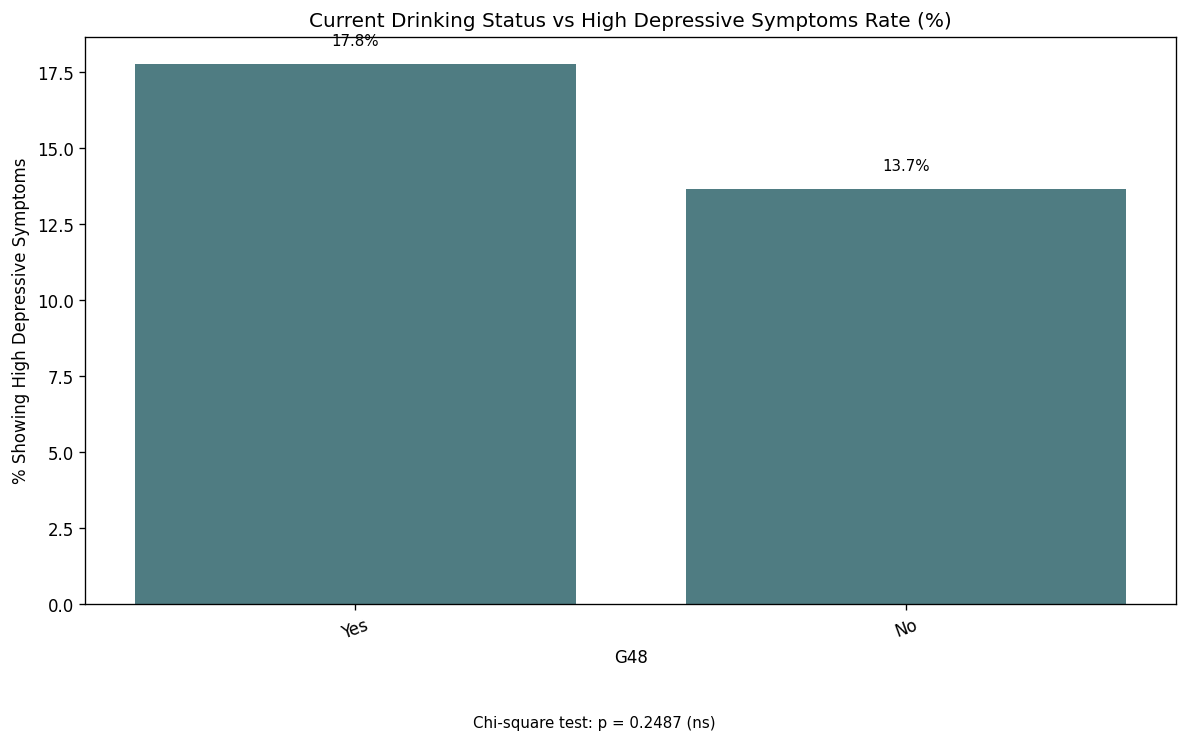

depressed_flag,0,1
G48,,
Yes,82.213439,17.786561
No,86.328125,13.671875


In [46]:
# Currently drink (G48)
plot_depression_rate("G48", title="Current Drinking Status", save_name="NB2_36_drinking_vs_depression.png")

**SYNTHESIS:** The figure shows that respondents who currently drink alcohol had a higher proportion of high depressive symptoms (17.79%) compared with those who do not currently drink (13.67%). This indicates a descriptive difference in depressive symptom classification based on current drinking status. However, the observed difference does not establish a causal relationship.

Saved: NB2_37_physical_harm_vs_depression.png


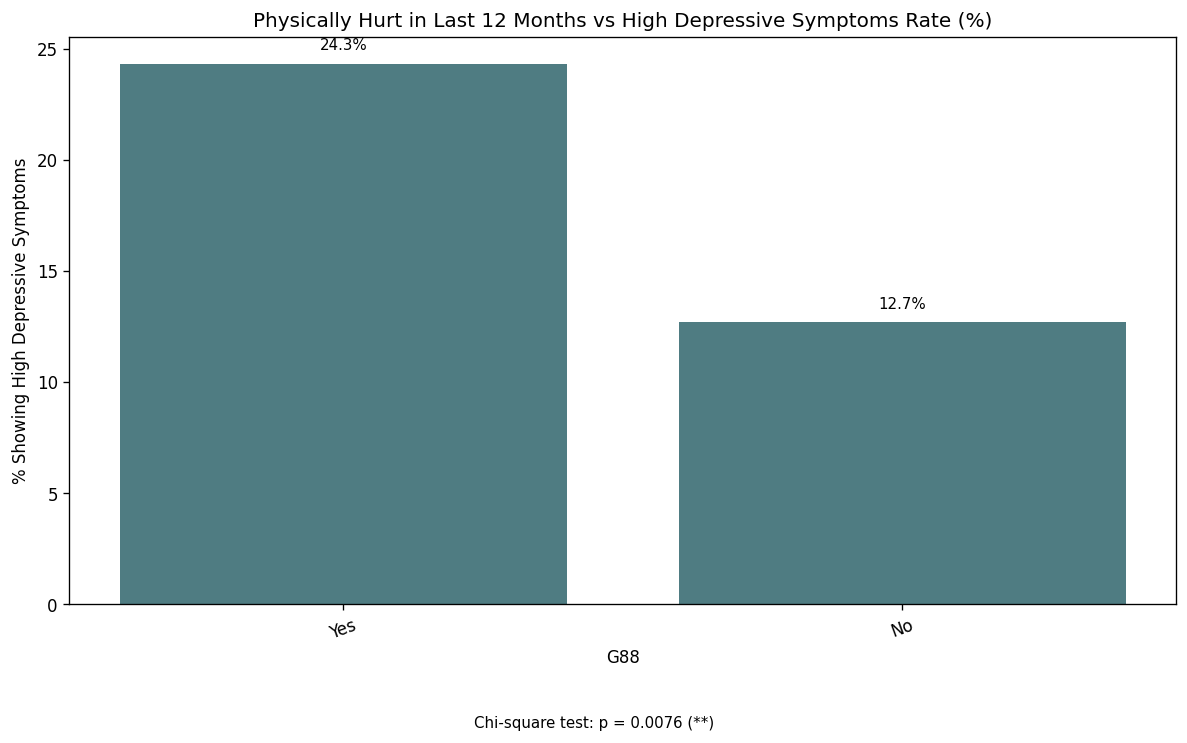

depressed_flag,0,1
G88,,
Yes,75.675676,24.324324
No,87.318841,12.681159


In [47]:
# Physical harm in last 12 months (G88)
plot_depression_rate("G88", title="Physically Hurt in Last 12 Months", save_name="NB2_37_physical_harm_vs_depression.png")

**SYNTHESIS:** The figure shows that respondents who reported being physically hurt in the last 12 months had a higher proportion of high depressive symptoms (24.32%) compared with those who did not report physical harm (12.68%). This suggests a possible association between experiences of physical harm and depressive symptoms among the respondents. However, the observed relationship does not establish causality.

Saved: NB2_38_suicidal_ideation_vs_depression.png


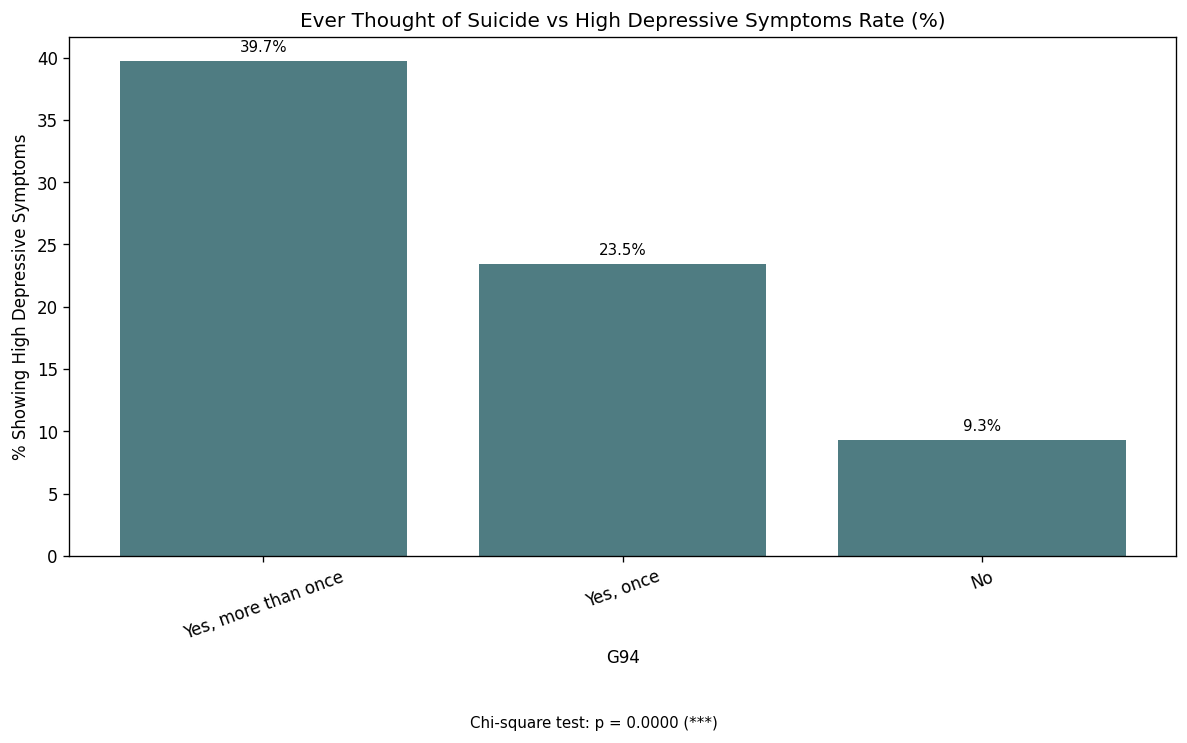

depressed_flag,0,1
G94,,
"Yes, more than once",60.294118,39.705882
"Yes, once",76.530612,23.469388
No,90.688259,9.311741


In [48]:
# Ever thought of suicide (G94)
plot_depression_rate("G94", title="Ever Thought of Suicide", save_name="NB2_38_suicidal_ideation_vs_depression.png")

**SYNTHESIS:** The figure shows that respondents who had thought about suicide more than once had the highest proportion of high depressive symptoms (39.71%), followed by those who had thought about suicide once (23.47%). In contrast, respondents who had never experienced suicidal thoughts had the lowest proportion (9.31%). This pattern indicates an association between a history of suicidal ideation and high depressive symptoms among the respondents. However, the observed relationship does not establish causality.

Saved: NB2_39_suicide_attempt_vs_depression.png


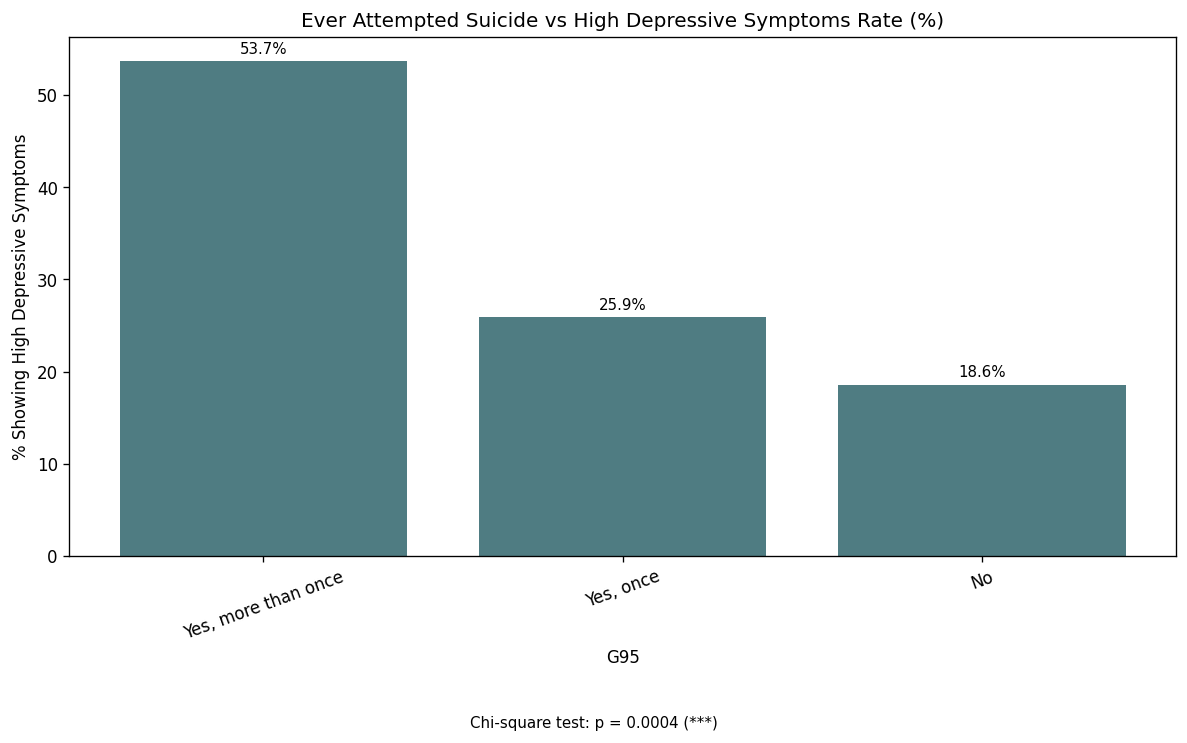

depressed_flag,0,1
G95,,
"Yes, more than once",46.341463,53.658537
"Yes, once",74.074074,25.925926
No,81.428571,18.571429


In [49]:
# Ever tried to commit suicide (G95)
plot_depression_rate("G95", title="Ever Attempted Suicide", save_name="NB2_39_suicide_attempt_vs_depression.png")

**SYNTHESIS:** The figure shows that respondents who reported attempting suicide more than once had the highest proportion of high depressive symptoms (53.66%), followed by those who had attempted suicide once (25.93%). In comparison, respondents who had never attempted suicide had a lower proportion of high depressive symptoms (18.57%). This pattern suggests an association between suicide attempt history and high depressive symptoms among the respondents. However, the observed relationship does not establish causality.

Saved: NB2_40_bmi_vs_depression.png


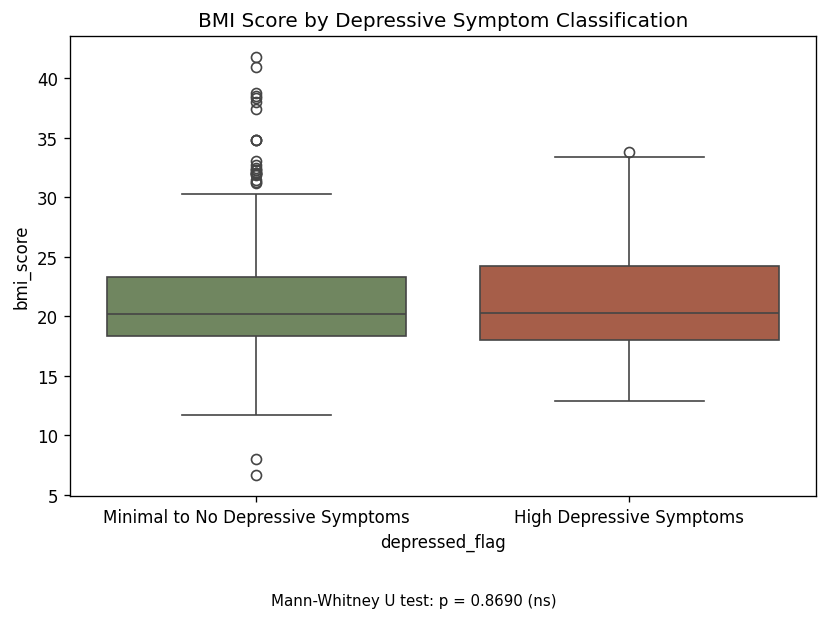

In [50]:
# BMI score (bmi_score)
boxplot("bmi_score", title="BMI Score", save_name="NB2_40_bmi_vs_depression.png")

**SYNTHESIS:** The comparison of BMI scores showed very similar values between respondents with Minimal to No Depressive Symptoms (Mdn = 20.18) and those with High Depressive Symptoms (Mdn = 20.31). The Mann–Whitney U test found no statistically significant difference between the groups (U = 27,163, p = 0.869). This suggests that BMI score was not significantly associated with depressive symptom classification in the NCR sample.

**Theme 8: Puberty & Reproductive Development**

Saved: NB2_41_age_first_sex_vs_depression.png


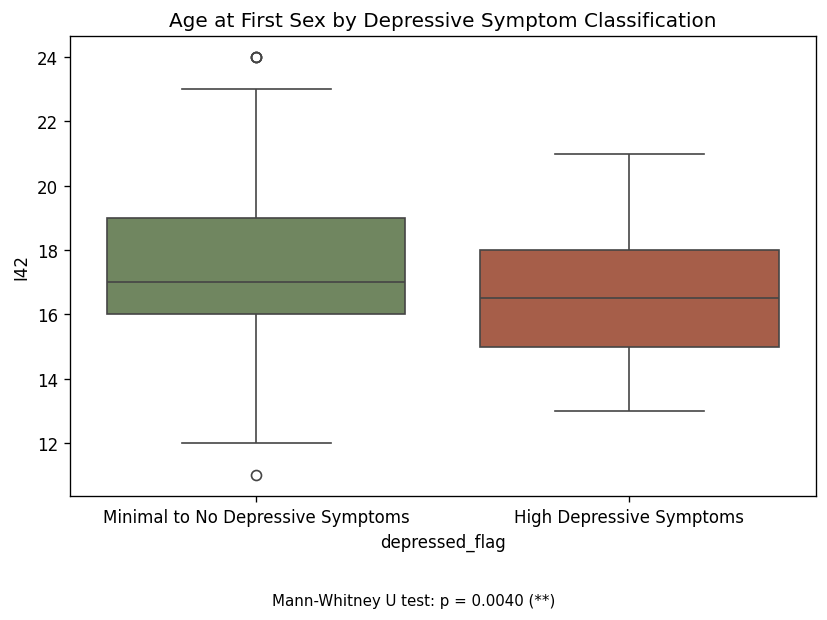

In [51]:
# Age at first sex (I42)
boxplot("I42", title="Age at First Sex", save_name="NB2_41_age_first_sex_vs_depression.png")

**SYNTHESIS:** The comparison of age at first sex showed that respondents with High Depressive Symptoms had a lower median age (Mdn = 17 years) than those with Minimal to No Depressive Symptoms. The Mann–Whitney U test indicated a statistically significant difference between the groups. These findings suggest an association between age at first sex and depressive symptom classification. However, the result should be interpreted cautiously due to the limited number of respondents with available data.

**Theme 9: Pregnancy, Fertility & Maternal Health**

Saved: NB2_42_pregnancy_vs_depression.png


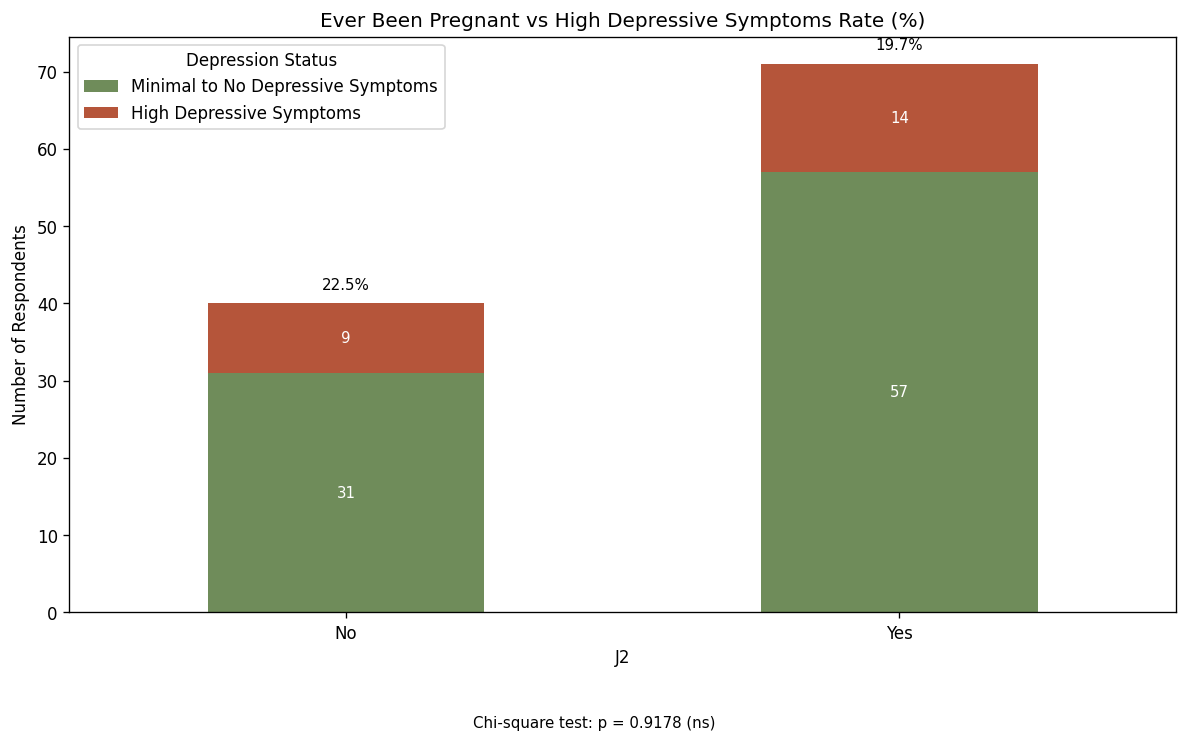

depressed_flag,0,1
J2,,
No,77.50000,22.50000
Yes,80.28169,19.71831


In [52]:
# Ever been pregnant (J2)
plot_stacked_depression("J2", title="Ever Been Pregnant", save_name="NB2_42_pregnancy_vs_depression.png")

**SYNTHESIS:** The figure shows that respondents who had never been pregnant had a slightly higher proportion of high depressive symptoms (22.50%) compared with those who had been pregnant (19.72%). However, the difference between the two groups is relatively small.

Saved: NB2_43_ever_sex_vs_depression.png


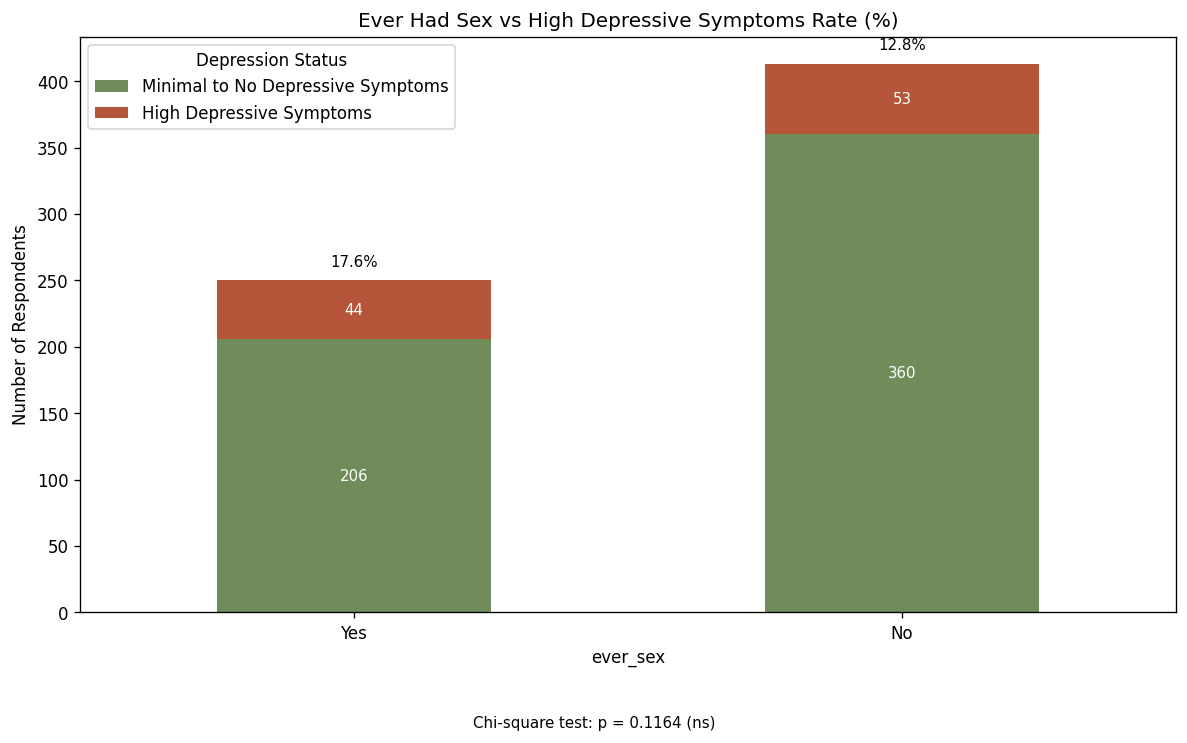

depressed_flag,0,1
ever_sex,,
Yes,82.40000,17.60000
No,87.16707,12.83293


In [53]:
# Ever had sex (ever_sex)
plot_stacked_depression("ever_sex", title="Ever Had Sex", save_name="NB2_43_ever_sex_vs_depression.png")

**SYNTHESIS:** The figure indicates that respondents who reported having had sex had a higher proportion of High Depressive Symptoms (17.60%) compared with those who had never had sex (12.83%). The difference between the two groups was approximately 4.77 percentage points, suggesting a descriptive variation in depressive symptom classification based on sexual experience. However, this observation alone does not establish that engaging in sexual activity causes or contributes to high depressive symptoms, as other personal, social, and contextual factors may also influence the observed pattern.

**Theme 10: Sexual Knowledge, Attitudes & Fertility Preferences**

Saved: NB2_44_divorce_vs_depression.png


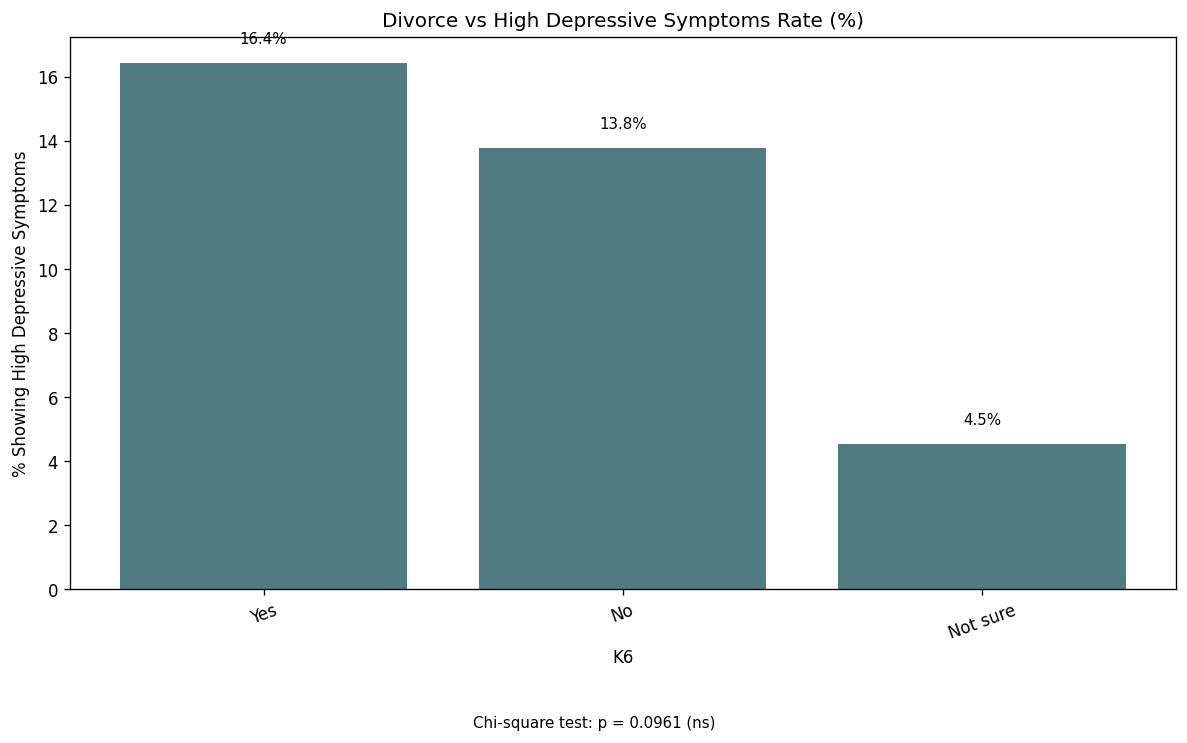

depressed_flag,0,1
K6,,
Yes,83.561644,16.438356
No,86.220472,13.779528
Not sure,95.454545,4.545455


In [54]:
# Divorce (K6)
plot_depression_rate("K6", title="Divorce", save_name="NB2_44_divorce_vs_depression.png")

**SYNTHESIS:** The figure shows variations in the proportion of High Depressive Symptoms across respondents' answers regarding divorce. Respondents who answered Yes had the highest proportion of HDS (16.44%), followed by those who answered No (13.78%). In comparison, respondents who were unsure had the lowest proportion (4.55%). However, the difference between the Yes and No groups was relatively small, while the result for the Not sure category should be interpreted cautiously, particularly if it represents a limited number of respondents. 

**Theme 11: Sexual Orientation & Gender Identity (SOGIESC)**

Saved: NB2_45_gender_identity_vs_depression.png


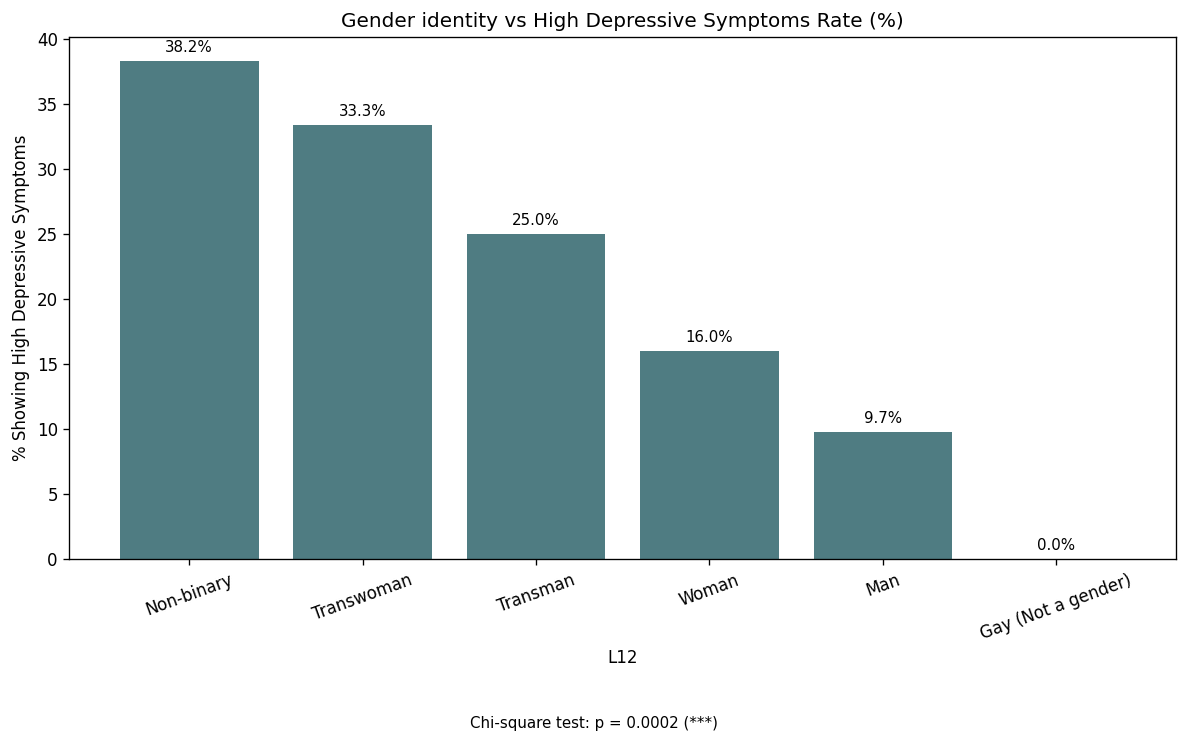

depressed_flag,0,1
L12,,
Non-binary,61.764706,38.235294
Transwoman,66.666667,33.333333
Transman,75.000000,25.000000
Woman,84.049080,15.950920
Man,90.277778,9.722222
Gay (Not a gender),100.000000,0.000000


In [55]:
# Gender identity (L12)
plot_depression_rate("L12", title="Gender identity", save_name="NB2_45_gender_identity_vs_depression.png")

**SYNTHESIS:** The distribution of depressive symptom classification varied across the gender identity categories. Non-binary respondents had the highest proportion of High Depressive Symptoms (38.24%), followed by transwomen (33.33%) and transmen (25.00%). Among respondents identifying as women, 15.95% were classified under HDS, while men had a lower proportion of 9.72%. Meanwhile, the category labeled "Gay (Not a gender)" had no respondents classified under HDS. These findings indicate descriptive differences in the prevalence of high depressive symptoms across the gender identity groups represented in the sample. However, the results should be interpreted cautiously, particularly for categories with potentially small sample sizes, as their percentages may be more sensitive to individual observations. The observed differences do not establish that gender identity causes depressive symptoms.

**Theme 12: COVID-19 Context**

Saved: NB2_46_vaccinated_vs_depression.png


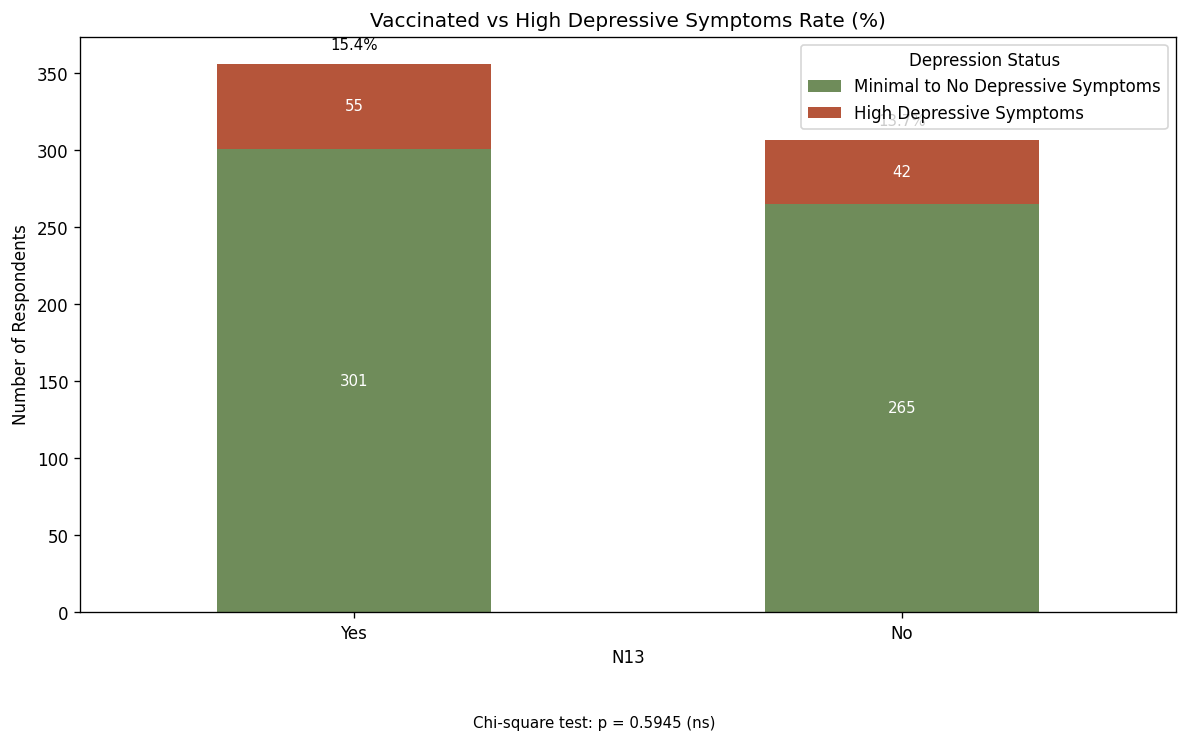

depressed_flag,0,1
N13,,
Yes,84.550562,15.449438
No,86.319218,13.680782


In [56]:
# Vaccinated (N13)
plot_stacked_depression("N13", title="Vaccinated", save_name="NB2_46_vaccinated_vs_depression.png")

**SYNTHESIS:** The figure shows relatively similar proportions of High Depressive Symptoms among respondents who reported being vaccinated and those who reported not being vaccinated. Specifically, 15.45% of vaccinated respondents were classified under HDS, compared with 13.68% of those who were not vaccinated, representing a difference of approximately 1.77 percentage points. This indicates that vaccination status does not demonstrate a substantial descriptive difference in depressive symptom classification among the respondents. Although a slightly higher proportion of HDS was observed among vaccinated individuals, the difference is relatively small and does not necessarily indicate a meaningful relationship between vaccination status and depressive symptoms.

### **Statistical Analysis**

**Define Numerical Variables**

In [57]:
numeric_cols = [
    "A3", "windex_score", "E7",
    "se_score", "sf_score", "G16",
    "bmi_score", "I42"
]

print("Numeric variables used for Mann-Whitney U testing:")
for col in numeric_cols:
    print(f"{col}: {df[col].dtype}")

Numeric variables used for Mann-Whitney U testing:
A3: float64
windex_score: float64
E7: float64
se_score: float64
sf_score: float64
G16: float64
bmi_score: float64
I42: float64


**Mann-Whitney U Tests**

This test is used for numerical features.

In [58]:
mw_results = []

for col in numeric_cols:
    if col not in df.columns:
        continue
    dep = df.loc[
        df["depressed_flag"] == 1,
        col
    ].dropna()
    
    non = df.loc[
        df["depressed_flag"] == 0,
        col
    ].dropna()
    
    if len(dep) < 5 or len(non) < 5:
        continue
    stat, p = mannwhitneyu(
        dep,
        non,
        alternative="two-sided"
    )
    mw_results.append({
        "Variable": col,
        "Test": "Mann-Whitney U",
        "P-value": p,
        "Significant": p < 0.05
    })

mw_df = pd.DataFrame(mw_results)

mw_df["Significance"] = np.select(
    [
        mw_df["P-value"] < 0.001,
        mw_df["P-value"] < 0.01,
        mw_df["P-value"] < 0.05
    ],
    [
        "***",
        "**",
        "*"
    ],
    default=" "
)

mw_df = mw_df.sort_values("P-value")
mw_df

,Variable,Test,P-value,Significant,Significance
3,se_score,Mann-Whitney U,7.326897e-19,True,***
4,sf_score,Mann-Whitney U,6.218487e-05,True,***
7,I42,Mann-Whitney U,3.979477e-03,True,**
5,G16,Mann-Whitney U,6.709134e-03,True,**
1,windex_score,Mann-Whitney U,3.184097e-01,False,
0,A3,Mann-Whitney U,8.159831e-01,False,
6,bmi_score,Mann-Whitney U,8.689808e-01,False,
2,E7,Mann-Whitney U,9.542336e-01,False,


**Define Categorical Variables**

In [59]:
categorical_vars = [
    "hgc3", "A1", "A5",
    "A9", "A25", "A33",
    "B2", "B14", "B15",
    "B31A", "D3", "D8E",
    "D8G", "D9", "E10E",
    "E11Q", "ever_sex", "F5",
    "F7", "F11", "G2",
    "G11", "G27", "G48",
    "G88", "G94", "G95",
    "J2", "N5", "N11"
]

**Chi-Square Tests**

This test is used for categorical features.

In [60]:
chi_results = []

for col in categorical_vars:
    if col not in df.columns:
        continue
    table = pd.crosstab(df[col], df["depressed_flag"])
    if table.shape[0] < 2:
        continue
    try:
        chi2, p, dof, expected = (chi2_contingency(table))
        chi_results.append({
            "Variable": col,
            "Test": "Chi-Square",
            "P-value": p,
            "Significant": p < 0.05
        })
    except:
        pass

chi_df = pd.DataFrame(chi_results)

chi_df["Significance"] = np.select(
    [chi_df["P-value"] < 0.001, chi_df["P-value"] < 0.01, chi_df["P-value"] < 0.05],
    ["***", "**", "*"], default=" ")

chi_df = chi_df.sort_values("P-value")
chi_df

,Variable,Test,P-value,Significant,Significance
25,G94,Chi-Square,5.653228e-12,True,***
12,D8G,Chi-Square,1.806476e-09,True,***
19,F11,Chi-Square,1.279189e-04,True,***
11,D8E,Chi-Square,2.159270e-04,True,***
26,G95,Chi-Square,3.720111e-04,True,***
13,D9,Chi-Square,1.284423e-03,True,**
20,G2,Chi-Square,2.958876e-03,True,**
24,G88,Chi-Square,7.561352e-03,True,**
6,B2,Chi-Square,7.903697e-03,True,**
2,A5,Chi-Square,9.043339e-03,True,**


**Combined Results**

In [61]:
all_tests = pd.concat([mw_df, chi_df], ignore_index=True)
all_tests["Adjusted P-value"] = multipletests(all_tests["P-value"], method="fdr_bh")[1]
all_tests["Significant (FDR)"] = (all_tests["Adjusted P-value"] < 0.05)
all_tests = all_tests.sort_values("P-value")
all_tests

,Variable,Test,P-value,Significant,Significance,Adjusted P-value,Significant (FDR)
0,se_score,Mann-Whitney U,7.326897e-19,True,***,2.637683e-17,True
8,G94,Chi-Square,5.653228e-12,True,***,1.017581e-10,True
9,D8G,Chi-Square,1.806476e-09,True,***,2.167771e-08,True
1,sf_score,Mann-Whitney U,6.218487e-05,True,***,5.596638e-04,True
10,F11,Chi-Square,1.279189e-04,True,***,9.210164e-04,True
11,D8E,Chi-Square,2.159270e-04,True,***,1.295562e-03,True
12,G95,Chi-Square,3.720111e-04,True,***,1.913200e-03,True
13,D9,Chi-Square,1.284423e-03,True,**,5.779903e-03,True
14,G2,Chi-Square,2.958876e-03,True,**,1.183550e-02,True
2,I42,Mann-Whitney U,3.979477e-03,True,**,1.432612e-02,True


**Showing significant features only**

In [62]:
significant_vars = all_tests[all_tests["Significant (FDR)"] == True]

print("=== Variables Significant After FDR Correction ===")
display(significant_vars)

print(f"\nNumber of FDR-significant variables: "f"{len(significant_vars)}")

=== Variables Significant After FDR Correction ===


,Variable,Test,P-value,Significant,Significance,Adjusted P-value,Significant (FDR)
0,se_score,Mann-Whitney U,7.326897e-19,True,***,2.637683e-17,True
8,G94,Chi-Square,5.653228e-12,True,***,1.017581e-10,True
9,D8G,Chi-Square,1.806476e-09,True,***,2.167771e-08,True
1,sf_score,Mann-Whitney U,6.218487e-05,True,***,5.596638e-04,True
10,F11,Chi-Square,1.279189e-04,True,***,9.210164e-04,True
11,D8E,Chi-Square,2.159270e-04,True,***,1.295562e-03,True
12,G95,Chi-Square,3.720111e-04,True,***,1.913200e-03,True
13,D9,Chi-Square,1.284423e-03,True,**,5.779903e-03,True
14,G2,Chi-Square,2.958876e-03,True,**,1.183550e-02,True
2,I42,Mann-Whitney U,3.979477e-03,True,**,1.432612e-02,True



Number of FDR-significant variables: 18


**Summary Counts**

In [63]:
print(f"Total Variables Tested: {len(all_tests)}")
print(f"Significant Variables: " f"{all_tests['Significant (FDR)'].sum()}")
print(f"Not Significant Variables: " f"{len(all_tests) - all_tests['Significant (FDR)'].sum()}")

Total Variables Tested: 36
Significant Variables: 18
Not Significant Variables: 18


**Significant Variables Bar Chart**

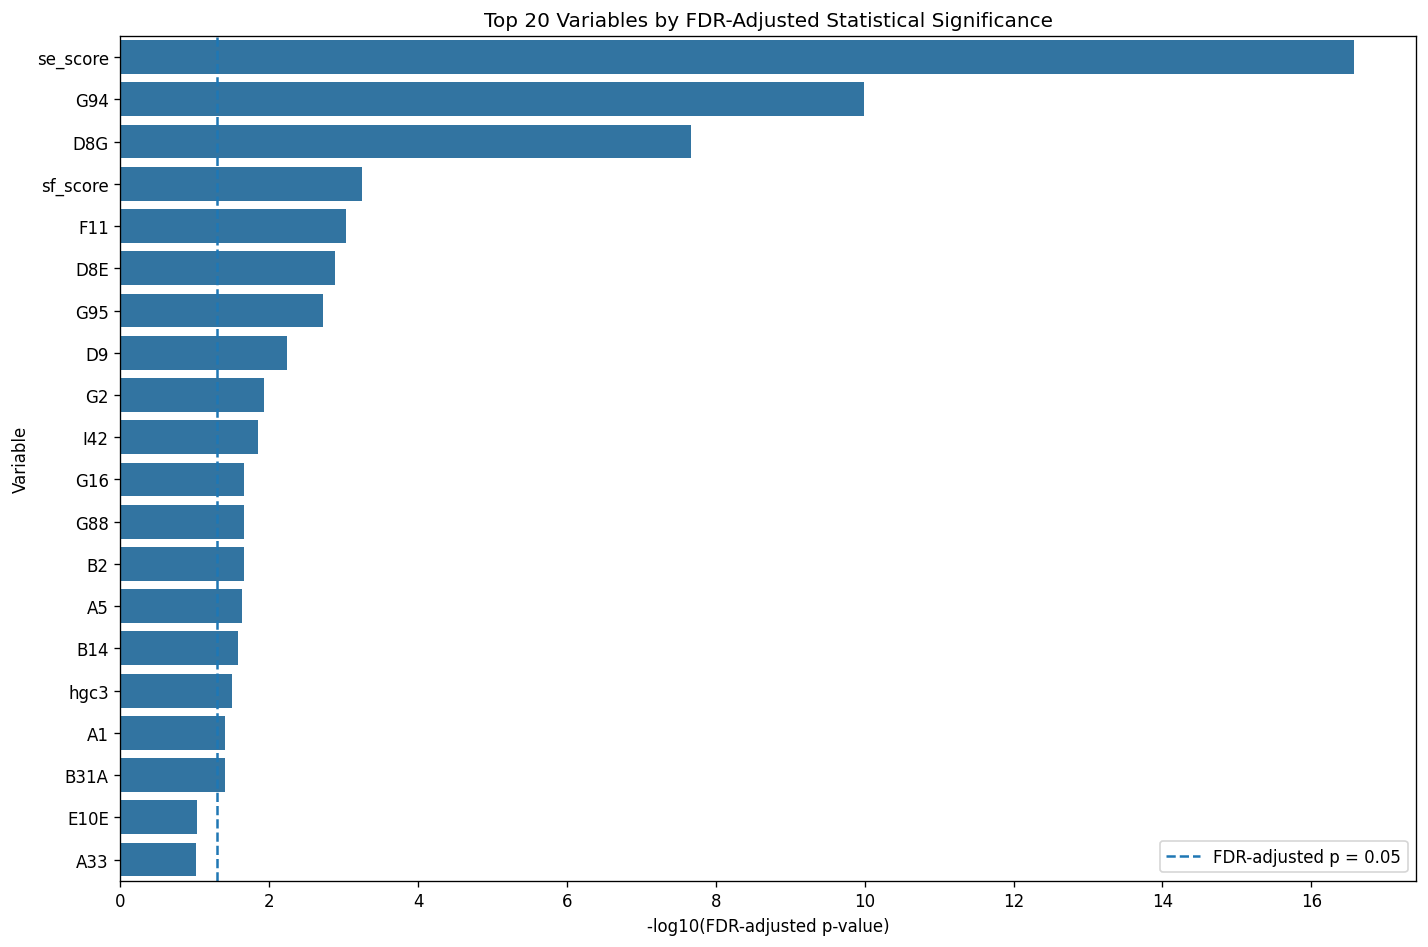

Saved: NB2_47_variables_by_fdr.png


In [84]:
sig = (all_tests.dropna(subset=["Adjusted P-value"]).sort_values("Adjusted P-value").head(20).copy())

# Transform adjusted p-values for visualization
sig["-log10(FDR-adjusted p)"] = -np.log10(sig["Adjusted P-value"].clip(lower=1e-300))

# Plot
plt.figure(figsize=(12, 8))

ax = sns.barplot(data=sig, x="-log10(FDR-adjusted p)", y="Variable")

# FDR significance threshold: adjusted p = 0.05
ax.axvline(-np.log10(0.05), linestyle="--", linewidth=1.5, label="FDR-adjusted p = 0.05")

plt.title("Top 20 Variables by FDR-Adjusted Statistical Significance")

plt.xlabel("-log10(FDR-adjusted p-value)")
plt.ylabel("Variable")

plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "NB2_47_variables_by_fdr.png"), bbox_inches='tight')
plt.show()
print("Saved: NB2_47_variables_by_fdr.png")

**SYNTHESIS:** The figure highlights the variables most strongly associated with depression based on statistical significance. The results indicate that depression is most strongly linked to how individuals perceive themselves and whether they experience thoughts or behaviors related to self-harm. Educational experiences also appear to play an important role. Rather than being driven by a single factor, depression appears to be associated with a combination of psychological, behavioral, and educational influences.

**Define Themes**

In [65]:
theme_vars = {

    "Socio-demographic Profile": [
        "A1", "A3", "A5",
        "A8", "A9", "A25",
        "A33", "hgc3","windex_score",
    ],

    "Family and Home Environment": [
        "B2", "B14", "B15",
        "B31A"
    ],

    "Subjective Well-being and Life Satisfaction": [
        "C1A", "C3", "C4",
        "C5"
    ],

    "School, Work, and Civic Engagement": [
        "D3", "D6", "D8E", 
        "D8G", "D9" 
    ],

    "ICT, Internet, and Media Use": [
        "E7", "E10E", "E11Q"
    ],

    "Mental Health & Well-being": [
        "F5", "F7", "F11",
        "se_score", "sf_score"
    ],

    "Subjective Health, Lifestyle, Health Risk Behaviors": [
        "G2", "G11", "G16",
        "G27", "G48", "G88",
        "G94", "G95", "bmi_score"
    ],

    "Puberty & Reproductive Development": [
        "I42"
    ],

    "Pregnancy, Fertility & Maternal Health": [
        "J2", "ever_sex"
    ],

    "Sexual Knowledge, Attitudes & Fertility Preferences": [
        "K6",
    ],

    "Sexual Orientation & Gender Identity (SOGIESC)": [
        "L12",
    ],

    "COVID-19 Experiences": [
        "N13"
    ]
}

**Theme-Level Significance**

In [66]:
theme_sig = []

for theme, vars_ in theme_vars.items():
    tested = []
    sig = []
    for var in vars_:
        if var in all_tests["Variable"].values:
            tested.append(var)
            p = all_tests.loc[all_tests["Variable"] == var, "P-value"].iloc[0]
            adjusted_p = all_tests.loc[
            all_tests["Variable"] == var, "Adjusted P-value"].iloc[0]

            if adjusted_p < 0.05:
                sig.append(var)
    theme_sig.append({"Theme": theme, "Variables Tested": len(tested), "Significant Variables": len(sig),
        "% FDR Significant": round(len(sig) / len(tested) * 100, 1) if len(tested) > 0 else 0
    })

theme_sig_df = pd.DataFrame(theme_sig)
theme_sig_df.sort_values("% FDR Significant", ascending=False)

,Theme,Variables Tested,Significant Variables,% FDR Significant
7,Puberty & Reproductive Development,1,1,100.0
1,Family and Home Environment,4,3,75.0
3,"School, Work, and Civic Engagement",4,3,75.0
5,Mental Health & Well-being,5,3,60.0
6,"Subjective Health, Lifestyle, Health Risk Beha...",9,5,55.6
0,Socio-demographic Profile,8,3,37.5
2,Subjective Well-being and Life Satisfaction,0,0,0.0
4,"ICT, Internet, and Media Use",3,0,0.0
8,"Pregnancy, Fertility & Maternal Health",2,0,0.0
9,"Sexual Knowledge, Attitudes & Fertility Prefer...",0,0,0.0


**Theme Significance Graph**

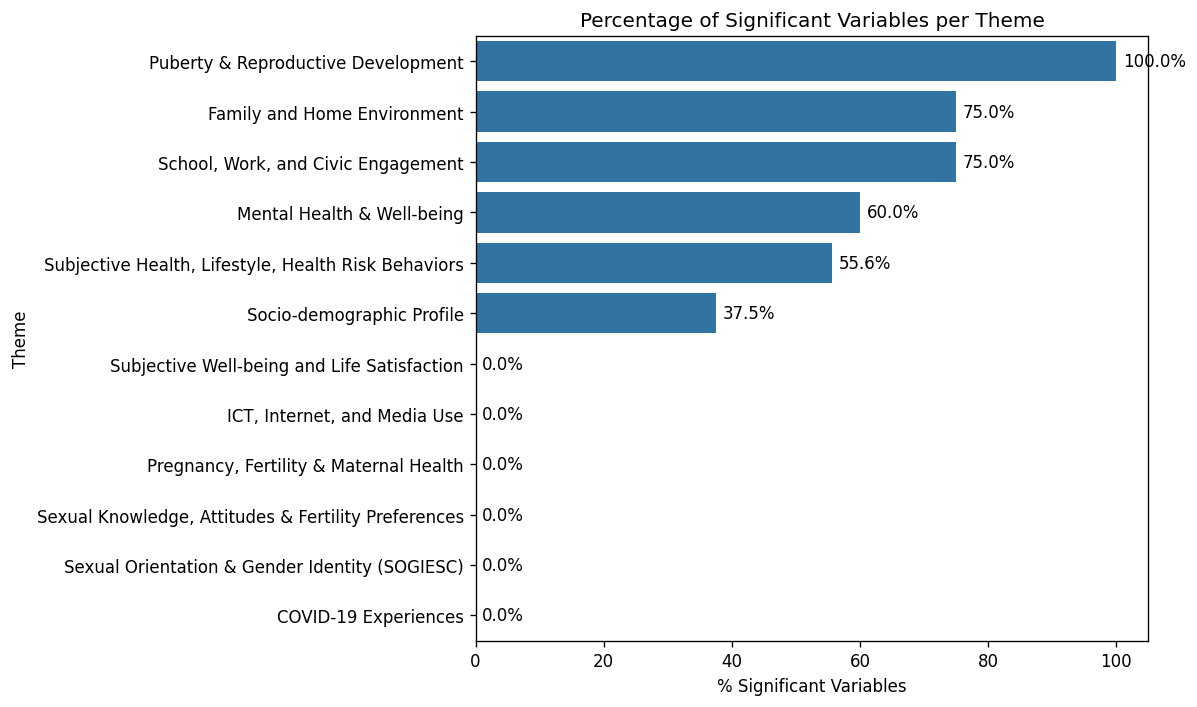

Saved: NB2_45_significant_vars_per_theme.png


In [67]:
plt.figure(figsize=(10,6))

theme_sig_df = (theme_sig_df.sort_values("% FDR Significant", ascending=False))

ax = sns.barplot(data=theme_sig_df, x="% FDR Significant", y="Theme")

for i, v in enumerate(theme_sig_df["% FDR Significant"]):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")

plt.title("Percentage of Significant Variables per Theme")
plt.xlabel("% Significant Variables")
plt.ylabel("Theme")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "NB2_49_significant_vars_per_theme.png"), bbox_inches='tight')
plt.show()
print("Saved: NB2_45_significant_vars_per_theme.png")

**SYNTHESIS:** The figure shows that some themes contained a larger proportion of tested variables that reached FDR-adjusted statistical significance. This summary reflects the distribution of statistically significant bivariate associations within each theme and should not be interpreted as a ranking of the themes' predictive importance or overall effect strength

**Spearman Correlation Between Similar Constructs**

In [68]:
def to_numeric_safe(series):
    return pd.to_numeric(series, errors="coerce")


similar_pairs = [
    ("se_score", "sf_score", "Self-Esteem vs Self-Efficacy"),
    ("C3",       "C4",       "Life Satisfaction vs Financial Satisfaction"),
    ("C3",       "C5",       "Life Satisfaction vs Happiness"),
    ("C4",       "C5",       "Financial Satisfaction vs Happiness"),
    ("G94",      "G95",      "Suicidal Ideation vs Suicide Attempt"),
    ("G27",      "G48",      "Current Smoking vs Current Drinking"),
]

print("=" * 90)
print("SPEARMAN CORRELATION: SIMILAR / RELATED CONSTRUCTS")
print("=" * 90)
print(f"{'Pair':<45} {'Spearman ρ':>12} {'p-value':>12} {'Interpretation':>18}")
print("-" * 90)

for var1, var2, label in similar_pairs:

    # Check that both variables exist
    if var1 not in df.columns or var2 not in df.columns:
        print(f"  SKIP: {label} — column missing")
        continue

    # Convert only genuinely numeric values
    v1 = to_numeric_safe(df[var1])
    v2 = to_numeric_safe(df[var2])

    # Keep only observations with valid values for BOTH variables
    valid = pd.DataFrame({"v1": v1, "v2": v2}).dropna()

    if len(valid) < 10:
        print(f"  SKIP: {label} — insufficient valid paired observations "f"(n={len(valid)})")
        continue

    # Spearman correlation
    r, p = spearmanr(valid["v1"], valid["v2"])

    # Flag potentially strong correlation
    if abs(r) >= 0.70:
        interpretation = "⚠ High correlation"
    else:
        interpretation = "✓ Below threshold"

    # Format p-value
    p_display = "< 0.0001" if p < 0.0001 else f"{p:.4f}"

    print(
        f"{label:<45} "
        f"{r:>12.3f} "
        f"{p_display:>12} "
        f"{interpretation:>18}"
    )

print("=" * 90)
print("Note: Only variables with valid numeric/ordinal numerical coding are included.")
print("Missing or non-numeric values are excluded pairwise.")
print("Rule of thumb: |ρ| < 0.70 → lower correlation")
print("               |ρ| ≥ 0.70 → potentially high correlation; review for redundancy")

SPEARMAN CORRELATION: SIMILAR / RELATED CONSTRUCTS
Pair                                            Spearman ρ      p-value     Interpretation
------------------------------------------------------------------------------------------
Self-Esteem vs Self-Efficacy                         0.458     < 0.0001  ✓ Below threshold
Life Satisfaction vs Financial Satisfaction          0.566     < 0.0001  ✓ Below threshold
Life Satisfaction vs Happiness                       0.514     < 0.0001  ✓ Below threshold
Financial Satisfaction vs Happiness                  0.355     < 0.0001  ✓ Below threshold
  SKIP: Suicidal Ideation vs Suicide Attempt — insufficient valid paired observations (n=0)
  SKIP: Current Smoking vs Current Drinking — insufficient valid paired observations (n=0)
Note: Only variables with valid numeric/ordinal numerical coding are included.
Missing or non-numeric values are excluded pairwise.
Rule of thumb: |ρ| < 0.70 → lower correlation
               |ρ| ≥ 0.70 → potentially hi

### **Comparative Analysis of Psychological Constructs**

**One-Way ANOVA**

In [79]:
psych_cluster = {
    "Self-Esteem (se_score)": "se_score",
    "Self-Efficacy (sf_score)": "sf_score",
    "Life Satisfaction (C3)": "C3",
    "Financial Satisfaction (C4)": "C4",
    "Happiness (C5)": "C5"
}

print("=" * 85)
print("ONE-WAY ANOVA: Psychological Constructs vs. Depression Symptom Classification")
print("=" * 85)
print(f"{'Variable':<28} {'F-stat':>9} {'p-value':>10} {'Sig':>5}")
print("-" * 85)

anova_results = []
for label, var in psych_cluster.items():
    col = df[var]
    # convert to numeric if ordinal-coded as string
    col_num = pd.to_numeric(col, errors='coerce')
    dep_vals = col_num[df["depressed_flag"] == 1].dropna()
    non_vals = col_num[df["depressed_flag"] == 0].dropna()
    if len(dep_vals) < 5 or len(non_vals) < 5:
        continue
    f_stat, p_val = f_oneway(dep_vals, non_vals)
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
    print(f"{label:<28} {f_stat:>9.3f} {p_val:>10.4f} {sig:>5}")
    anova_results.append({"Variable": label, "F-stat": round(f_stat, 3),
                          "p-value": round(p_val, 4), "Significance": sig})

anova_df = pd.DataFrame(anova_results)
print("=" * 85)

ONE-WAY ANOVA: Psychological Constructs vs. Depression Symptom Classification
Variable                        F-stat    p-value   Sig
-------------------------------------------------------------------------------------
Self-Esteem (se_score)          98.730     0.0000   ***
Self-Efficacy (sf_score)        21.102     0.0000   ***
Life Satisfaction (C3)          27.313     0.0000   ***
Financial Satisfaction (C4)      3.097     0.0789    ns
Happiness (C5)                  56.603     0.0000   ***


**Bar chart of F-statistics for psychological construct ANOVA**

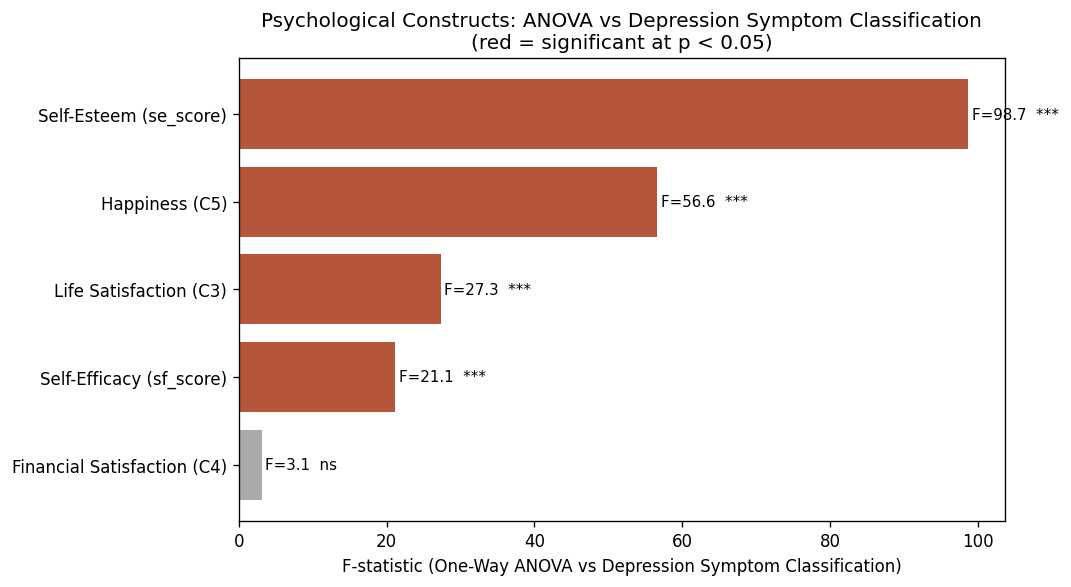

Saved: NB2_46_ANOVA_psych_constructs.png


In [80]:
if anova_results:
    sorted_results = sorted(anova_results, key=lambda r: r['F-stat'])  # ascending = top bar is highest

    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ['#B5553A' if r['p-value'] < 0.05 else '#aaaaaa' for r in sorted_results]
    bars = ax.barh([r['Variable'] for r in sorted_results],
                   [r['F-stat'] for r in sorted_results],
                   color=colors)
    for bar, r in zip(bars, sorted_results):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f"F={r['F-stat']:.1f}  {r['Significance']}",
                va='center', fontsize=9)
    ax.set_xlabel("F-statistic (One-Way ANOVA vs Depression Symptom Classification)")
    ax.set_title("Psychological Constructs: ANOVA vs Depression Symptom Classification\n(red = significant at p < 0.05)")
    ax.axvline(x=0, color='black', linewidth=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "NB2_50_ANOVA_psych_constructs.png"), bbox_inches='tight')
    plt.show()
    print("Saved: NB2_46_ANOVA_psych_constructs.png")

**SYNTHESIS:** Since both se_score and sf_score are significant (p-value = 0.00), they each independently differentiate depressed from non-depressed respondents, supporting retention of both as separate predictors.

**Spearman Correlation Between Similar Constructs**

In [83]:
def to_numeric_safe(series):
    return pd.to_numeric(series, errors="coerce")


similar_pairs = [
    ("se_score", "sf_score", "Self-Esteem vs Self-Efficacy"),
    ("C3",       "C4",       "Life Satisfaction vs Financial Satisfaction"),
    ("C3",       "C5",       "Life Satisfaction vs Happiness"),
    ("C4",       "C5",       "Financial Satisfaction vs Happiness"),
    ("G94",      "G95",      "Suicidal Ideation vs Suicide Attempt"),
    ("G27",      "G48",      "Current Smoking vs Current Drinking"),
]

print("=" * 90)
print("SPEARMAN CORRELATION: SIMILAR / RELATED CONSTRUCTS")
print("=" * 90)
print(f"{'Pair':<45} {'Spearman ρ':>12} {'p-value':>12} {'Interpretation':>18}")
print("-" * 90)

for var1, var2, label in similar_pairs:

    # Check that both variables exist
    if var1 not in df.columns or var2 not in df.columns:
        print(f"  SKIP: {label} — column missing")
        continue

    # Convert only genuinely numeric values
    v1 = to_numeric_safe(df[var1])
    v2 = to_numeric_safe(df[var2])

    # Keep only observations with valid values for BOTH variables
    valid = pd.DataFrame({"v1": v1, "v2": v2}).dropna()

    if len(valid) < 10:
        print(f"  SKIP: {label} — insufficient valid paired observations "f"(n={len(valid)})")
        continue

    # Spearman correlation
    r, p = spearmanr(valid["v1"], valid["v2"])

    # Flag potentially strong correlation
    if abs(r) >= 0.70:
        interpretation = "⚠ High correlation"
    else:
        interpretation = "✓ Below threshold"

    # Format p-value
    p_display = "< 0.0001" if p < 0.0001 else f"{p:.4f}"

    print(
        f"{label:<45} "
        f"{r:>12.3f} "
        f"{p_display:>12} "
        f"{interpretation:>18}"
    )

print("=" * 90)
print("Note: Only variables with valid numeric/ordinal numerical coding are included.")
print("Missing or non-numeric values are excluded pairwise.")
print("Rule of thumb: |ρ| < 0.70 → lower correlation")
print("               |ρ| ≥ 0.70 → potentially high correlation; review for redundancy")

SPEARMAN CORRELATION: SIMILAR / RELATED CONSTRUCTS
Pair                                            Spearman ρ      p-value     Interpretation
------------------------------------------------------------------------------------------
Self-Esteem vs Self-Efficacy                         0.458     < 0.0001  ✓ Below threshold
Life Satisfaction vs Financial Satisfaction          0.566     < 0.0001  ✓ Below threshold
Life Satisfaction vs Happiness                       0.514     < 0.0001  ✓ Below threshold
Financial Satisfaction vs Happiness                  0.355     < 0.0001  ✓ Below threshold
  SKIP: Suicidal Ideation vs Suicide Attempt — insufficient valid paired observations (n=0)
  SKIP: Current Smoking vs Current Drinking — insufficient valid paired observations (n=0)
Note: Only variables with valid numeric/ordinal numerical coding are included.
Missing or non-numeric values are excluded pairwise.
Rule of thumb: |ρ| < 0.70 → lower correlation
               |ρ| ≥ 0.70 → potentially hi

### **McNemar Test for Paired Binary Variables**

This tests whether two related binary variables have different marginal proportions for the same respondent. It is used here to confirm that paired items are not interchangeable.

In [77]:
def run_mcnemar(var1, var2, label, pos_values_1, pos_values_2):
    """
    McNemar test for paired binary variables.
    pos_values_1: exact string values that count as 'positive' for var1
    pos_values_2: exact string values that count as 'positive' for var2
    All other values (including NaN) are treated as negative (0).
    """
    if var1 not in df.columns or var2 not in df.columns:
        print(f"  SKIP: {label} — column missing")
        return

    valid = df[[var1, var2]].dropna()
    v1 = valid[var1].apply(lambda x: 1 if str(x).strip() in pos_values_1 else 0)
    v2 = valid[var2].apply(lambda x: 1 if str(x).strip() in pos_values_2 else 0)

    tt = ((v1 == 1) & (v2 == 1)).sum()
    b  = ((v1 == 1) & (v2 == 0)).sum()
    c  = ((v1 == 0) & (v2 == 1)).sum()
    ff = ((v1 == 0) & (v2 == 0)).sum()

    table = [[tt, b], [c, ff]]

    if (b + c) == 0:
        print(f"  {label}")
        print(f"    ⚠ b=0, c=0 — no discordant pairs detected.")
        print(f"    Check that pos_values match actual data strings exactly.\n")
        return

    use_exact = (b + c) < 25
    result    = mcnemar(table, exact=use_exact)

    sig       = ("***" if result.pvalue < 0.001 else
                 "**"  if result.pvalue < 0.01  else
                 "*"   if result.pvalue < 0.05  else "ns")
    p_display = "< 0.0001" if result.pvalue < 0.0001 else f"{result.pvalue:.4f}"
    method    = "exact binomial" if use_exact else "chi-square approx"
    pct1      = v1.mean() * 100
    pct2      = v2.mean() * 100

    print(f"  {label}  [{method}]")
    print(f"    {var1} positive: {pct1:.1f}%  |  {var2} positive: {pct2:.1f}%")
    print(f"    Contingency: TT={tt}, b={b}, c={c}, FF={ff}  (discordant: b+c={b+c})")
    print(f"    McNemar χ² = {result.statistic:.3f}, p = {p_display}  {sig}")
    print(f"    Complete paired observations: {len(valid)}")
    print(f"    → {'Proportions significantly differ — variables are NOT interchangeable' if result.pvalue < 0.05 else 'No significant difference — variables may overlap'}\n")


print("=" * 70)
print("McNEMAR TEST: Are Paired Binary Variables Distinct?")
print("=" * 70)
print("Note: 'Positive' is defined per variable based on actual YAFS5 codings.")
print("      NaN and all unlisted values are treated as negative (0).")
print("=" * 70 + "\n")

# --- Pair 1: G94 vs G95 ---
# G94: "Yes, once" or "Yes, more than once" = has had suicidal ideation
# G95: "Yes, once" or "Yes, more than once" = has attempted suicide
# G95 also has "Never thought of committing suicide" and "No" — both = negative
run_mcnemar(
    "G94", "G95",
    "Suicidal Ideation (G94) vs Suicide Attempt (G95)",
    pos_values_1=["Yes, once", "Yes, more than once"],
    pos_values_2=["Yes, once", "Yes, more than once"]
)

# --- Pair 2: F5 vs F11 ---
# F5: Share problems with close friends — Yes/No
# F11: Share problems on social media — Yes/No
run_mcnemar(
    "F5", "F11",
    "Share w/ Friends (F5) vs Share on Social Media (F11)",
    pos_values_1=["Yes"],
    pos_values_2=["Yes"]
)

# --- Pair 3: G27 vs G48 ---
# G27: Currently smoking = "Yes"; negative = "No" (former/non-current) or "Never smoked"
# G48: Currently drinking = "Yes"; negative = "No" or "Never tried drinking alcohol"
# Note: Both variables have two distinct negative states (never vs not-currently). 'Positive' is defined as currently active use only.
run_mcnemar(
    "G27", "G48",
    "Currently Smoking (G27) vs Currently Drinking (G48)",
    pos_values_1=["Yes"],
    pos_values_2=["Yes"]
)

# --- Pair 4: ever_sex vs J2 ---
# ever_sex: "Yes" = has had sex
# J2: "Yes" = has been pregnant; NaN (never-had-sex respondents) treated as "No"
run_mcnemar(
    "ever_sex", "J2",
    "Ever Had Sex (ever_sex) vs Ever Been Pregnant (J2)",
    pos_values_1=["Yes"],
    pos_values_2=["Yes"]
)

McNEMAR TEST: Are Paired Binary Variables Distinct?
Note: 'Positive' is defined per variable based on actual YAFS5 codings.
      NaN and all unlisted values are treated as negative (0).

  Suicidal Ideation (G94) vs Suicide Attempt (G95)  [chi-square approx]
    G94 positive: 100.0%  |  G95 positive: 57.6%
    Contingency: TT=95, b=70, c=0, FF=0  (discordant: b+c=70)
    McNemar χ² = 68.014, p = < 0.0001  ***
    Complete paired observations: 165
    → Proportions significantly differ — variables are NOT interchangeable

  Share w/ Friends (F5) vs Share on Social Media (F11)  [chi-square approx]
    F5 positive: 84.4%  |  F11 positive: 11.2%
    Contingency: TT=63, b=450, c=5, FF=90  (discordant: b+c=455)
    McNemar χ² = 433.266, p = < 0.0001  ***
    Complete paired observations: 608
    → Proportions significantly differ — variables are NOT interchangeable

  Currently Smoking (G27) vs Currently Drinking (G48)  [chi-square approx]
    G27 positive: 39.9%  |  G48 positive: 71.0%
   

### **Correlation Analysis**

This step involves Spearman correlation of numeric predictors with the target variable, depressed_flag.

In [69]:
# Selected numerical and ordinal variables
correlation_vars = [
    "A3",
    "windex_score",
    "E7",
    "se_score",
    "sf_score",
    "G16",
    "bmi_score",
    "I42"
]

# Retain selected variables and the target
numeric_df = df[correlation_vars + ["depressed_flag"]].copy()

# Ensure all selected columns are numeric
for col in numeric_df.columns:
    numeric_df[col] = pd.to_numeric(numeric_df[col], errors="coerce")

# Calculate Spearman correlations with HDS classification
corr = (
    numeric_df
    .corr(method="spearman")["depressed_flag"]
    .drop("depressed_flag")
    .dropna()
    .sort_values(key=abs, ascending=False)
)

print("Spearman Correlation with HDS Classification")
print("=" * 60)
print(corr.to_string())

Spearman Correlation with HDS Classification
se_score       -0.344746
I42            -0.199304
sf_score       -0.155645
G16            -0.105375
windex_score   -0.038789
A3             -0.009056
bmi_score       0.006422
E7             -0.002256


**Graphing the top numeric features correlated with depressed_flag**

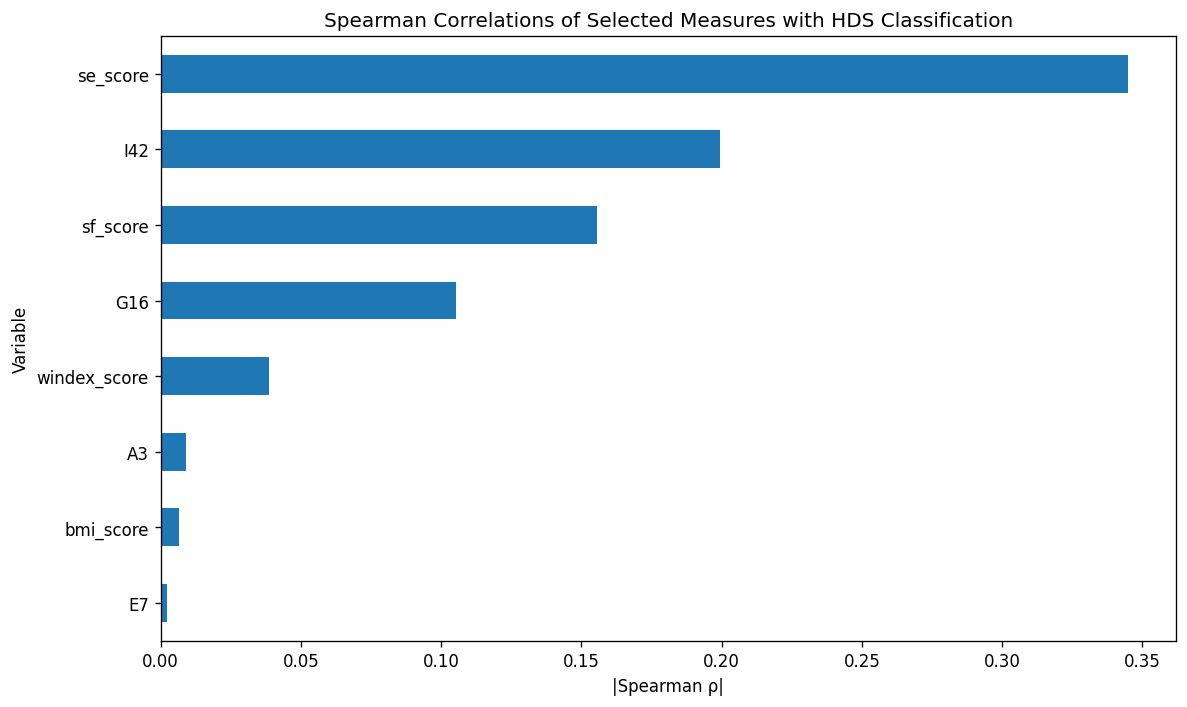

Saved: NB2_50_top_correlations.png


In [70]:
# Rank selected variables by absolute correlation
top_corr = corr.abs().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))

top_corr.sort_values().plot(kind="barh", ax=ax)

ax.set_title("Spearman Correlations of Selected Measures with HDS Classification")
ax.set_xlabel("|Spearman ρ|")
ax.set_ylabel("Variable")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "NB2_50_top_correlations.png"), bbox_inches="tight", dpi=300)
plt.show()

print("Saved: NB2_50_top_correlations.png")

**SYNTHESIS:** The Spearman correlation analysis showed that self-esteem (`se_score`) had the strongest negative correlation with HDS classification (ρ = -0.345), followed by I42 (ρ = -0.199), self-efficacy (`sf_score`, ρ = -0.156), and G16 (ρ = -0.105). The remaining variables showed very weak correlations with HDS classification. These findings indicate that higher self-esteem and self-efficacy scores tended to be associated with lower HDS classification values. However, the correlations describe bivariate relationships and do not establish causal effects or independent associations.

**Heatmap of inter-correlations among the top 20 numeric features**

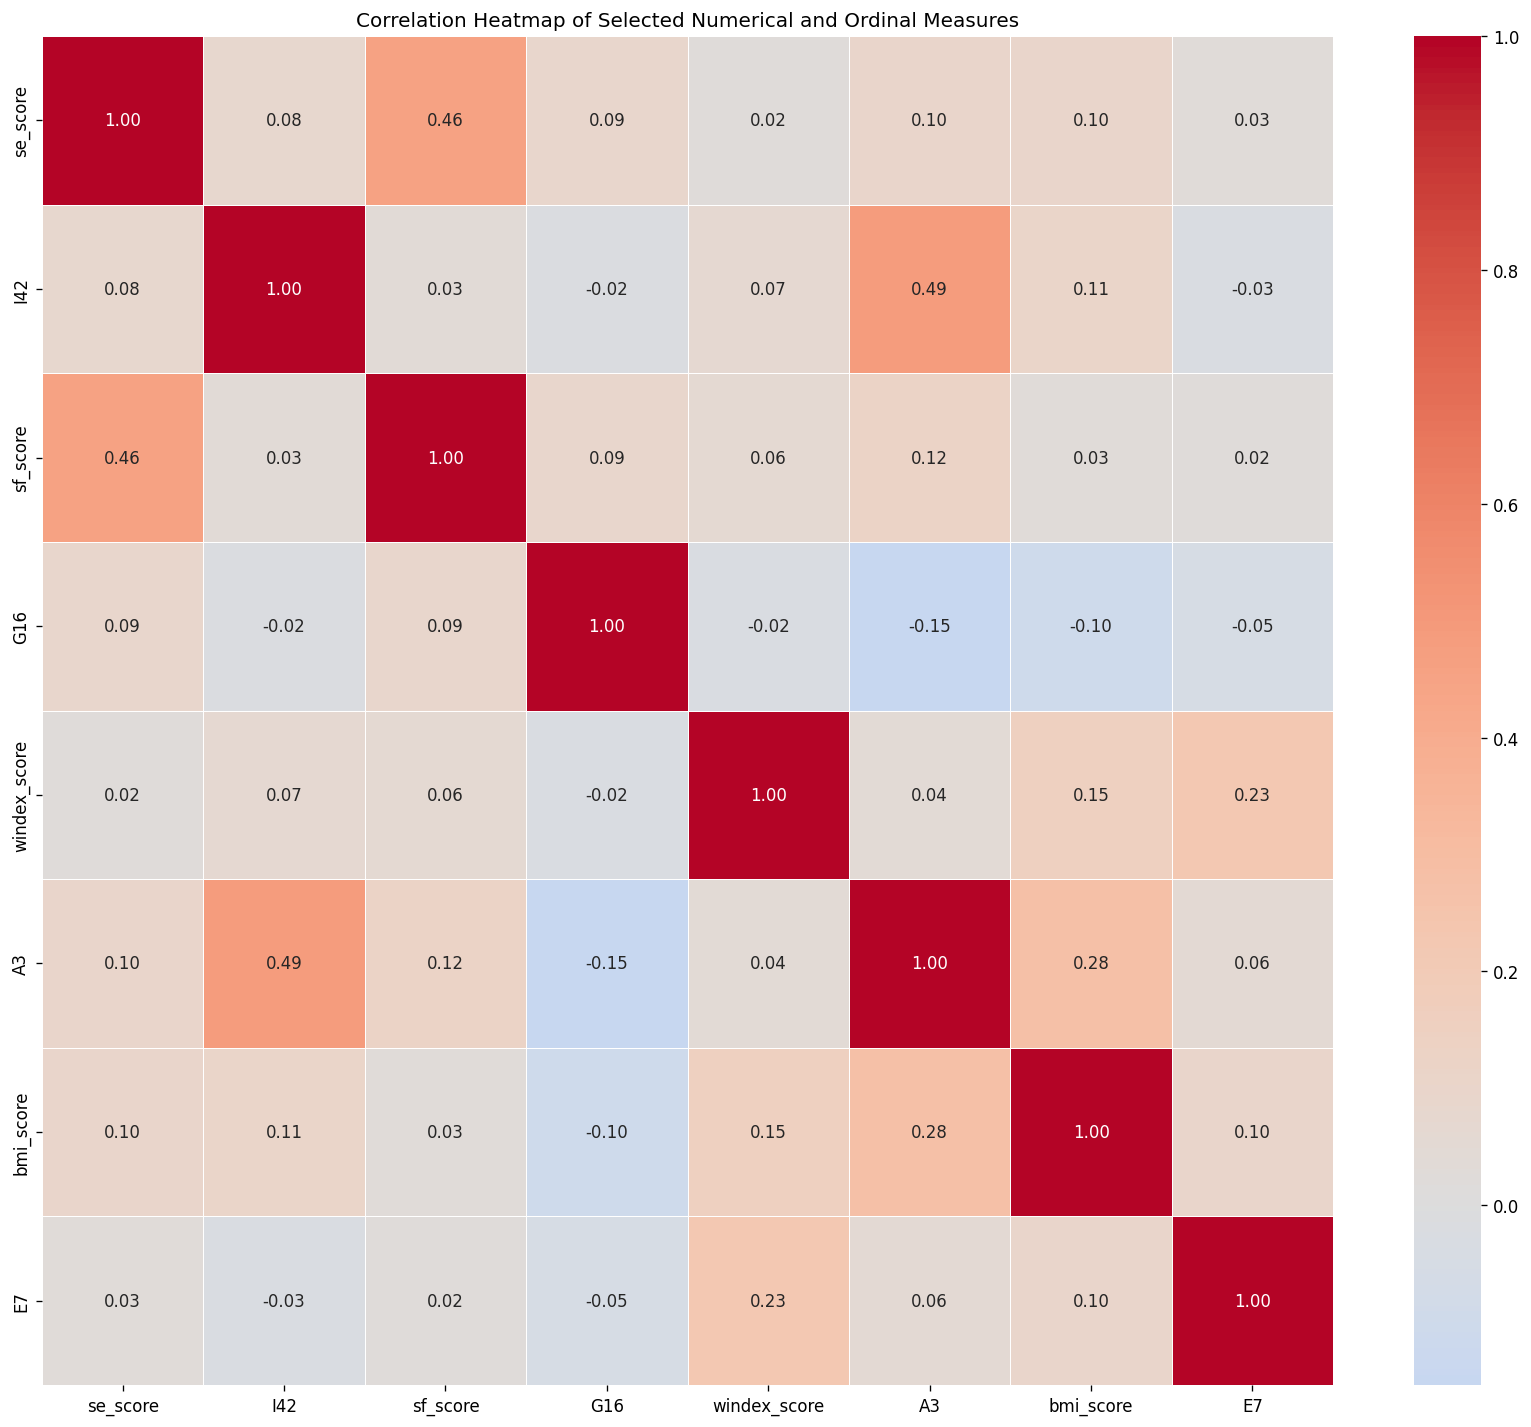

Saved: NB2_52_correlation_heatmap.png


In [71]:
top_features = top_corr.index.tolist()
corr_matrix = numeric_df[top_features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=True, cmap="coolwarm", center=0, fmt=".2f",
    linewidths=0.5, ax=ax
)
ax.set_title("Correlation Heatmap of Selected Numerical and Ordinal Measures")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "NB2_52_correlation_heatmap.png"), bbox_inches='tight')
plt.show()
print("Saved: NB2_52_correlation_heatmap.png")

**SYNTHESIS:** The correlation heatmap presents the relationships among the selected numerical and ordinal measures. It provides a supplementary view of how the variables are associated with one another, particularly the psychological measures and other respondent characteristics. The observed correlations help identify variables that may share similar patterns of variation. However, these relationships should not be interpreted as evidence of causation or independent contributions to HDS classification.

### **Summary Table**

In [72]:
summary = pd.DataFrame({
    "Variable":       df.columns,
    "DType":          df.dtypes.values,
    "Missing Values": df.isnull().sum().values,
    "Unique Values":  df.nunique().values
})

print(f"Total variables: {len(summary)}")
print(f"Columns with any missing value: {(summary['Missing Values'] > 0).sum()}")
print(summary.head(20).to_string(index=False))

Total variables: 155
Columns with any missing value: 74
Variable   DType  Missing Values  Unique Values
     G94  object               3              3
se_score float64               0             23
     G95  object             498              3
      D1  object               0              4
    B31A  object               0              5
      G1  object               0              4
      C5 float64               0             10
    B31F  object               0              5
     G24  object               0              2
    I113  object               0              2
     G61  object             154              2
sf_score float64               0             22
      C3 float64               0             10
    I102 float64             413             10
    B4_1  object               8              2
     E13  object               0              2
     K26  object             592              3
     A13  object               4              2
      B2  object              20

### **Missing Data Assessment**

This section evaluates the extent and nature of missing values across all variables to determine whether statistical imputation is appropriate. Variables with substantial missingness are flagged for further investigation to distinguish structural (skip-pattern) missingness from true item nonresponse.

In [73]:
missing_summary = pd.DataFrame({
    "Variable": df.columns,
    "Missing Count": df.isna().sum().values,
    "Missing %": (df.isna().mean() * 100).round(2),
    "Data Type": df.dtypes.values
})

missing_summary = (
    missing_summary
    .sort_values("Missing %", ascending=False)
    .reset_index(drop=True)
)

print(f"Variables with missing values: {(missing_summary['Missing Count'] > 0).sum()}")
print()

display(missing_summary)

missing_summary.to_csv(
    os.path.join(OUT_DIR, "NB2_missing_data_summary.csv"),
    index=False
)

print("\nSaved: NB2_missing_data_summary.csv")

Variables with missing values: 74



,Variable,Missing Count,Missing %,Data Type
0,G72,649,97.89,object
1,J55,637,96.08,float64
2,J4,592,89.29,object
3,K26,592,89.29,object
4,G28,589,88.84,float64
...,...,...,...,...
150,C2A,0,0.00,object
151,C1J,0,0.00,object
152,C1I,0,0.00,object
153,C1H,0,0.00,object



Saved: NB2_missing_data_summary.csv


**Identifying variables that require further investigation**

In [74]:
THRESHOLD = 80

review_vars = (
    missing_summary[
        missing_summary["Missing %"] >= THRESHOLD
    ]
    .copy()
)

review_vars["Recommended Action"] = "Review skip pattern"

display(review_vars)

print(f"\nVariables requiring review (>{THRESHOLD}% missing): {len(review_vars)}")

,Variable,Missing Count,Missing %,Data Type,Recommended Action
0,G72,649,97.89,object,Review skip pattern
1,J55,637,96.08,float64,Review skip pattern
2,J4,592,89.29,object,Review skip pattern
3,K26,592,89.29,object,Review skip pattern
4,G28,589,88.84,float64,Review skip pattern
5,N12D,588,88.69,float64,Review skip pattern
6,G32,587,88.54,object,Review skip pattern
7,D13_PSCED,579,87.33,object,Review skip pattern
8,J2,552,83.26,object,Review skip pattern
9,L5,548,82.65,object,Review skip pattern



Variables requiring review (>80% missing): 14


### **Key Findings:**

- Variables exhibiting high levels of missingness were further investigated instead of being automatically imputed.
- Most highly sparse variables corresponded to questionnaire skip patterns rather than missing information.
- Remaining missing values represented genuine participant nonresponse and were therefore retained instead of being statistically estimated.
- This approach preserves the authenticity of the original survey responses while allowing the machine learning models to explicitly recognize missing observations through sentinel encoding during model preparation.

### **Justification for Not Performing Statistical Imputation:**

The objective of this assessment was not to identify variables for statistical imputation, but rather to determine whether missing values represented genuine information or data that could be reasonably estimated.

The review showed that variables with substantial missingness predominantly exhibited one of two patterns:

- Structural (skip-pattern) missingness, where respondents were intentionally not asked follow-up questions because of previous responses. These missing values represent "Not Applicable" rather than unknown information.
- True item nonresponse, where respondents chose not to answer a question or the response was otherwise unavailable. Since these responses correspond to real human behaviour, replacing them with estimated values (e.g., mean, median, or mode) could introduce artificial information that was never observed.

Consequently, no statistical imputation was performed during data preparation. Missing values were retained during exploratory data analysis to preserve the original response distribution. During model preparation, missing values were represented using a sentinel value (-1), allowing machine learning models to distinguish missing observations without fabricating participant responses. Therefore, no variables were selected for statistical imputation because none of the reviewed missingness mechanisms satisfied the assumptions required for reliable value estimation.

### **Missing Data Decision**

In [75]:
print("="*70)
print("MISSING DATA DECISION SUMMARY")
print("="*70)

print(f"Total variables               : {df.shape[1]}")
print(f"Variables with missing values : {(missing_summary['Missing Count'] > 0).sum()}")
print(f"Variables requiring review (>={THRESHOLD}% missing): "f"{len(review_vars)}")

print("\nDecision:")

print("- Structural skip-pattern variables")
print("    -> Not imputed")
print("    -> Preserved during EDA")
print("    -> Handled during model preparation")

print("\n- True item nonresponse")
print("    -> Not imputed")
print("    -> Preserved during EDA")
print("    -> Handled during model preparation")

MISSING DATA DECISION SUMMARY
Total variables               : 155
Variables with missing values : 74
Variables requiring review (>=80% missing): 14

Decision:
- Structural skip-pattern variables
    -> Not imputed
    -> Preserved during EDA
    -> Handled during model preparation

- True item nonresponse
    -> Not imputed
    -> Preserved during EDA
    -> Handled during model preparation


**Justification for Not Performing Statistical Imputation**

No statistical imputation was performed at the EDA stage because the missing values observed in YAFS5 may arise from structurally defined skip patterns, question inapplicability, or item nonresponse. Treating these values uniformly as missing-at-random observations could distort the meaning of the survey responses. Therefore, missingness was retained during EDA and handled according to variable type and modeling requirements in the subsequent preprocessing and model-development notebooks.

### **Save Summary Output**

In [76]:
NB2_SUMMARY_OUTPUT = os.path.join(OUT_DIR, "NB2_variable_summary.csv")
summary.to_csv(NB2_SUMMARY_OUTPUT, index=False)
print(f"Variable summary saved to: {NB2_SUMMARY_OUTPUT}")

print("\nAll plots saved to:", OUT_DIR)
print("NB2 EDA complete.")

Variable summary saved to: /home/abigailching/Thesis/Outputs/NB2_variable_summary.csv

All plots saved to: /home/abigailching/Thesis/Outputs
NB2 EDA complete.
